# Bootstrapping Conditional Option Risk Premia on S&P 500 Index Options

**Francesco Olivi** — Master's thesis, Università Commerciale Luigi Bocconi (2025/26)

This notebook implements, for exchange-traded S&P 500 (SPX) index options, the non-parametric bootstrapping framework of **Wu (2025), "Bootstrapping Option Risk Premiums"** (originally developed for OTC FX options). For every Wednesday in the second half of the sample it simulates 10,000 joint paths of the forward price and the full implied-volatility surface by resampling historical innovations, and uses them to forecast the one-week **conditional risk premium** of delta-hedged positions on 25 standardized options (5 deltas × 5 maturities). The forecasts are then evaluated against realized P&L.

**Contents**

| Section | Content |
|---|---|
| 0 | Setup |
| 1 | Data loading, cleaning and exploration |
| 2 | Return innovation $\varepsilon$ (returns scaled by ATM implied volatility) |
| 3 | Implied-volatility innovations $\zeta$ and the non-parametric drift $\mu(x)$; robustness (3f); VIX and the conventional VRP (3.5); risk-free rate (3.6) |
| 4 | Joint bootstrap of price and IV-surface paths — single illustrative test date |
| 5 | Delta-hedged P&L and the conditional risk premium — single test date; realized P&L (5f); block vs. i.i.d. bootstrap (5g) |
| 6 | Full out-of-sample rolling loop over 773 Wednesdays (2010–2025) |
| 7 | Bootstrap path diagnostics; the conditional risk-premium surface and realized P&L |
| 8 | Expectation-hypothesis tests, risk-premium attribution, portfolio strategies, comparison with the conventional VRP |

**Running it.** The notebook expects the input files in `../data/` (see `data/README.md` — the OptionMetrics data is licensed through WRDS and is *not* distributed with this repository) and writes tables to `../output/`. A full run takes about 6–7 minutes, almost all of it in the Section 6 rolling loop (773 dates × 10,000 paths). Random seeds are fixed, so results are reproducible. `scripts/run_all.py` runs the same pipeline headless and also writes every figure plus the additional robustness diagnostics.

**Reference.** Wu, L. (2025). *Bootstrapping Option Risk Premiums.* Working paper, Zicklin School of Business, Baruch College (CUNY).

## **0. Setup & Configuration**

In [1]:
import os
import warnings

warnings.filterwarnings('ignore')   # silence pandas/statsmodels deprecation and frequency warnings

# The notebook lives in notebooks/, the input data in data/ and the results in output/
DATA_DIR = os.path.normpath(os.path.join(os.getcwd(), '..', 'data'))
OUTPUT_DIR = os.path.normpath(os.path.join(os.getcwd(), '..', 'output'))
os.makedirs(OUTPUT_DIR, exist_ok=True)

REQUIRED_FILES = [
    'optionmetrics_volatilitysurface.csv',
    'optionmetrics_spxprices.csv',
    'optionmetrics_yieldcurve.csv',
    'optionmetrics_idxdvd.csv',
    'cboe_VIX.csv',
]
missing = [f for f in REQUIRED_FILES if not os.path.exists(os.path.join(DATA_DIR, f))]
if missing:
    raise FileNotFoundError(
        f"Missing input files in {DATA_DIR}: {missing}. "
        "See data/README.md for how to obtain them."
    )
print(f'Data directory:   {os.path.relpath(DATA_DIR)}')
print(f'Output directory: {os.path.relpath(OUTPUT_DIR)}')
print(f'Files: {sorted(os.listdir(DATA_DIR))}')


Data directory:   ../data
Output directory: ../output
Files: ['README.md', 'cboe_VIX.csv', 'optionmetrics_idxdvd.csv', 'optionmetrics_spxprices.csv', 'optionmetrics_volatilitysurface.csv', 'optionmetrics_yieldcurve.csv']


In [2]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import acf
from scipy.interpolate import interp1d

warnings.filterwarnings('ignore')   # statsmodels re-enables its own warnings on import


## **1. Data Loading / Cleaning and Exploration**

**Methodological note:** the empirical object of this analysis is the STANDARDIZED implied volatility surface from OptionMetrics IvyDB (`optionmetrics_volatilitysurface.csv`), which reports IV interpolated at fixed (delta, days-to-maturity) combinations. It is therefore not a set of quotes for specific traded contracts (no bid-ask, volume, or open interest). The option prices used in the bootstrap (Section 5) are constructed by applying Black-Merton-Scholes to these standardized IVs: they are consequently standardized synthetic options, not the realized returns of a specific traded contract. This is consistent with Wu (2025)'s own approach, which likewise uses standardized IVs (for FX), and is made explicit here to avoid ambiguity in how the results are described.

In [3]:
# --- 1. Load Volatility Surface ---
vol_surface = pd.read_csv(
    os.path.join(DATA_DIR, 'optionmetrics_volatilitysurface.csv'),
    parse_dates=['date'],
    low_memory=False
)

# --- 2. Load SPX Prices ---
spx_prices = pd.read_csv(
    os.path.join(DATA_DIR, 'optionmetrics_spxprices.csv'),
    parse_dates=['date'],
    low_memory=False
)

# --- 3. Quick inspection ---
print("=== VOLATILITY SURFACE ===")
print(f"Shape: {vol_surface.shape}")
print(f"Date range: {vol_surface['date'].min()} to {vol_surface['date'].max()}")
print(f"Columns: {list(vol_surface.columns)}")
print(f"\nDays (maturities) available: {sorted(vol_surface['days'].unique())}")
print(f"Delta range: {vol_surface['delta'].min()} to {vol_surface['delta'].max()}")
print(f"\nMissing impl_volatility: {vol_surface['impl_volatility'].isna().sum()} / {len(vol_surface)}")
print(f"\nFirst 5 rows with data:")
print(vol_surface[vol_surface['impl_volatility'].notna()].head())

print("\n\n=== SPX PRICES ===")
print(f"Shape: {spx_prices.shape}")
print(f"Columns: {list(spx_prices.columns)}")
print(f"Date range: {spx_prices['date'].min()} to {spx_prices['date'].max()}")
print(spx_prices.head())

=== VOLATILITY SURFACE ===
Shape: (2791162, 11)
Date range: 1996-01-04 00:00:00 to 2025-08-29 00:00:00
Columns: ['secid', 'date', 'days', 'delta', 'impl_volatility', 'impl_strike', 'impl_premium', 'dispersion', 'cp_flag', 'ticker', 'index_flag']

Days (maturities) available: [np.int64(10), np.int64(30), np.int64(60), np.int64(91), np.int64(122), np.int64(152), np.int64(182), np.int64(273), np.int64(365), np.int64(547), np.int64(730)]
Delta range: -90 to 90

Missing impl_volatility: 116076 / 2791162

First 5 rows with data:
     secid       date  days  delta  impl_volatility  impl_strike  \
34  108105 1996-01-04    30    -90         0.149689     655.8373   
35  108105 1996-01-04    30    -85         0.148119     648.6217   
36  108105 1996-01-04    30    -80         0.146061     642.9226   
37  108105 1996-01-04    30    -75         0.142978     638.0219   
38  108105 1996-01-04    30    -70         0.137702     633.5576   

    impl_premium  dispersion cp_flag ticker  index_flag  
34  

Rows after dropping missing IV: 2,675,086 (dropped 116,076)

=== MATURITY STRUCTURE ===
days
10     137666
30     253742
60     253742
91     253742
122    253742
152    253742
182    253742
273    253742
365    253742
547    253742
730    253742

=== DELTA GRID (for 30-day maturity, first date) ===
    delta cp_flag  impl_volatility  impl_strike
34    -90       P         0.149689     655.8373
35    -85       P         0.148119     648.6217
36    -80       P         0.146061     642.9226
37    -75       P         0.142978     638.0219
38    -70       P         0.137702     633.5576
39    -65       P         0.130842     629.5560
40    -60       P         0.126118     626.1956
41    -55       P         0.124132     623.2502
42    -50       P         0.124046     620.4661
43    -45       P         0.125700     617.6712
44    -40       P         0.128669     614.7205
45    -35       P         0.132251     611.5154
46    -30       P         0.136360     607.9500
47    -25       P         0


Combined dataset (SPX + ATM IV): 7463 days
             close    return  IV_ATM_30d
date                                    
1996-01-04  617.70 -0.005826    0.099274
1996-01-05  616.71 -0.001603    0.098794
1996-01-08  618.46  0.002838    0.100508
1996-01-09  609.45 -0.014568    0.103499
1996-01-10  598.48 -0.018000    0.123950
1996-01-11  602.69  0.007035    0.112328
1996-01-12  601.81 -0.001460    0.114592
1996-01-15  599.82 -0.003307    0.122338
1996-01-16  608.44  0.014371    0.105264
1996-01-17  606.37 -0.003402    0.103904


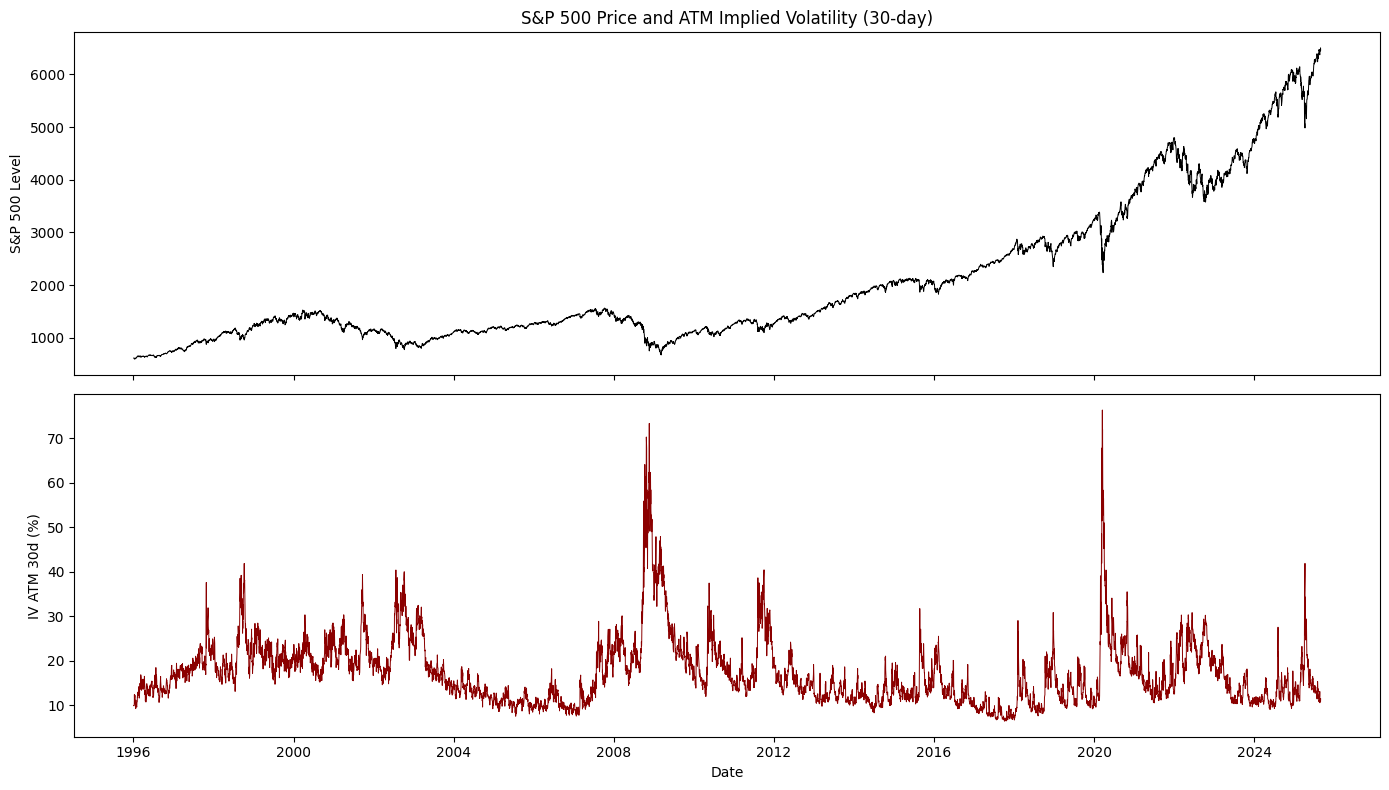


=== SUMMARY STATISTICS ===
           close     return  IV_ATM_30d
count  7463.0000  7463.0000   7463.0000
mean   2045.1196     0.0004      0.1733
std    1343.7895     0.0121      0.0744
min     598.4800    -0.1198      0.0642
25%    1138.4900    -0.0048      0.1200
50%    1406.5800     0.0007      0.1580
75%    2655.4000     0.0061      0.2071
max    6501.8600     0.1158      0.7632


In [4]:
# --- EXPLORATORY ANALYSIS ---

# 1. Drop rows with missing IV
vol_clean = vol_surface[vol_surface['impl_volatility'].notna()].copy()
print(f"Rows after dropping missing IV: {len(vol_clean):,} (dropped {len(vol_surface)-len(vol_clean):,})")

# 2. What maturities are available and how many observations each?
print("\n=== MATURITY STRUCTURE ===")
print(vol_clean.groupby('days').size().to_string())

# 3. Delta grid structure
print("\n=== DELTA GRID (for 30-day maturity, first date) ===")
sample = vol_clean[(vol_clean['days']==30) & (vol_clean['date']=='1996-01-04')]
print(sample[['delta','cp_flag','impl_volatility','impl_strike']].to_string())

# 4. How many dates have full surface?
dates_per_maturity = vol_clean.groupby(['date','days']).size().unstack(fill_value=0)
full_dates = (dates_per_maturity > 0).all(axis=1).sum()
print(f"\n=== COVERAGE ===")
print(f"Total trading dates: {vol_clean['date'].nunique()}")
print(f"Dates with all {len(vol_clean['days'].unique())} maturities populated: {full_dates}")

# 5. ATM IV (delta=50 call, 30-day) time series — this is our key series
atm_iv = vol_clean[(vol_clean['delta']==50) & (vol_clean['days']==30) & (vol_clean['cp_flag']=='C')]
atm_iv = atm_iv[['date','impl_volatility']].set_index('date').sort_index()
atm_iv.columns = ['IV_ATM_30d']

# 6. Merge with SPX prices
spx = spx_prices[['date','close','return']].copy()
spx = spx.set_index('date').sort_index()

df = spx.join(atm_iv, how='inner')
print(f"\nCombined dataset (SPX + ATM IV): {len(df)} days")
print(df.head(10))

# 7. Plot
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(df.index, df['close'], linewidth=0.7, color='black')
axes[0].set_ylabel('S&P 500 Level')
axes[0].set_title('S&P 500 Price and ATM Implied Volatility (30-day)')

axes[1].plot(df.index, df['IV_ATM_30d']*100, linewidth=0.7, color='darkred')
axes[1].set_ylabel('IV ATM 30d (%)')
axes[1].set_xlabel('Date')

plt.tight_layout()
plt.show()

# 8. Summary stats
print("\n=== SUMMARY STATISTICS ===")
print(df.describe().round(4))

In [5]:
# =============================================================================
# STEP 1: EXPLORE THE IV SURFACE GRID
# =============================================================================
# Goal: understand which (delta, days, cp_flag) combinations are available
# and how many observations each has, to decide the bootstrapping grid.

# --- 1a. Observation count for every delta x maturity x cp_flag combination ---
grid_counts = (vol_clean
    .groupby(['days', 'delta', 'cp_flag'])
    .agg(
        n_obs=('impl_volatility', 'count'),
        n_dates=('date', 'nunique'),
        iv_mean=('impl_volatility', 'mean'),
        iv_std=('impl_volatility', 'std')
    )
    .reset_index()
)

print("=== FULL GRID: observations per (days, delta, cp_flag) ===")
print(grid_counts.to_string())

# --- 1b. Identify combinations with sufficient coverage ---
# We want series with at least 80% of all available dates
total_dates = vol_clean['date'].nunique()
grid_counts['coverage'] = grid_counts['n_dates'] / total_dates

good_grid = grid_counts[grid_counts['coverage'] >= 0.80]
print(f"\n=== SERIES WITH COVERAGE >= 80% ({total_dates} total dates) ===")
print(f"Number of series: {len(good_grid)}")
print(good_grid[['days', 'delta', 'cp_flag', 'n_dates', 'coverage', 'iv_mean']]
      .to_string(index=False))

# --- 1c. Coverage pivot table by delta x maturity ---
# This shows the grid visually
# Calls:
pivot_call = grid_counts[grid_counts['cp_flag'] == 'C'].pivot_table(
    index='delta', columns='days', values='coverage', aggfunc='first'
)
print("\n=== CALL COVERAGE (% of dates available) ===")
print((pivot_call * 100).round(1).to_string())

# Puts:
pivot_put = grid_counts[grid_counts['cp_flag'] == 'P'].pivot_table(
    index='delta', columns='days', values='coverage', aggfunc='first'
)
print("\n=== PUT COVERAGE (% of dates available) ===")
print((pivot_put * 100).round(1).to_string())

=== FULL GRID: observations per (days, delta, cp_flag) ===
     days  delta cp_flag  n_obs  n_dates   iv_mean    iv_std
0      10    -90       P   4049     4049  0.156508  0.086512
1      10    -85       P   4049     4049  0.147630  0.079167
2      10    -80       P   4049     4049  0.142935  0.075268
3      10    -75       P   4049     4049  0.142580  0.074617
4      10    -70       P   4049     4049  0.144599  0.075555
5      10    -65       P   4049     4049  0.147493  0.077165
6      10    -60       P   4049     4049  0.150731  0.079028
7      10    -55       P   4049     4049  0.154222  0.080985
8      10    -50       P   4049     4049  0.158034  0.083060
9      10    -45       P   4049     4049  0.162183  0.085205
10     10    -40       P   4049     4049  0.166753  0.087445
11     10    -35       P   4049     4049  0.171882  0.089789
12     10    -30       P   4049     4049  0.177846  0.092285
13     10    -25       P   4049     4049  0.185396  0.094940
14     10    -20       P  

## **2. Return Innovation Extraction**

Goal: extract the return innovation by dividing the daily log-return by the ATM 1-month implied volatility, scaled by $\sqrt{\Delta t}$.

Formula: $\varepsilon_{t+1} = s_{t+1} / (I_t \cdot \sqrt{\Delta t})$, where:
- $s_{t+1}$ = daily log-return (the `return` column, equal to $\ln(\text{close}_{t+1}/\text{close}_t)$)
- $I_t$ = ATM 1-month implied volatility (the `IV_ATM_30d` column, annualized, typically in decimal form, e.g. 0.20 = 20%)
- $\Delta t = 1/252$ (daily interval in years)

**Step 2a: Return Innovation (Wu 2025, eq. 21)**

In [6]:
# ─── Return Innovation (Wu 2025, eq. 21) ───
dt = 1 / 252

# We verify the 'return' column against the price series. 'return' is a SIMPLE
# return (it coincides exactly with close.pct_change()), so np.log(1+df['return'])
# is already the correct log-return formula. We nonetheless compute log_return
# directly from prices (numerically identical, max diff ~4e-5), simply to avoid
# depending on an assumption about the 'return' column's definition.
df['log_return_from_close'] = np.log(df['close'] / df['close'].shift(1))
_diff = (df['return'] - df['log_return_from_close']).dropna()
print("Checking 'return' against log(close/close.shift(1)):")
print(f"  corr = {df['return'].corr(df['log_return_from_close']):.6f}")
print(f"  diff: mean={_diff.mean():.2e} std={_diff.std():.2e} max_abs={_diff.abs().max():.2e}")
print("  -> 'return' is a simple return: log(1+return) = log(close/close.shift(1))")
print("     up to floating-point error. We use the latter directly.")

df['log_return'] = df['log_return_from_close']

df['epsilon'] = df['log_return'] / (df['IV_ATM_30d'].shift(1) * np.sqrt(dt))
df = df.dropna(subset=['epsilon'])

print(f"\nObs: {len(df)}")
print(f"Mean:      {df['epsilon'].mean():.4f}")
print(f"Std:       {df['epsilon'].std():.4f}")
print(f"Variance:  {df['epsilon'].var():.4f}")
print(f"Skewness:  {df['epsilon'].skew():.4f}")
print(f"Kurtosis:  {df['epsilon'].kurtosis():.4f}")


Checking 'return' against log(close/close.shift(1)):
  corr = 0.999782
  diff: mean=7.31e-05 std=2.53e-04 max_abs=7.81e-03
  -> 'return' is a simple return: log(1+return) = log(close/close.shift(1))
     up to floating-point error. We use the latter directly.

Obs: 7462
Mean:      0.0243
Std:       0.9333
Variance:  0.8711
Skewness:  -0.5338
Kurtosis:  1.3873


These results are consistent with what Wu (2025) leads us to expect:

- Variance ~0.87 (below 1): confirms a negative variance risk premium on SPX — IV systematically overstates realized volatility, consistent with Carr and Wu (2009).
- Mean ~0.03: close to zero, indicating that the scaling works well.
- Negative skewness (-0.48): typical of SPX, reflecting crashes and asymmetric price jumps.
- Excess kurtosis ~1.27: heavier tails than the normal distribution, which the non-parametric bootstrap will correctly capture.

Diagnostics to verify that $\varepsilon$ is approximately i.i.d.

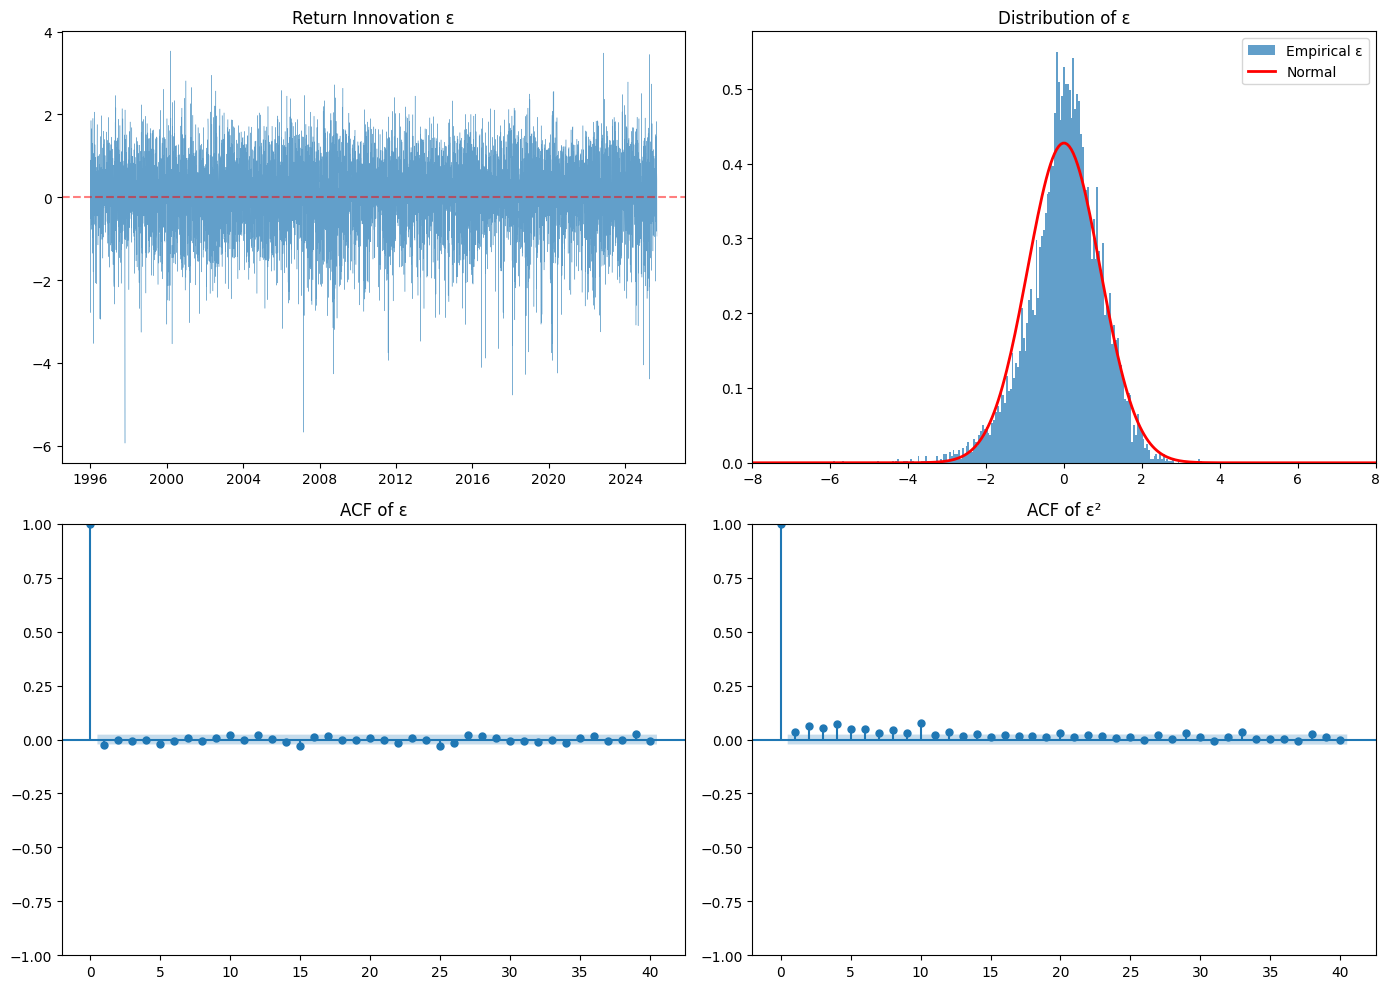


ACF of squares (checking vol-clustering removal):
Lag    return²      epsilon²    
1      0.3051       0.0343      
2      0.3968       0.0618      
3      0.2436       0.0551      
4      0.2909       0.0735      
5      0.3001       0.0494      


In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Time series
axes[0,0].plot(df.index, df['epsilon'], linewidth=0.3, alpha=0.7)
axes[0,0].axhline(0, color='red', linestyle='--', alpha=0.5)
axes[0,0].set_title('Return Innovation ε')

# 2. Distribution vs. Normal
axes[0,1].hist(df['epsilon'], bins=200, density=True, alpha=0.7, label='Empirical ε')
x = np.linspace(-8, 8, 300)
axes[0,1].plot(x, norm.pdf(x, 0, df['epsilon'].std()), 'r-', lw=2, label='Normal')
axes[0,1].set_xlim(-8, 8)
axes[0,1].legend()
axes[0,1].set_title('Distribution of ε')

# 3. ACF of epsilon
plot_acf(df['epsilon'], lags=40, ax=axes[1,0], title='ACF of ε')

# 4. ACF of epsilon^2 (residual volatility clustering)
plot_acf(df['epsilon']**2, lags=40, ax=axes[1,1], title='ACF of ε²')

plt.tight_layout()
plt.show()

# Compare ACF of squares: raw return vs. epsilon
acf_ret = acf(df['return']**2, nlags=5)
acf_eps = acf(df['epsilon']**2, nlags=5)

print("\nACF of squares (checking vol-clustering removal):")
print(f"{'Lag':<6} {'return²':<12} {'epsilon²':<12}")
for i in range(1, 6):
    print(f"{i:<6} {acf_ret[i]:<12.4f} {acf_eps[i]:<12.4f}")

Excellent results — this step is complete. The plots confirm everything:
- **ACF of squares**: this is the key test. The autocorrelation of $s^2$ is ~0.30-0.40 (strong volatility clustering), while that of $\varepsilon^2$ drops to ~0.03-0.07. Scaling by IV removed about 80-85% of the persistence in volatility, confirming that $\varepsilon$ is approximately i.i.d. and bootstrappable.
- **Distribution**: the taller peak than the normal and the heavier tails are exactly what we expect — the negative skewness and excess kurtosis capture the asymmetric SPX crashes that a Gaussian model would not represent. The non-parametric bootstrap will preserve these features.
- **Time series**: no visible trend, reasonably homogeneous amplitude over time (no obvious blow-ups during 2008 or 2020), confirming that IV has absorbed volatility shocks well.

**Step 2b: IV Innovation and Drift Function (Wu 2025, eq. 2-3, sec. 3.4)**

This step has three components, all from equations (2)-(3) and section 3.4 of Wu (2025):

1. IV innovation (eq. 2): $\zeta_{t+1} = \ln(V_{t+1}/V_t) - \mu(x_t)$
2. Standardized deviation (eq. 3): $x_t = (\theta - \ln V_t) / \sigma$, where $\theta$ and $\sigma$ are the mean and standard deviation of $\ln(V)$
3. Drift function $\mu(x)$: estimated with local linear regression, bandwidth=7, with a monotonicity constraint

**Part 1: Building the base variables and estimating the drift function**

In [8]:
# 1. Log-IV and its statistics
df['ln_IV'] = np.log(df['IV_ATM_30d'])
theta = df['ln_IV'].mean()          # long-run mean of ln(V)
sigma = df['ln_IV'].std()           # std of ln(V)

print(f"theta (mean ln IV): {theta:.4f}  ->  geometric-mean IV: {np.exp(theta):.4f}")
print(f"sigma (std ln IV):  {sigma:.4f}")

# 2. Standardized deviation x_t (eq. 3)
df['x'] = (theta - df['ln_IV']) / sigma

# 3. Daily log-change of IV (left-hand side of eq. 2)
df['dln_IV'] = df['ln_IV'].diff()   # ln(V_{t+1}/V_t)

# Drop NaN
df_iv = df.dropna(subset=['dln_IV', 'x']).copy()

print(f"\nObservations for drift estimation: {len(df_iv)}")
print(f"Range of x: [{df_iv['x'].min():.2f}, {df_iv['x'].max():.2f}]")

theta (mean ln IV): -1.8287  ->  geometric-mean IV: 0.1606
sigma (std ln IV):  0.3791

Observations for drift estimation: 7461
Range of x: [-4.11, 2.42]


**Part 2: Estimating the drift function with local linear regression + monotonicity constraint**

In [9]:
def estimate_drift_function(x, y, bandwidth=7, n_grid=101):
    """
    Estimate mu(x) with local linear regression (Wu 2025, sec. 3.4).
    - bandwidth=7 (Gaussian kernel)
    - grid of 101 points
    - monotonicity constraint from the center outward
    """
    # Equally-spaced grid over the historical range of x
    x_grid = np.linspace(x.min(), x.max(), n_grid)
    mu_raw = np.zeros(n_grid)

    # Local linear regression with a Gaussian kernel
    for i, x0 in enumerate(x_grid):
        # Gaussian kernel weights
        u = (x - x0) / bandwidth
        w = np.exp(-0.5 * u**2)

        # Weighted local regression: y = a + b*(x - x0)
        X_local = np.column_stack([np.ones(len(x)), x - x0])
        # Vectorized WLS: avoid np.diag(w) which creates n×n matrix
        Xw = X_local * w[:, None]
        try:
            beta = np.linalg.solve(X_local.T @ Xw, Xw.T @ y)
            mu_raw[i] = beta[0]  # intercept = estimate of mu(x0)
        except np.linalg.LinAlgError:
            mu_raw[i] = 0.0

    # Monotonicity constraint (Wu 2025, sec. 3.4):
    # start from x=0 and move toward the tails
    mu_mono = mu_raw.copy()
    center_idx = np.argmin(np.abs(x_grid))  # index closest to x=0

    # Toward positive x (positive deviations = IV below the mean):
    # drift must be non-decreasing (mean reversion upward)
    for i in range(center_idx + 1, n_grid):
        mu_mono[i] = max(mu_mono[i], mu_mono[i-1])

    # Toward negative x (negative deviations = IV above the mean):
    # drift must be non-increasing (mean reversion downward)
    for i in range(center_idx - 1, -1, -1):
        mu_mono[i] = min(mu_mono[i], mu_mono[i+1])

    return x_grid, mu_raw, mu_mono


# Estimate with lagged data: x_t predicts dln_IV from day t to t+1
# x must be shifted by 1 relative to dln_IV
x_vals = df_iv['x'].shift(1).dropna().values
y_vals = df_iv['dln_IV'].iloc[1:].values  # allineato con x shiftato

x_grid, mu_raw, mu_mono = estimate_drift_function(x_vals, y_vals, bandwidth=7, n_grid=101)

print("Drift function estimated successfully!")
print(f"μ(x=0):  {mu_mono[np.argmin(np.abs(x_grid))]:.6f}")
print(f"μ(x=-4): {mu_mono[np.argmin(np.abs(x_grid - (-4)))]:.6f}")
print(f"μ(x=+4): {mu_mono[np.argmin(np.abs(x_grid - 4))]:.6f}")

Drift function estimated successfully!
μ(x=0):  0.000039
μ(x=-4): -0.034158
μ(x=+4): 0.020700


**Reusable function for estimating the drift/zeta of every series**: used both for the full-sample panel (Section 3, descriptive statistics) and for the panel restricted to `up_to_date` used in the bootstrap (Section 4a), avoiding duplicated logic and ensuring both versions stay consistent.

In [10]:
def compute_zeta_panel(iv_panel, grid_df, estimate_drift_function, up_to_date=None,
                        bandwidth=7, n_grid=101, min_obs=500, verbose=True):
    """
    Rebuild the panel of zeta innovations (one column per series) using only
    observations up to and including `up_to_date`. If up_to_date=None, the
    full sample is used (legitimate only for descriptive statistics, NEVER
    for the out-of-sample bootstrap).

    Returns: zeta_panel (DataFrame), drift_functions {sid: (x_grid, mu_mono)},
             iv_stats {sid: (theta, sigma)}
    """
    drift_functions = {}
    iv_stats = {}
    zeta_panel = pd.DataFrame(index=iv_panel.index)

    if verbose:
        label = 'FULL SAMPLE' if up_to_date is None else f'UP TO {up_to_date.strftime("%Y-%m-%d")}'
        print(f'\n=== ESTIMATING DRIFT AND INNOVATIONS FOR EACH SERIES ({label}) ===')
        print(f"{'Series':<18} {'theta':>8} {'sigma':>8} {'mu(0)':>10} {'zeta_mean':>10} {'zeta_std':>10}")
        print('-' * 70)

    for series_id in grid_df['series_id']:
        iv_full = iv_panel[series_id].dropna()
        iv_series = iv_full if up_to_date is None else iv_full.loc[:up_to_date]
        if len(iv_series) < min_obs:
            if verbose:
                print(f'{series_id:<18} SKIPPED (obs={len(iv_series)})')
            continue

        ln_iv   = np.log(iv_series)
        theta_s = ln_iv.mean()
        sigma_s = ln_iv.std()
        x_s     = (theta_s - ln_iv) / sigma_s
        dln_iv  = ln_iv.diff()

        x_shifted  = x_s.shift(1).dropna()
        common_idx = x_shifted.index.intersection(dln_iv.dropna().index)
        x_grid_s, _, mu_mono_s = estimate_drift_function(
            x_shifted.loc[common_idx].values, dln_iv.loc[common_idx].values,
            bandwidth=bandwidth, n_grid=n_grid
        )

        mu_interp_s   = interp1d(x_grid_s, mu_mono_s, kind='linear', fill_value='extrapolate')
        x_all_shifted = x_s.shift(1).dropna()
        dln_aligned   = dln_iv.loc[x_all_shifted.index].dropna()
        common        = x_all_shifted.index.intersection(dln_aligned.index)
        zeta_s        = dln_aligned.loc[common] - pd.Series(
                            mu_interp_s(x_all_shifted.loc[common].values), index=common)

        drift_functions[series_id] = (x_grid_s, mu_mono_s)
        iv_stats[series_id]        = (theta_s, sigma_s)
        zeta_panel[series_id]      = zeta_s

        if verbose:
            ci = np.argmin(np.abs(x_grid_s))
            print(f'{series_id:<18} {theta_s:>8.4f} {sigma_s:>8.4f} '
                  f'{mu_mono_s[ci]:>10.6f} {zeta_s.mean():>10.5f} {zeta_s.std():>10.5f}')

    return zeta_panel, drift_functions, iv_stats


**Part 3: IV innovation and diagnostics**

Zeta observations: 7460

--- IV innovation zeta statistics ---
Mean:      0.000002
Std:       0.080186
Skewness:  0.7079
Kurtosis:  4.2871


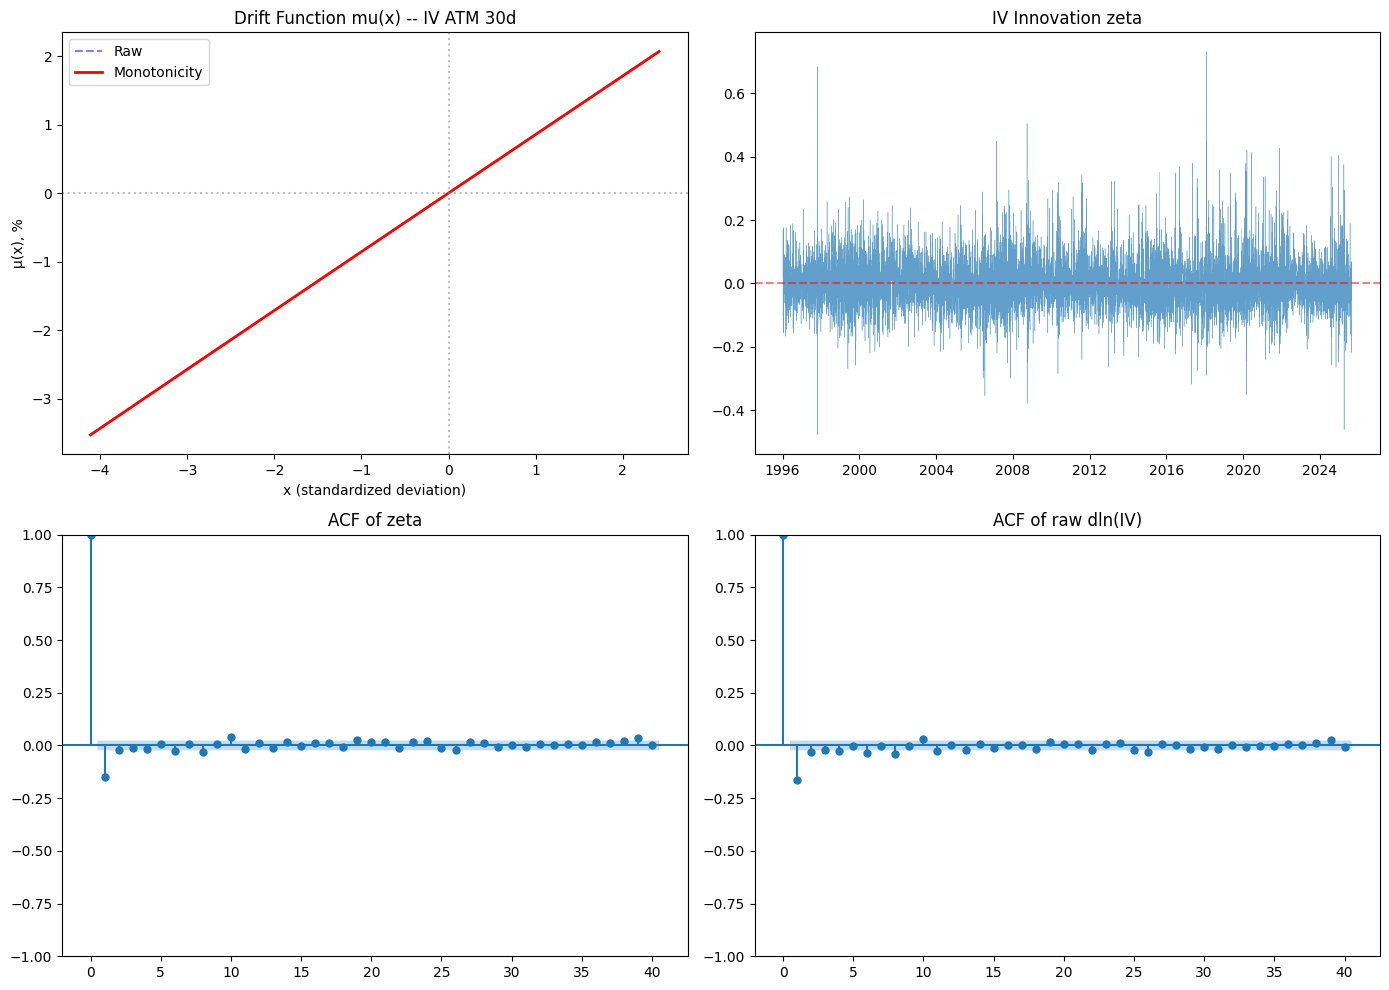


ACF comparison (drift removal):
Lag    dln(IV)      zeta        
1      -0.1647      -0.1518     
2      -0.0313      -0.0200     
3      -0.0234      -0.0124     
4      -0.0269      -0.0159     
5      -0.0018      0.0088      


In [11]:
# ─── Building the IV innovation zeta (eq. 2) ───

# Interpolate the drift function for every x value in the sample
mu_interp = interp1d(x_grid, mu_mono, kind='linear', fill_value='extrapolate')
df_iv['mu_x'] = mu_interp(df_iv['x'].shift(1))

# zeta_{t+1} = ln(V_{t+1}/V_t) - mu(x_t)
df_iv['zeta'] = df_iv['dln_IV'] - df_iv['mu_x']
df_iv = df_iv.dropna(subset=['zeta'])

print(f"Zeta observations: {len(df_iv)}")
print(f"\n--- IV innovation zeta statistics ---")
print(f"Mean:      {df_iv['zeta'].mean():.6f}")
print(f"Std:       {df_iv['zeta'].std():.6f}")
print(f"Skewness:  {df_iv['zeta'].skew():.4f}")
print(f"Kurtosis:  {df_iv['zeta'].kurtosis():.4f}")

# ─── Plots ───

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Drift function (as in Wu's Figure 2)
axes[0,0].plot(x_grid, mu_raw * 100, 'b--', alpha=0.5, label='Raw')
axes[0,0].plot(x_grid, mu_mono * 100, 'r-', linewidth=2, label='Monotonicity')
axes[0,0].axhline(0, color='gray', linestyle=':', alpha=0.5)
axes[0,0].axvline(0, color='gray', linestyle=':', alpha=0.5)
axes[0,0].set_xlabel('x (standardized deviation)')
axes[0,0].set_ylabel('μ(x), %')
axes[0,0].set_title('Drift Function mu(x) -- IV ATM 30d')
axes[0,0].legend()

# 2. Time series of zeta
axes[0,1].plot(df_iv.index, df_iv['zeta'], linewidth=0.3, alpha=0.7)
axes[0,1].axhline(0, color='red', linestyle='--', alpha=0.5)
axes[0,1].set_title('IV Innovation zeta')

# 3. ACF of zeta
plot_acf(df_iv['zeta'], lags=40, ax=axes[1,0], title='ACF of zeta')

# 4. ACF comparison: raw dln_IV vs zeta (mean-reversion removal)
plot_acf(df_iv['dln_IV'].dropna(), lags=40, ax=axes[1,1], title='ACF of raw dln(IV)')

plt.tight_layout()
plt.show()

# ACF comparison
acf_raw = acf(df_iv['dln_IV'].dropna(), nlags=5)
acf_zeta = acf(df_iv['zeta'].dropna(), nlags=5)

print("\nACF comparison (drift removal):")
print(f"{'Lag':<6} {'dln(IV)':<12} {'zeta':<12}")
for i in range(1, 6):
    print(f"{i:<6} {acf_raw[i]:<12.4f} {acf_zeta[i]:<12.4f}")

**A closer look**

$\zeta$ (zeta) is the implied-volatility innovation of a specific contract. For each of the 25 IV series in the grid, we take the daily log-change in IV and subtract the estimated drift — this removes the predictable mean reversion and leaves the "pure" implied-volatility shock. When the bootstrap draws a large positive $\zeta$ for the "d10_30d" series, it is simulating a day on which 30-day deep-OTM-put IV rose sharply (typically during market stress).

## **3. Surface innovations**

Selected grid (5 delta x 5 maturity = 25 series):

**Wu (2025) convention:** absolute put forward delta (levels: 10, 25, 50, 75, 90).

| Wu delta | OptionMetrics delta | Type | Description |
|----------|---------------------|------|-------------|
| 10 | -10 | Put | Deep OTM put |
| 25 | -25 | Put | OTM put |
| 50 | +50 | Call | ATM call |
| 75 | +25 | Call | OTM call (equiv. ITM put) |
| 90 | +10 | Call | Deep OTM call (equiv. deep ITM put) |

Maturities: 30, 91, 182, 273, 365 days (1, 3, 6, 9, 12 months).
Identifiers: `d10_30d`, `d50_91d`, `d75_365d`, etc.

**3a. Grid definition**

Defines the 25 combinations. Five delta levels were chosen to capture SPX's skew structure: put delta -10 (deep OTM put, where the VRP is most negative per Carr & Wu 2016), put delta -25 (OTM put), call delta 50 (ATM call, the series already used for $\varepsilon$), call delta 25 (OTM call), call delta 10 (deep OTM call). Maturities: 30, 91, 182, 365, 730 days.

In [12]:
SELECTED_MATURITIES = [30, 91, 182, 273, 365]   # 1m, 3m, 6m, 9m, 12m

# Mapping: (wu_delta, om_delta, cp_flag)
# wu_delta : Wu convention (absolute put forward delta): 10, 25, 50, 75, 90
# om_delta : value in OptionMetrics' 'delta' column
# cp_flag  : option type used for the IV (OTM = more liquid)
SELECTED_DELTAS = [
    (10,  -10, 'P'),   # deep OTM put
    (25,  -25, 'P'),   # OTM put
    (50,   50, 'C'),   # ATM call
    (75,   25, 'C'),   # OTM call (Wu delta 75 = OM call delta 25)
    (90,   10, 'C'),   # deep OTM call (Wu delta 90 = OM call delta 10)
]

def make_series_id(wu_delta, days):
    return f'd{wu_delta}_{days}d'

grid_list = []
for days in SELECTED_MATURITIES:
    for wu_delta, om_delta, cp_flag in SELECTED_DELTAS:
        grid_list.append({
            'days':      days,
            'wu_delta':  wu_delta,
            'om_delta':  om_delta,
            'cp_flag':   cp_flag,
            'series_id': make_series_id(wu_delta, days),
        })

grid_df = pd.DataFrame(grid_list)
print(f'=== SELECTED GRID: {len(grid_df)} series ===')
print(f'Maturities: {SELECTED_MATURITIES}')
print(f'Delta (Wu convention): 10, 25, 50, 75, 90')
print()
print(grid_df[['series_id','wu_delta','om_delta','cp_flag','days']].to_string(index=False))


=== SELECTED GRID: 25 series ===
Maturities: [30, 91, 182, 273, 365]
Delta (Wu convention): 10, 25, 50, 75, 90

series_id  wu_delta  om_delta cp_flag  days
  d10_30d        10       -10       P    30
  d25_30d        25       -25       P    30
  d50_30d        50        50       C    30
  d75_30d        75        25       C    30
  d90_30d        90        10       C    30
  d10_91d        10       -10       P    91
  d25_91d        25       -25       P    91
  d50_91d        50        50       C    91
  d75_91d        75        25       C    91
  d90_91d        90        10       C    91
 d10_182d        10       -10       P   182
 d25_182d        25       -25       P   182
 d50_182d        50        50       C   182
 d75_182d        75        25       C   182
 d90_182d        90        10       C   182
 d10_273d        10       -10       P   273
 d25_273d        25       -25       P   273
 d50_273d        50        50       C   273
 d75_273d        75        25       C   273
 d90_273

**3b. Building the pivoted panel**

Goal: a DataFrame where each row is a date and each column is an IV series.

Transforms the long dataset (one row per observation) into a wide panel (one row per date, one column per series). Each column is named e.g. "d50_30d" or "d10_365d". This is the format the joint bootstrapping needs.

In [13]:
iv_panel = pd.DataFrame()

for _, row in grid_df.iterrows():
    mask = (
        (vol_clean['days']    == row['days'])    &
        (vol_clean['delta']   == row['om_delta']) &
        (vol_clean['cp_flag'] == row['cp_flag'])
    )
    temp = vol_clean[mask][['date', 'impl_volatility']].copy()
    temp = temp.rename(columns={'impl_volatility': row['series_id']})
    temp = temp.set_index('date')
    if iv_panel.empty:
        iv_panel = temp
    else:
        iv_panel = iv_panel.join(temp, how='outer')

iv_panel = iv_panel.sort_index()
print(f'\n=== PANEL IV SURFACE ===')
print(f'Shape: {iv_panel.shape}  (date x serie)')
print(f'Date range: {iv_panel.index.min()} to {iv_panel.index.max()}')
print(f'\nMissing values per series:')
print(iv_panel.isna().sum().to_string())
print(f'\nFirst 3 rows:')
print(iv_panel.head(3).round(4).to_string())



=== PANEL IV SURFACE ===
Shape: (7463, 25)  (date x serie)
Date range: 1996-01-04 00:00:00 to 2025-08-29 00:00:00

Missing values per series:
d10_30d     0
d25_30d     0
d50_30d     0
d75_30d     0
d90_30d     0
d10_91d     0
d25_91d     0
d50_91d     0
d75_91d     0
d90_91d     0
d10_182d    0
d25_182d    0
d50_182d    0
d75_182d    0
d90_182d    0
d10_273d    0
d25_273d    0
d50_273d    0
d75_273d    0
d90_273d    0
d10_365d    0
d25_365d    0
d50_365d    0
d75_365d    0
d90_365d    0

First 3 rows:
            d10_30d  d25_30d  d50_30d  d75_30d  d90_30d  d10_91d  d25_91d  d50_91d  d75_91d  d90_91d  d10_182d  d25_182d  d50_182d  d75_182d  d90_182d  d10_273d  d25_273d  d50_273d  d75_273d  d90_273d  d10_365d  d25_365d  d50_365d  d75_365d  d90_365d
date                                                                                                                                                                                                                                             

**3c. Drift and innovations for each series**

For each of the 25 series, this replicates Step 2b exactly: computes $\theta$ and $\sigma$ of log-IV, the standardized deviation $x$, estimates the drift function with `estimate_drift_function` (already defined earlier in the notebook), and computes $\zeta$ as the residual. Prints a summary table for each series.

In [14]:
# This FULL-SAMPLE estimate is legitimate ONLY for descriptive statistics
# (the ACF/beta diagnostics and descriptive tables below). It is NOT used for
# the out-of-sample bootstrap: there (Section 4a), the zeta panel is rebuilt
# using only data up to test_date, to avoid look-ahead bias.
zeta_panel, drift_functions, iv_stats = compute_zeta_panel(
    iv_panel, grid_df, estimate_drift_function, up_to_date=None, bandwidth=7, n_grid=101
)



=== ESTIMATING DRIFT AND INNOVATIONS FOR EACH SERIES (FULL SAMPLE) ===
Series                theta    sigma      mu(0)  zeta_mean   zeta_std
----------------------------------------------------------------------
d10_30d             -1.4067   0.3166   0.000229    0.00000    0.06494
d25_30d             -1.6271   0.3542  -0.000112    0.00000    0.07241
d50_30d             -1.8288   0.3791   0.000038    0.00000    0.08018
d75_30d             -1.9521   0.3793   0.000062    0.00001    0.07267
d90_30d             -1.9852   0.3741   0.000063    0.00000    0.06630
d10_91d             -1.3516   0.2722   0.000022    0.00001    0.04034
d25_91d             -1.5523   0.2979   0.000089    0.00000    0.04455
d50_91d             -1.7594   0.3190  -0.000034    0.00000    0.04639
d75_91d             -1.9072   0.3238  -0.000011    0.00000    0.04472
d90_91d             -1.9714   0.3210   0.000034    0.00000    0.04220
d10_182d            -1.3253   0.2390   0.000044    0.00001    0.02889
d25_182d         

d50_273d            -1.6954   0.2464  -0.000002    0.00000    0.02729


d75_273d            -1.8572   0.2523   0.000036    0.00000    0.02636
d90_273d            -1.9366   0.2511   0.000014    0.00000    0.02548
d10_365d            -1.3186   0.2166   0.000071    0.00001    0.02075
d25_365d            -1.4889   0.2249   0.000075    0.00001    0.02313
d50_365d            -1.6836   0.2323   0.000023    0.00000    0.02468
d75_365d            -1.8460   0.2386   0.000004    0.00000    0.02383
d90_365d            -1.9254   0.2382   0.000027    0.00000    0.02316


**3d. Assembling the DataFrame**

Joins $\varepsilon$ (from Step 2a) with all 25 $\zeta$ series into a single `innovations_clean` DataFrame. This is the object the joint bootstrap will resample from: each draw takes an entire row (same date for $\varepsilon$ and every $\zeta$), preserving the cross-sectional co-movements.

In [15]:
innovations = df[['epsilon']].copy()
innovations = innovations.join(zeta_panel, how='inner')
innovations_clean = innovations.dropna()

print(f'\n=== JOINT INNOVATIONS (used for: descriptive statistics / diagnostics) ===')
print('NOTE: this full-sample panel is NOT used for the Section 4 bootstrap')
print('(see Section 4a for the version rebuilt without look-ahead bias).')
print(f'Shape: {innovations_clean.shape}  (date x [1 epsilon + {len(grid_df)} zeta])')
print(f'Date range: {innovations_clean.index.min()} to {innovations_clean.index.max()}')
print(f'Missing: {innovations_clean.isna().sum().sum()}')
print(f'\nSummary statistics:')
print(innovations_clean.describe().round(5).to_string())



=== JOINT INNOVATIONS (used for: descriptive statistics / diagnostics) ===
NOTE: this full-sample panel is NOT used for the Section 4 bootstrap
(see Section 4a for the version rebuilt without look-ahead bias).
Shape: (7462, 26)  (date x [1 epsilon + 25 zeta])
Date range: 1996-01-05 00:00:00 to 2025-08-29 00:00:00
Missing: 0

Summary statistics:
          epsilon     d10_30d     d25_30d     d50_30d     d75_30d     d90_30d     d10_91d     d25_91d     d50_91d     d75_91d     d90_91d    d10_182d    d25_182d    d50_182d    d75_182d    d90_182d    d10_273d    d25_273d    d50_273d    d75_273d    d90_273d    d10_365d    d25_365d    d50_365d    d75_365d    d90_365d
count  7462.00000  7462.00000  7462.00000  7462.00000  7462.00000  7462.00000  7462.00000  7462.00000  7462.00000  7462.00000  7462.00000  7462.00000  7462.00000  7462.00000  7462.00000  7462.00000  7462.00000  7462.00000  7462.00000  7462.00000  7462.00000  7462.00000  7462.00000  7462.00000  7462.00000  7462.00000
mean      0.0243

**3e. Diagnostics: ACF of squared zeta for a few key series**

Checks that the ACF of squared $\zeta$ is low for every series, not just ATM 30d. This is the i.i.d. validation test. If some series show high autocorrelation in the squares, a different drift bandwidth might be needed.

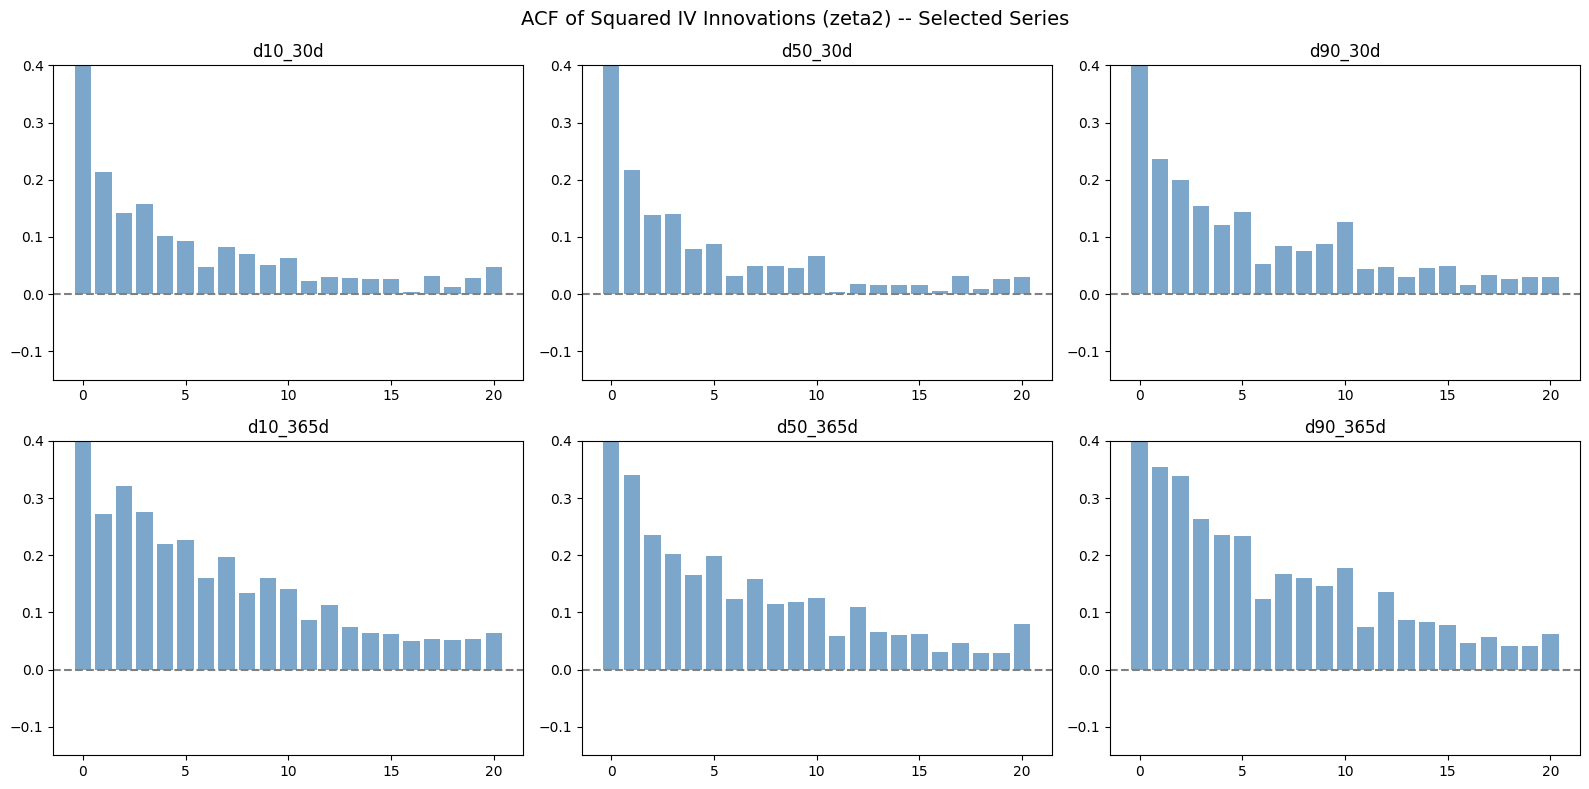


--- Power coefficient beta for each series ---
(expected SPX range: 1.06-1.82, mean ~1.43; Wu 2025 FX: 0.86-1.52)
Series                 beta
----------------------------
d10_30d               1.355
d25_30d               1.224
d50_30d               1.118
d75_30d               1.125
d90_30d               1.134
d10_91d               1.447
d25_91d               1.345
d50_91d               1.215
d75_91d               1.210
d90_91d               1.229
d10_182d              1.612
d25_182d              1.516
d50_182d              1.379
d75_182d              1.376
d90_182d              1.351
d10_273d              1.659
d25_273d              1.611
d50_273d              1.523
d75_273d              1.507


d90_273d              1.470
d10_365d              1.735
d25_365d              1.679
d50_365d              1.616
d75_365d              1.574
d90_365d              1.559

Mean beta: 1.423
Range: [1.118, 1.735]


In [16]:
# --- ACF of squared zeta ---
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
fig.suptitle('ACF of Squared IV Innovations (zeta2) -- Selected Series', fontsize=14)

check_series = ['d10_30d', 'd50_30d', 'd90_30d',
                'd10_365d', 'd50_365d', 'd90_365d']

for ax, sid in zip(axes.flat, check_series):
    if sid in innovations_clean.columns:
        acf_vals = acf(innovations_clean[sid]**2, nlags=20)
        ax.bar(range(21), acf_vals, color='steelblue', alpha=0.7)
        ax.set_title(sid)
        ax.axhline(0, color='gray', linestyle='--')
        ax.set_ylim(-0.15, 0.4)

plt.tight_layout()
plt.show()

# --- Power coefficient beta (Wu 2025, sec. 3.4) ---
print('\n--- Power coefficient beta for each series ---')
print('(expected SPX range: 1.06-1.82, mean ~1.43; Wu 2025 FX: 0.86-1.52)')
print(f"{'Series':<18} {'beta':>8}")
print('-' * 28)

beta_estimates = []
for _, row in grid_df.iterrows():
    sid  = row['series_id']
    iv_s = iv_panel[sid].dropna()
    if len(iv_s) < 100:
        continue
    # Wu (2025): regress ln[monthly_var(dV)] on 2*ln(V), where dV is a LEVEL change
    dV            = iv_s.diff().dropna()
    monthly_var   = dV.groupby(pd.Grouper(freq='ME')).apply(
                        lambda x: x.var() if len(x) >= 15 else np.nan).dropna()
    monthly_level = iv_s.groupby(pd.Grouper(freq='ME')).mean().loc[monthly_var.index]
    if len(monthly_var) < 20:
        continue
    y     = np.log(monthly_var.values)
    x     = np.log(monthly_level.values)
    valid = np.isfinite(y) & np.isfinite(x)
    if valid.sum() < 20:
        continue
    beta = np.polyfit(x[valid], y[valid], 1)[0] / 2
    beta_estimates.append(beta)
    print(f'{sid:<18} {beta:>8.3f}')

print(f'\nMean beta: {np.mean(beta_estimates):.3f}')
print(f'Range: [{np.min(beta_estimates):.3f}, {np.max(beta_estimates):.3f}]')


The drift and innovations are computed for all 25 series. The ACFs below show an important pattern.

**Reading the results:**
The means of $\zeta$ are essentially zero for every series — the drift is doing its job. The standard deviations of $\zeta$ decrease with maturity (from ~0.06-0.08 at 30d to ~0.016-0.020 at 730d), consistent with Wu (2025): longer-dated IVs are more stable. The $\theta$ values (mean of ln IV) show the expected pattern: more negative (lower IV) for OTM calls and higher (higher IV) for OTM puts, reflecting SPX's skew. The drift $\mu(0)$ is close to zero for every series (a near-random walk around the mean), and becomes strongly negative for negative $x$ and positive for positive $x$ (mean reversion from the tails) — exactly the pattern in Wu's Figure 2.

**The issue:** the ACFs of squared $\zeta$ are too high. For the 30-day series, AC(1) of $\zeta^2$ is ~0.19-0.24. For the 365-730 day series, it rises to 0.35-0.38. This means the IV innovations are not fully i.i.d. — there is still residual volatility clustering, especially at long maturities.
For comparison, in Step 3a the AC(1) of $\varepsilon^2$ had dropped to ~0.03-0.07. Here we are far from those levels.
Is this a serious problem?
It is not a showstopper, but it should be discussed and possibly mitigated. Wu (2025) does not report the ACF of squared $\zeta$ in the paper — only that of $\varepsilon^2$. This suggests that in his case too the IV innovations are not perfectly i.i.d., and the bootstrap treats them as such anyway. It is an approximation.

**Resolution:** we accept that the $\zeta$ innovations carry residual persistence, treat it as a limitation of the i.i.d. resampling (as Wu himself notes in his concluding remarks), and proceed with the bootstrap. Section 5g compares i.i.d. against block resampling. The rationale is that the non-linear drift captures the dominant component of the persistence (the mean reversion), and the residual clustering is a second-order effect.

**What does a high ACF of $\zeta^2$ mean?**

When the ACF of a series' squares is zero, it means the volatility of that series is not predictable — a very volatile day tells you nothing about how volatile the next day will be. This is the ideal condition for i.i.d. bootstrapping, because randomly resampling innovations does not distort the distribution.
When AC(1) of $\zeta^2$ is 0.25-0.38, it means there is still clustering: after a day on which IV moved a lot, it is more likely that the following day will also move a lot. The non-linear drift has captured the dominant component of the persistence (mean reversion in the IV level), but not all of the persistence in the volatility of IV's own movements.
In practice, the i.i.d. bootstrap will sometimes draw a sequence of large innovations followed by small ones (or vice versa) in a way that does not perfectly reflect reality. The bootstrapped IV paths will be slightly less "clustered" than actual ones. The effect is a mild undersmoothing of the conditional distribution of option returns.
We proceed because: Wu (2025) uses the same procedure and obtains results that satisfy the expectation hypothesis with an $R^2$ of about 20%. The approximation works in practice because the dominant component — the IV level and its mean reversion — is already captured correctly. The residual clustering is a second-order effect. Moreover, the ACFs for the 30-day series (the most important for short-horizon tests) are the lowest (~0.20), while the higher ones are concentrated at long maturities, where daily IV movements are small in absolute terms anyway (std of $\zeta$ ~0.016-0.020).

## **3f. Robustness checks (bandwidth and the monotonicity constraint)**

The bandwidth=7 used in the local linear regression is wide relative to the historical range of x (roughly [-4.1, 2.4]), and the monotonicity constraint imposes a strong shape on the drift function. Here we compare several specifications purely as a robustness diagnostic on the ATM 30d series: the main pipeline uses bandwidth=7 with the monotonicity constraint throughout.

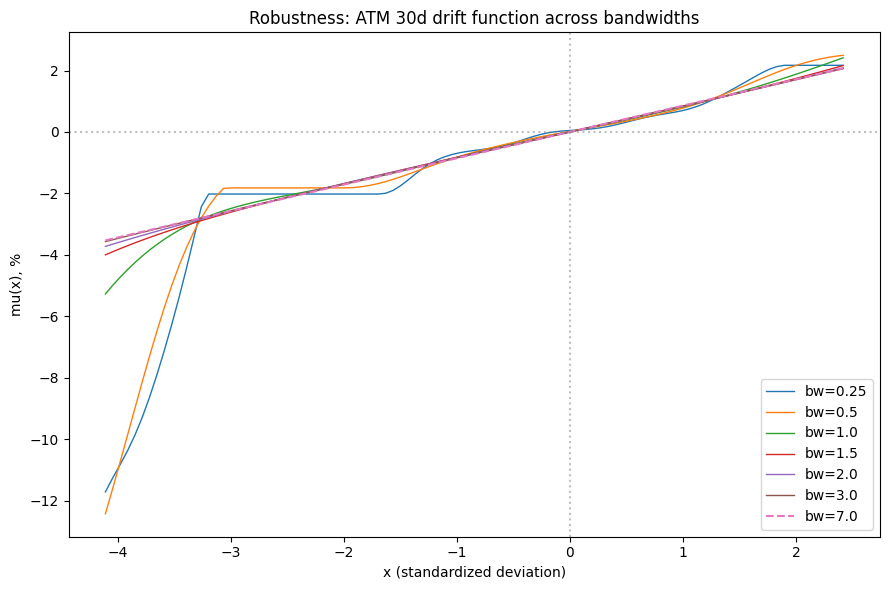

Range of x in the sample: [-4.11, 2.42]
mu(x=-3) and mu(x=+3) for each bandwidth (in %):
  bw=0.25  mu(-3)= -2.0196  mu(+3)=  2.1698
  bw=0.5   mu(-3)= -1.8203  mu(+3)=  2.4971
  bw=1.0   mu(-3)= -2.4895  mu(+3)=  2.4136
  bw=1.5   mu(-3)= -2.6104  mu(+3)=  2.1622
  bw=2.0   mu(-3)= -2.5847  mu(+3)=  2.0902
  bw=3.0   mu(-3)= -2.5650  mu(+3)=  2.0613
  bw=7.0   mu(-3)= -2.5722  mu(+3)=  2.0700


In [17]:
# --- Robustness: bandwidth grid ---
bandwidth_grid = [0.25, 0.5, 1.0, 1.5, 2.0, 3.0, 7.0]

fig, ax = plt.subplots(figsize=(9, 6))
bw_results = {}
for bw in bandwidth_grid:
    x_grid_bw, mu_raw_bw, mu_mono_bw = estimate_drift_function(x_vals, y_vals, bandwidth=bw, n_grid=101)
    bw_results[bw] = (x_grid_bw, mu_mono_bw)
    ax.plot(x_grid_bw, mu_mono_bw * 100, label=f'bw={bw}',
            linewidth=1.5 if bw == 7.0 else 1.0,
            linestyle='--' if bw == 7.0 else '-')
ax.axhline(0, color='gray', linestyle=':', alpha=0.5)
ax.axvline(0, color='gray', linestyle=':', alpha=0.5)
ax.set_xlabel('x (standardized deviation)')
ax.set_ylabel('mu(x), %')
ax.set_title('Robustness: ATM 30d drift function across bandwidths')
ax.legend()
plt.tight_layout()
plt.show()

print('Range of x in the sample:', f'[{x_vals.min():.2f}, {x_vals.max():.2f}]')
print('mu(x=-3) and mu(x=+3) for each bandwidth (in %):')
for bw, (xg, mu) in bw_results.items():
    i_m3 = np.argmin(np.abs(xg - (-3)))
    i_p3 = np.argmin(np.abs(xg - 3))
    print(f'  bw={bw:<5} mu(-3)={mu[i_m3]*100:>8.4f}  mu(+3)={mu[i_p3]*100:>8.4f}')


--- AR(1) benchmark on ln(IV_ATM_30d) ---
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0415      0.005     -9.065      0.000      -0.050      -0.032
ln_IV.L1       0.9773      0.002    399.154      0.000       0.973       0.982


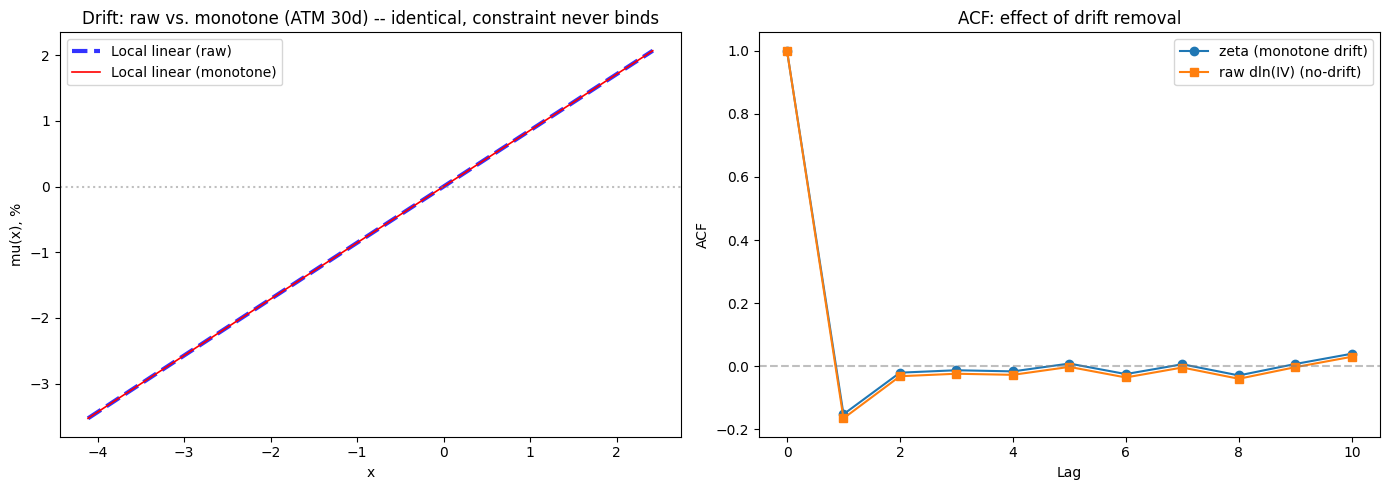

ACF(1): zeta (monotone drift) = -0.1518  | raw dln(IV) (no-drift) = -0.1647
std zeta (monotone)           = 0.08019
std raw local-linear residual = 0.08019

Monotonicity constraint: max|mu_raw - mu_mono| = 0.000000, binding at 0/101 points
-> At bandwidth=7 the raw local-linear fit is ALREADY monotone everywhere: the
   constraint never binds and is not distorting the estimate (for THIS bandwidth).
   At smaller bandwidths (see the grid above) the raw fit is noisier and might
   not be monotone: there the constraint would become relevant.


In [18]:
# --- Robustness: monotonicity constraint vs. alternative specifications ---
from statsmodels.tsa.ar_model import AutoReg

# 1. Raw drift (local linear, no monotonicity) vs. monotone: already available (mu_raw, mu_mono)
# 2. AR(1) benchmark on ln(IV) ATM 30d
ar1 = AutoReg(df['ln_IV'].dropna(), lags=1, old_names=False).fit()
print('--- AR(1) benchmark on ln(IV_ATM_30d) ---')
print(ar1.summary().tables[1])

# 3. No-drift benchmark (zeta_nodrift = raw dln_IV, drift = 0 everywhere)
zeta_nodrift = df_iv['dln_IV']
mu_raw_interp_vals = np.interp(df_iv['x'].shift(1), x_grid, mu_raw)
zeta_raw_local_linear = df_iv['dln_IV'] - mu_raw_interp_vals

max_diff_raw_mono = np.max(np.abs(mu_raw - mu_mono))
n_binding = np.sum(np.abs(mu_raw - mu_mono) > 1e-10)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(x_grid, mu_raw * 100, 'b--', linewidth=3, alpha=0.8, label='Local linear (raw)')
axes[0].plot(x_grid, mu_mono * 100, 'r-', linewidth=1.2, label='Local linear (monotone)')
axes[0].axhline(0, color='gray', linestyle=':', alpha=0.5)
axes[0].set_xlabel('x'); axes[0].set_ylabel('mu(x), %')
if n_binding == 0:
    axes[0].set_title('Drift: raw vs. monotone (ATM 30d) -- identical, constraint never binds')
else:
    axes[0].set_title('Drift: raw vs. monotone (ATM 30d)')
axes[0].legend()

acf_mono = acf(df_iv['zeta'].dropna(), nlags=10)
acf_nodrift = acf(zeta_nodrift.dropna(), nlags=10)
axes[1].plot(range(11), acf_mono, marker='o', label='zeta (monotone drift)')
axes[1].plot(range(11), acf_nodrift, marker='s', label='raw dln(IV) (no-drift)')
axes[1].axhline(0, color='gray', linestyle='--', alpha=0.5)
axes[1].set_xlabel('Lag'); axes[1].set_ylabel('ACF')
axes[1].set_title("ACF: effect of drift removal")
axes[1].legend()
plt.tight_layout()
plt.show()

print('ACF(1): zeta (monotone drift) =', round(acf_mono[1], 4),
      ' | raw dln(IV) (no-drift) =', round(acf_nodrift[1], 4))
print('std zeta (monotone)           =', round(df_iv['zeta'].std(), 5))
print('std raw local-linear residual =', round(zeta_raw_local_linear.std(), 5))
print(f'\nMonotonicity constraint: max|mu_raw - mu_mono| = {max_diff_raw_mono:.6f}, '
      f'binding at {n_binding}/{len(x_grid)} points')
if n_binding == 0:
    print('-> At bandwidth=7 the raw local-linear fit is ALREADY monotone everywhere: the')
    print('   constraint never binds and is not distorting the estimate (for THIS bandwidth).')
    print('   At smaller bandwidths (see the grid above) the raw fit is noisier and might')
    print('   not be monotone: there the constraint would become relevant.')


**Descriptive statistics**

In [19]:
print('=' * 80)
print('DESCRIPTIVE STATISTICS')
print('=' * 80)

# --- Table 1: Summary statistics ---
from statsmodels.stats.diagnostic import acorr_ljungbox

def lb_q20_sq(s):
    """Ljung-Box Q(20) and p-value on the squared series -- a volatility-
    clustering / residual-ARCH diagnostic (relevant for log-return and
    epsilon; for the IV level it is reported for formatting consistency but
    is not the diagnostic of interest)."""
    row = acorr_ljungbox(s.dropna() ** 2, lags=[20], return_df=True).iloc[0]
    return row['lb_stat'], row['lb_pvalue']

def ac1_sq(s):
    """AC(1) of the squared series (complementary to the level's AC(1))."""
    return (s.dropna() ** 2).autocorr(1)

stats_vars = {
    'S&P 500 Log Return (daily)': df['log_return'],
    'IV ATM 30d (level)':         df['IV_ATM_30d'],
    'Return Innovation epsilon':  df['epsilon'],
}
stats_rows = {}
for name, s in stats_vars.items():
    lb_stat, lb_pvalue = lb_q20_sq(s)
    stats_rows[name] = {
        'N obs':      int(s.notna().sum()),
        'Mean':       s.mean(),
        'Median':     s.median(),
        'Std':        s.std(),
        'Min':        s.min(),
        'Max':        s.max(),
        'Skewness':   s.skew(),
        'Kurtosis':   s.kurtosis(),
        'AC(1)':      s.autocorr(1),
        'AC(5)':      s.autocorr(5),
        'AC1_sq':     ac1_sq(s),
        'LB_Q20_sq':  lb_stat,
        'LB_Q20_sq_pvalue': lb_pvalue,
    }
stats_table = pd.DataFrame(stats_rows).T
print('\n--- Table 1: Summary Statistics ---')
print(stats_table.round(4).to_string())

# --- Table 2: Mean IV by Wu delta x maturity ---
print('\n--- Table 2: Mean IV (%) by Wu Delta x Maturity ---')
pivot_data = [{'wu_delta': row['wu_delta'], 'days': row['days'],
               'v': iv_panel[row['series_id']].dropna().mean() * 100}
              for _, row in grid_df.iterrows()]
iv_mean_tbl = pd.DataFrame(pivot_data).pivot(index='wu_delta', columns='days', values='v')
iv_mean_tbl.index.name = 'Put Delta'; iv_mean_tbl.columns.name = 'Maturity (days)'
print(iv_mean_tbl.round(2).to_string())

# --- Table 3: IV Std ---
print('\n--- Table 3: IV Std (%) by Wu Delta x Maturity ---')
pivot_std = [{'wu_delta': row['wu_delta'], 'days': row['days'],
              'v': iv_panel[row['series_id']].dropna().std() * 100}
             for _, row in grid_df.iterrows()]
iv_std_tbl = pd.DataFrame(pivot_std).pivot(index='wu_delta', columns='days', values='v')
iv_std_tbl.index.name = 'Put Delta'; iv_std_tbl.columns.name = 'Maturity (days)'
print(iv_std_tbl.round(2).to_string())

# --- Table 4: AC(1) of IV ---
print('\n--- Table 4: Autocorrelation(1) of IV by Wu Delta x Maturity ---')
pivot_ac = [{'wu_delta': row['wu_delta'], 'days': row['days'],
             'v': iv_panel[row['series_id']].dropna().autocorr(1)}
            for _, row in grid_df.iterrows()]
iv_ac1_tbl = pd.DataFrame(pivot_ac).pivot(index='wu_delta', columns='days', values='v')
iv_ac1_tbl.index.name = 'Put Delta'; iv_ac1_tbl.columns.name = 'Maturity (days)'
print(iv_ac1_tbl.round(4).to_string())

# --- Table 5: innovation statistics ---
print('\n--- Table 5: Return Innovation and IV Innovations ---')
eps = innovations_clean['epsilon']
print(f'Return innovation epsilon:')
print(f'  Mean={eps.mean():.4f}  Std={eps.std():.4f}  Var={eps.var():.4f}  '
      f'Skew={eps.skew():.4f}  Kurt={eps.kurtosis():.4f}')
zeta_cols  = [c for c in innovations_clean.columns if c != 'epsilon']
zeta_means = innovations_clean[zeta_cols].mean()
zeta_stds  = innovations_clean[zeta_cols].std()
print(f'\nIV innovations (25 series):')
print(f'  Mean of means: {zeta_means.mean():.6f}')
print(f'  Mean of stds:  {zeta_stds.mean():.6f}')
print(f'  Min std: {zeta_stds.min():.6f} ({zeta_stds.idxmin()})')
print(f'  Max std: {zeta_stds.max():.6f} ({zeta_stds.idxmax()})')


DESCRIPTIVE STATISTICS

--- Table 1: Summary Statistics ---
                             N obs    Mean  Median     Std     Min     Max  Skewness  Kurtosis   AC(1)   AC(5)  AC1_sq   LB_Q20_sq  LB_Q20_sq_pvalue
S&P 500 Log Return (daily)  7462.0  0.0003  0.0007  0.0121 -0.1277  0.1096   -0.3616   10.0872 -0.0889 -0.0185  0.3086   8959.3828               0.0
IV ATM 30d (level)          7462.0  0.1733  0.1580  0.0744  0.0642  0.7632    2.0038    7.3494  0.9732  0.9180  0.9556  97963.4461               0.0
Return Innovation epsilon   7462.0  0.0243  0.0718  0.9333 -5.9363  3.5311   -0.5338    1.3873 -0.0244 -0.0218  0.0343    242.2164               0.0

--- Table 2: Mean IV (%) by Wu Delta x Maturity ---
Maturity (days)    30     91     182    273    365
Put Delta                                         
10               25.86  26.92  27.37  27.48  27.40
25               21.01  22.19  22.82  23.08  23.16
50               17.33  18.16  18.67  18.94  19.10
75               15.31  15.68  15.97

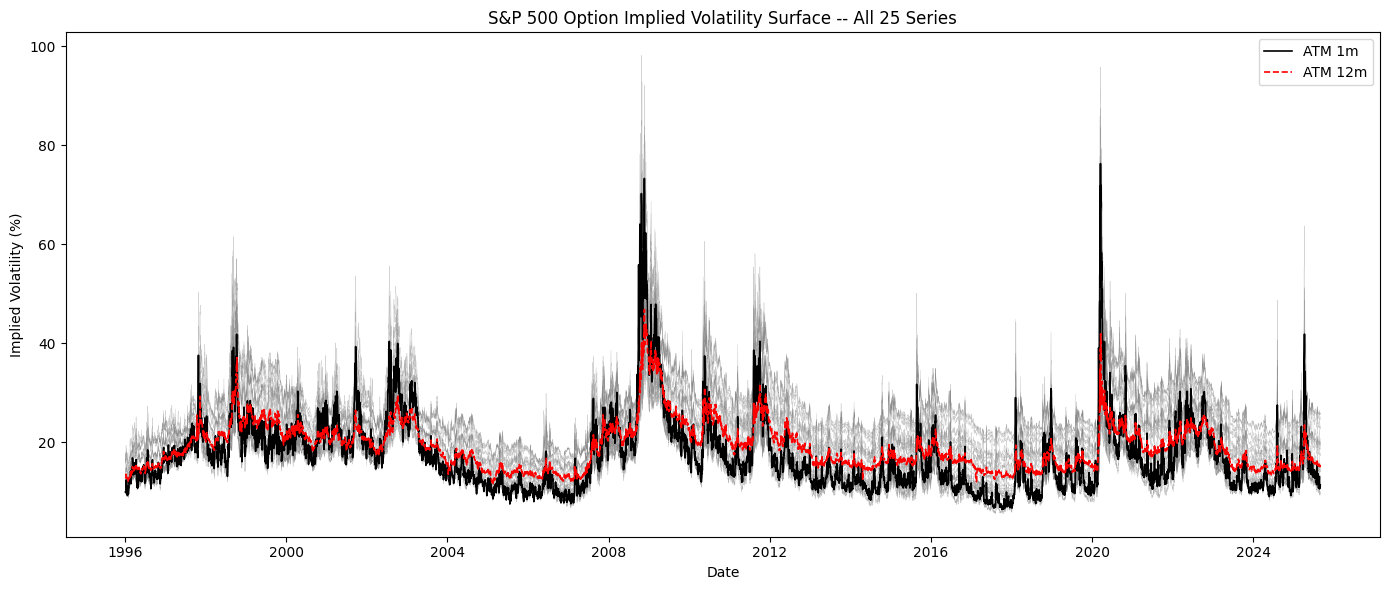

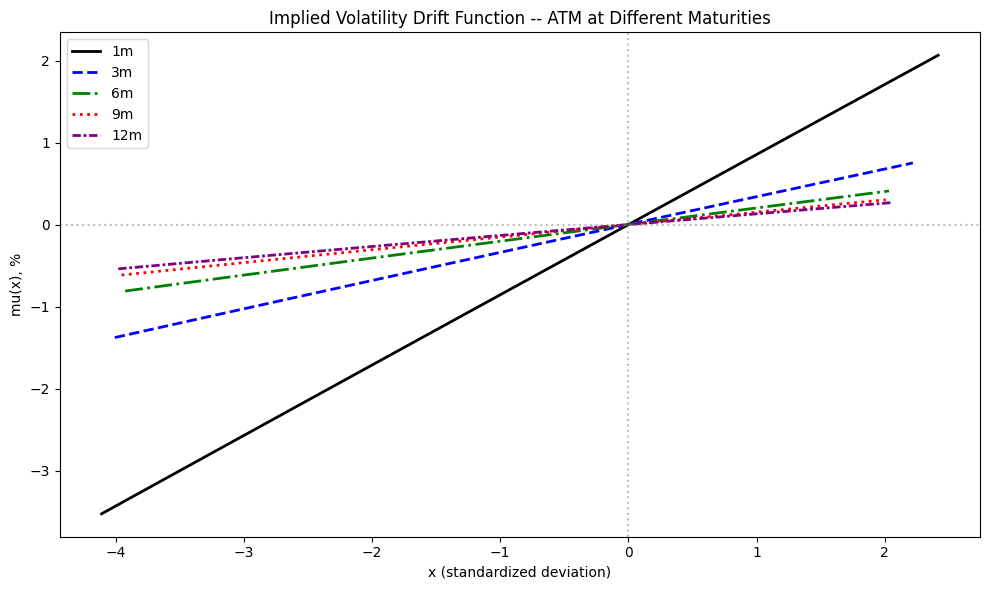

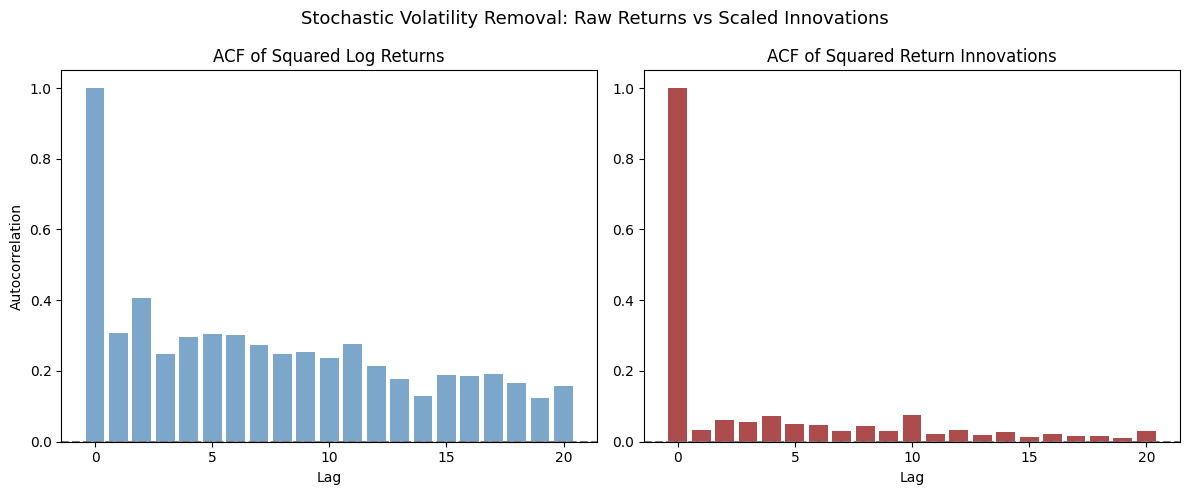

AC(1) return2=0.3086  epsilon2=0.0343  reduction 88.9%


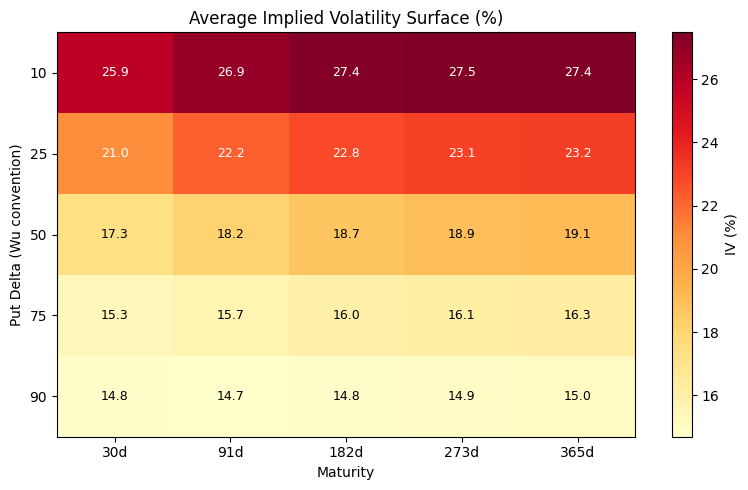

In [20]:
# --- Figure 1: IV time series, all 25 series ---
fig, ax = plt.subplots(figsize=(14, 6))
for sid in grid_df['series_id']:
    ax.plot(iv_panel.index, iv_panel[sid] * 100, linewidth=0.3, alpha=0.4, color='gray')
ax.plot(iv_panel.index, iv_panel['d50_30d']  * 100, linewidth=1.2, color='black',  label='ATM 1m')
ax.plot(iv_panel.index, iv_panel['d50_365d'] * 100, linewidth=1.2, color='red', linestyle='--', label='ATM 12m')
ax.set_ylabel('Implied Volatility (%)')
ax.set_xlabel('Date')
ax.set_title('S&P 500 Option Implied Volatility Surface -- All 25 Series')
ax.legend()
plt.tight_layout()
plt.show()

# --- Figure 2: ATM drift function at different maturities ---
fig, ax = plt.subplots(figsize=(10, 6))
colors_ = ['black', 'blue', 'green', 'red', 'purple']
styles_ = ['-', '--', '-.', ':', (0, (3,1,1,1))]
for i, (days, label) in enumerate(zip(SELECTED_MATURITIES, ['1m','3m','6m','9m','12m'])):
    sid = make_series_id(50, days)
    if sid in drift_functions:
        x_g, mu_m = drift_functions[sid]
        ax.plot(x_g, mu_m * 100, color=colors_[i], linestyle=styles_[i], linewidth=2, label=label)
ax.axhline(0, color='gray', linestyle=':', alpha=0.5)
ax.axvline(0, color='gray', linestyle=':', alpha=0.5)
ax.set_xlabel('x (standardized deviation)')
ax.set_ylabel('mu(x), %')
ax.set_title('Implied Volatility Drift Function -- ATM at Different Maturities')
ax.legend()
plt.tight_layout()
plt.show()

# --- Figure 3: ACF of return^2 vs. epsilon^2 ---
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
acf_ret2 = acf(df['log_return'].dropna()**2, nlags=20)
acf_eps2 = acf(innovations_clean['epsilon']**2, nlags=20)
axes[0].bar(range(21), acf_ret2, color='steelblue', alpha=0.7)
axes[0].set_title('ACF of Squared Log Returns')
axes[0].set_xlabel('Lag'); axes[0].set_ylabel('Autocorrelation')
axes[0].axhline(0, color='gray', linestyle='--')
axes[1].bar(range(21), acf_eps2, color='darkred', alpha=0.7)
axes[1].set_title('ACF of Squared Return Innovations')
axes[1].set_xlabel('Lag')
axes[1].axhline(0, color='gray', linestyle='--')
plt.suptitle('Stochastic Volatility Removal: Raw Returns vs Scaled Innovations', fontsize=13)
plt.tight_layout()
plt.show()
print(f'AC(1) return2={acf_ret2[1]:.4f}  epsilon2={acf_eps2[1]:.4f}  '
      f'reduction {(1-acf_eps2[1]/acf_ret2[1])*100:.1f}%')

# --- Figure 4: Mean IV heatmap ---
import matplotlib.colors as mcolors
fig, ax = plt.subplots(figsize=(8, 5))
heatmap_data = iv_mean_tbl.values
im = ax.imshow(heatmap_data, cmap='YlOrRd', aspect='auto')
ax.set_xticks(range(len(SELECTED_MATURITIES)))
ax.set_xticklabels([f'{d}d' for d in SELECTED_MATURITIES])
ax.set_yticks(range(5)); ax.set_yticklabels([10, 25, 50, 75, 90])
ax.set_xlabel('Maturity'); ax.set_ylabel('Put Delta (Wu convention)')
ax.set_title('Average Implied Volatility Surface (%)')
for i in range(5):
    for j in range(len(SELECTED_MATURITIES)):
        v = heatmap_data[i, j]
        ax.text(j, i, f'{v:.1f}', ha='center', va='center', fontsize=9,
                color='white' if v > heatmap_data.mean() else 'black')
plt.colorbar(im, ax=ax, label='IV (%)')
plt.tight_layout()
plt.show()


## **3.5 VIX, Realized Variance, and the Conventional VRP**

Reference benchmark: the conventional Variance Risk Premium (BTZ 2009) is defined as $VRP = IV^2 - RV$, where $IV$ is the VIX and $RV$ is the realized variance.
It serves as a baseline against which to compare the bootstrapped conditional risk premia (Sections 6-8).

In [21]:
# ── RV: Realized Variance (rolling 22-day) ─────────────────────────────
spx_rv = df[['log_return']].copy()
spx_rv['rv_sq'] = spx_rv['log_return'] ** 2
spx_rv['RV_22d'] = spx_rv['rv_sq'].rolling(window=22, min_periods=18).sum()
spx_rv['RV_annual'] = spx_rv['RV_22d'] * (252 / 22)
df['RV_annual'] = spx_rv['RV_annual']

# ── VIX (CBOE, from cboe_VIX.csv) ───────────────────────────────────────
# cboe_VIX.csv has 2 duplicate dates; without deduplicating, the left-join below
# would silently propagate those 2 rows into df (every later section inherits them),
# inflating every downstream N-count by up to 2 observations. Deduplicating here
# keeps the row count consistent throughout the notebook.
vix_raw = pd.read_csv(
    os.path.join(DATA_DIR, 'cboe_VIX.csv'),
    parse_dates=['Date']
).rename(columns={'Date': 'date', 'vix': 'VIX'}).sort_values('date').drop_duplicates('date').set_index('date').sort_index()
df = df.join(vix_raw[['VIX']], how='left')
df['VIX2'] = (df['VIX'] / 100) ** 2   # varianza annualizzata

print(f'RV_annual - valid obs: {df["RV_annual"].notna().sum()}')
print(f'VIX       - valid obs: {df["VIX"].notna().sum()}')
print(f'\n--- Summary statistics ---')
print(df[['IV_ATM_30d','VIX','RV_annual']].dropna().describe().round(4).to_string())


RV_annual - valid obs: 7445
VIX       - valid obs: 7460

--- Summary statistics ---
       IV_ATM_30d        VIX  RV_annual
count   7443.0000  7443.0000  7443.0000
mean       0.1734    20.2023     0.0370
std        0.0744     8.1314     0.0700
min        0.0642     9.1400     0.0014
25%        0.1203    14.4750     0.0104
50%        0.1582    18.6000     0.0196
75%        0.2072    23.6450     0.0384
max        0.7632    82.6900     0.8751


**Conventional VRP**
The conventional VRP ($VIX^2 - RV$) is **positive** on average in our sample (~105 bps of variance, negative on only ~14% of days). A positive VRP means implied variance ($VIX^2$) systematically exceeds realized variance: option/variance sellers earn a positive premium on average, i.e. buyers of volatility protection pay, on average, more than what is later realized. To avoid ambiguity, both sign conventions are defined explicitly below ($VRP_{\text{seller}}$, $VRP_{\text{buyer}}$), and $VRP_{\text{seller}} = VIX^2 - RV$ is used as the reference convention throughout the rest of the notebook (consistent with BTZ 2009).

=== CONVENTIONAL VARIANCE RISK PREMIUM (benchmark, VRP_seller convention = VIX2 - RV) ===
Obs: 7443
Mean:      0.010471  (104.7 bps of variance)
Std:       0.039190
% negative: 13.6%
Min: -0.670464  Max: 0.217934

A positive mean means the seller of variance/protection earns a positive
premium on average (BTZ 2009); VRP_buyer (= -VRP_seller) is therefore negative on average.


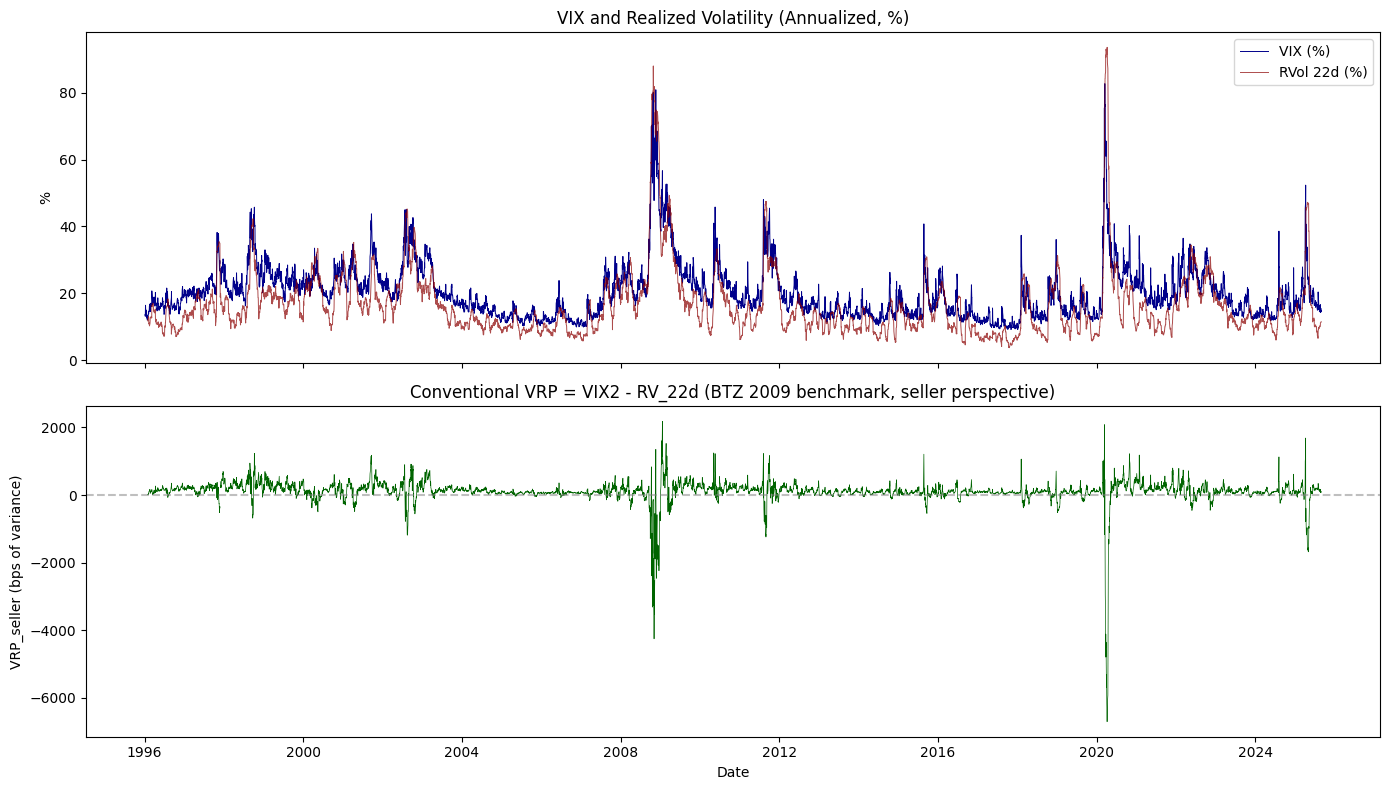

In [22]:
# Both sign conventions are made explicit here.
# Reference convention used throughout the rest of the notebook: VRP_seller (= VRP_conventional).
df['VRP_seller'] = df['VIX2'] - df['RV_annual']   # seller-of-protection perspective
df['VRP_buyer'] = df['RV_annual'] - df['VIX2']    # buyer-of-protection perspective
df['VRP_conventional'] = df['VRP_seller']         # reference convention

vrp_clean = df['VRP_conventional'].dropna()
print(f'=== CONVENTIONAL VARIANCE RISK PREMIUM (benchmark, VRP_seller convention = VIX2 - RV) ===')
print(f'Obs: {len(vrp_clean)}')
print(f'Mean:      {vrp_clean.mean():.6f}  ({vrp_clean.mean()*10000:.1f} bps of variance)')
print(f'Std:       {vrp_clean.std():.6f}')
print(f'% negative: {(vrp_clean < 0).mean()*100:.1f}%')
print(f'Min: {vrp_clean.min():.6f}  Max: {vrp_clean.max():.6f}')
print(f"\nA positive mean means the seller of variance/protection earns a positive")
print(f"premium on average (BTZ 2009); VRP_buyer (= -VRP_seller) is therefore negative on average.")

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
axes[0].plot(df.index, df['VIX'],                linewidth=0.7, color='darkblue', label='VIX (%)')
axes[0].plot(df.index, np.sqrt(df['RV_annual'])*100, linewidth=0.7, color='darkred', alpha=0.7, label='RVol 22d (%)')
axes[0].set_ylabel('%'); axes[0].legend()
axes[0].set_title('VIX and Realized Volatility (Annualized, %)')
axes[1].plot(df.index, df['VRP_conventional']*10000, linewidth=0.5, color='darkgreen')
axes[1].axhline(0, color='gray', linestyle='--', alpha=0.5)
axes[1].set_ylabel('VRP_seller (bps of variance)'); axes[1].set_xlabel('Date')
axes[1].set_title('Conventional VRP = VIX2 - RV_22d (BTZ 2009 benchmark, seller perspective)')
plt.tight_layout()
plt.show()


## **3.6 Risk-Free Rate and Dividend Yield (OptionMetrics)**

Section 5 (delta-hedged returns) implicitly used $r=0$ (no discounting) in the Black-76 formula. Here we load OptionMetrics' actual yield curve to interpolate $r(\tau)$ at the test date, used as the discount rate in pricing. The dividend yield is loaded and reported for completeness, but does NOT enter the pricing formula: since the whole notebook works in forward units ($F_0=100$ normalized, consistent with Wu 2025), the dividend is already implicitly absorbed into the forward's definition — this is the standard Black-76 result, which only needs the rate $r$ to discount the expected value to present value.

In [23]:
yield_curve = pd.read_csv(
    os.path.join(DATA_DIR, 'optionmetrics_yieldcurve.csv'),
    parse_dates=['date']
)
idxdvd = pd.read_csv(
    os.path.join(DATA_DIR, 'optionmetrics_idxdvd.csv'),
    parse_dates=['date', 'expiration']
)

def get_risk_free_rate(date, tau_years, yield_curve):
    """
    Interpolate r(tau) (decimal, not %) from the OptionMetrics yield curve at the
    closest available date (<= date). tau_years is converted to calendar days for
    the interpolation (consistent with the OM yield curve's 'days' column).
    """
    days_target = tau_years * 365.0
    avail_dates = yield_curve.loc[yield_curve['date'] <= date, 'date']
    use_date = avail_dates.max() if not avail_dates.empty else yield_curve['date'].min()
    curve = yield_curve[yield_curve['date'] == use_date].sort_values('days')
    r_pct = np.interp(days_target, curve['days'].values, curve['rate'].values)
    return r_pct / 100.0

print('=== YIELD CURVE (OptionMetrics) ===')
print(yield_curve.groupby('days')['rate'].mean().describe().round(4))
_sample_date = df.index[len(df) // 2]
print(f"\nExample: r at {_sample_date.strftime('%Y-%m-%d')} for tau=0.25y: "
      f"{get_risk_free_rate(_sample_date, 0.25, yield_curve) * 100:.3f}%")

print('\n=== DIVIDEND YIELD (OptionMetrics idxdvd, for reference only) ===')
print(f"Mean dividend yield: {idxdvd['rate'].mean():.3f}% (annualized)")
print(f"Range: [{idxdvd['rate'].min():.3f}%, {idxdvd['rate'].max():.3f}%]")


=== YIELD CURVE (OptionMetrics) ===
count    3666.0000
mean        2.6759
std         1.3451
min         0.1127
25%         1.1377
50%         3.1410
75%         3.7988
max         4.4703
Name: rate, dtype: float64

Example: r at 2010-10-29 for tau=0.25y: 0.305%

=== DIVIDEND YIELD (OptionMetrics idxdvd, for reference only) ===
Mean dividend yield: 1.448% (annualized)
Range: [0.000%, 29.681%]


## **4. Bootstrap paths**

**What does the joint bootstrapping do?**

The bootstrap is run at a **specific date** $t$ (Wu does this every Wednesday). At that date, we know the current S&P 500 price, the entire current IV surface, and the full history of innovations ($\varepsilon$, $\zeta$) up to $t$. The bootstrap generates $N$ simulated paths (e.g. 10,000) of the price and the IV surface over a horizon of $d_H$ trading days (e.g. 5 for one week). On each path, we compute the delta-hedged option excess return for every contract in the grid. The cross-path mean is the conditional risk premium for that contract at that date.

Concretely, for each path $i$ and each day $d$ of the path:
- **For the price** (Wu's equations 4-5): take the previous day's price, multiply it by $\exp(IV_{\text{ATM}} \times \sqrt{\Delta t} \times \varepsilon)$, where $\varepsilon$ is the sampled innovation and $IV_{\text{ATM}}$ is the bootstrapped ATM IV at that step. Then renormalize the cross-path mean price to \$100 (equation 5). The renormalization removes the price drift, isolating the volatility risk.
- **For each IV series** (Wu's equations 6-7): compute the standardized deviation $x$ from the current level, interpolate the drift $\mu(x)$, and update IV as $V \times \exp(\mu(x) + \zeta)$, where $\zeta$ is the sampled innovation. This makes IV mean-revert toward its long-run mean while receiving a random shock.
- **The joint sampling** is the key mechanism: at every step $d$ of every path $i$, a single random historical time index is drawn, and the $\varepsilon$ and all 25 $\zeta$ values from that same historical date are used together. This preserves the cross-sectional correlations.

Because this code is long, it is split into two blocks. The first implements the path bootstrap for a single test date — so the mechanism can be verified and the paths inspected. The second block computes the delta-hedged excess returns and risk premia, and later wraps everything in the rolling loop over all test dates.

In [24]:
# =============================================================================
# STEP 4: JOINT BOOTSTRAPPING -- PRICE PATHS AND IV SURFACE
# =============================================================================
# Here we implement the bootstrap for A SINGLE test date. Section 6 wraps the
# same logic in a loop over all test dates.
#
# References: Wu (2025), equations (4)-(7), section 2.3

# ─── PARAMETERS ───
N_PATHS = 10000       # Number of bootstrapped paths (Wu 2025)
HORIZON_DAYS = 5      # Horizon in trading days (1 week)
F0 = 100.0            # Initial normalized forward price
dt = 1 / 252          # Daily interval in years

# ─── CHOOSING THE TEST DATE ───
# Wu (2025) starts from the midpoint of the sample. With data from ~1996, the
# midpoint is ~2010. We pick a Wednesday well inside the sample for this test.

# Find every Wednesday in the dataset
all_dates = innovations_clean.index
wednesdays = all_dates[all_dates.weekday == 2]  # 2 = Wednesday

# Take the sample midpoint as the first eligible Wednesday
midpoint = all_dates[len(all_dates) // 2]
valid_wednesdays = wednesdays[wednesdays >= midpoint]
test_date = valid_wednesdays[0]

print(f"=== TEST DATE: {test_date.strftime('%Y-%m-%d')} ===")
print(f"Sample midpoint: {midpoint.strftime('%Y-%m-%d')}")
print(f"Innovations available up to this date: {(all_dates < test_date).sum()}")

=== TEST DATE: 2010-11-03 ===
Sample midpoint: 2010-10-29
Innovations available up to this date: 3734


**4a. Preparation**

Selects the innovation history only up to the test date (no look-ahead). Retrieves the SPX price and the entire IV surface at that date. Re-estimates $\theta$, $\sigma$, and the drift function for each series using only data up to that point.

In [25]:
# ─── 4a. PREPARATION: innovation history up to the test date ───
#
# The zeta panel is rebuilt from scratch using compute_zeta_panel(up_to_date=
# test_date), so that both the drift function and the zeta residuals use only
# information available up to and including test_date -- exactly as specified
# by Wu (2025), sec. 3.2: "At each bootstrapping date, the drift function mu(x)
# for each implied volatility series is re-estimated with the historical data
# up to that date" (verified against the original PDF). This avoids the
# look-ahead bias that would result from resampling zeta values computed
# against a drift function fit to the full 1996-2025 sample.

zeta_panel_test, drift_functions_test, iv_stats_test = compute_zeta_panel(
    iv_panel, grid_df, estimate_drift_function, up_to_date=test_date,
    bandwidth=7, n_grid=101, verbose=False
)

eps_hist_test = df['epsilon'].loc[:test_date]
_common_idx = eps_hist_test.index.intersection(zeta_panel_test.dropna().index)
_common_idx = _common_idx[_common_idx < test_date]  # excludes the test_date row itself

hist_innovations = pd.DataFrame({'epsilon': eps_hist_test.loc[_common_idx]})
for series_id in grid_df['series_id']:
    hist_innovations[series_id] = zeta_panel_test.loc[_common_idx, series_id]
hist_innovations = hist_innovations.dropna()
n_hist = len(hist_innovations)
print(f"Historical observations for bootstrapping (drift re-estimated up to test_date): {n_hist}")

# Initial values at the test date
spx_at_test = df.loc[test_date, 'close'] if test_date in df.index else df.loc[:test_date].iloc[-1]['close']

iv_at_test = {}
for series_id in grid_df['series_id']:
    if test_date in iv_panel.index and pd.notna(iv_panel.loc[test_date, series_id]):
        iv_at_test[series_id] = iv_panel.loc[test_date, series_id]
    else:
        temp = iv_panel[series_id].loc[:test_date].dropna()
        iv_at_test[series_id] = temp.iloc[-1]

print(f"SPX at the test date: {spx_at_test:.2f}")
print(f"IV ATM 30d at the test date: {iv_at_test['d50_30d']:.4f} ({iv_at_test['d50_30d']*100:.1f}%)")


Historical observations for bootstrapping (drift re-estimated up to test_date): 3734
SPX at the test date: 1197.96
IV ATM 30d at the test date: 0.1783 (17.8%)


**4b. Joint sampling**

Generates a matrix of random indices ($N_{\text{PATHS}} \times \text{HORIZON\_DAYS}$). Each index points to a row of the historical innovations DataFrame. The same index is used for $\varepsilon$ and for all 25 $\zeta$ series. This is the mechanism that preserves the co-movements: if the historically sampled day had a crash ($\varepsilon$ very negative) with IV rising (positive $\zeta$ for puts), the bootstrapped path will carry the same pairing.

In [26]:
# ─── 4b. JOINT SAMPLING OF INDICES ───
# For each path i and each day d, we draw a random index from the history.
# The SAME index is used for epsilon and all 25 zeta -> preserves correlations.

np.random.seed(42)  # Reproducibility

# Index matrix: (N_PATHS, HORIZON_DAYS)
# Each entry is a row index into the hist_innovations DataFrame
sampled_indices = np.random.randint(0, n_hist, size=(N_PATHS, HORIZON_DAYS))

# Extract the sampled innovations
# epsilon: (N_PATHS, HORIZON_DAYS)
eps_sampled = hist_innovations['epsilon'].values[sampled_indices]

# zeta for each series: dict {series_id: array (N_PATHS, HORIZON_DAYS)}
zeta_sampled = {}
for series_id in grid_df['series_id']:
    zeta_sampled[series_id] = hist_innovations[series_id].values[sampled_indices]

print(f"\nSampled innovations:")
print(f"  epsilon shape: {eps_sampled.shape}")
print(f"  zeta shape per series: {zeta_sampled[grid_df['series_id'].iloc[0]].shape}")


Sampled innovations:
  epsilon shape: (10000, 5)
  zeta shape per series: (10000, 5)


**4c. Propagation**

The day-by-day loop implements Wu's equations 4-7. For the price: $\exp(IV \times \sqrt{\Delta t} \times \varepsilon)$ followed by renormalizing the mean to \$100. For each IV series: computing $x$, interpolating the drift, and updating $V \times \exp(\mu + \zeta)$. The price renormalization is crucial: without it, the paths would have a mean drift that would contaminate the excess returns with the market risk premium. With renormalization, the mean price stays at \$100 and the delta-hedged options' excess returns reflect only volatility risk.

In [27]:
# ─── 4c. PATH PROPAGATION ───
# For each path i, the price and the IV surface are propagated day by day.
#
# Equation (4): F_{d+1,i} = F_{d,i} * exp(I_{d,i} * sqrt(dt) * eps_{d+1,i})
# Equation (5): F_{d+1,i} = (F0 / mean(F_{d+1})) * F_{d+1,i}  [renormalization]
# Equation (6): x_{d,i} = (theta - ln(V_{d,i})) / sigma
# Equation (7): V_{d+1,i} = V_{d,i} * exp(mu(x_{d,i}) + zeta_{d+1,i})
#
# iv_stats_local / drift_functions_local are simply an alias for iv_stats_test /
# drift_functions_test, already computed in Section 4a under the same
# up_to_date=test_date restriction -- reused here rather than re-estimated a
# second time, so the propagation step uses exactly the same drift estimate as
# the resampling step.
iv_stats_local = iv_stats_test
drift_functions_local = drift_functions_test
print("Drift functions (Section 4a) reused for propagation -- no duplicate re-estimation.")

# --- Propagation ---

price_paths = np.zeros((N_PATHS, HORIZON_DAYS + 1))
price_paths[:, 0] = F0

iv_paths = {}
for series_id in grid_df['series_id']:
    iv_paths[series_id] = np.zeros((N_PATHS, HORIZON_DAYS + 1))
    iv_paths[series_id][:, 0] = iv_at_test[series_id]

atm_series_id = 'd50_30d'

for d in range(HORIZON_DAYS):
    I_d = iv_paths[atm_series_id][:, d]
    price_paths[:, d + 1] = price_paths[:, d] * np.exp(I_d * np.sqrt(dt) * eps_sampled[:, d])

    mean_price = price_paths[:, d + 1].mean()
    price_paths[:, d + 1] = (F0 / mean_price) * price_paths[:, d + 1]

    for series_id in grid_df['series_id']:
        theta_s, sigma_s = iv_stats_local[series_id]
        x_grid_s, mu_mono_s = drift_functions_local[series_id]
        mu_interp_s = interp1d(x_grid_s, mu_mono_s, kind='linear', fill_value='extrapolate')

        V_d = iv_paths[series_id][:, d]
        x_d = (theta_s - np.log(V_d)) / sigma_s
        mu_d = mu_interp_s(x_d)

        iv_paths[series_id][:, d + 1] = V_d * np.exp(mu_d + zeta_sampled[series_id][:, d])

print("Propagation complete!")
print(f"Price paths shape: {price_paths.shape}")


Drift functions (Section 4a) reused for propagation -- no duplicate re-estimation.
Propagation complete!
Price paths shape: (10000, 6)


**4d. Visual diagnostics**

The four plots let us check that the paths make sense. The price paths plot should show a fan centered on \$100 with negative skewness (a longer left tail). The ATM IV paths should show mean reversion toward the mean. The final-price distribution should be approximately lognormal with mean ~\$100.

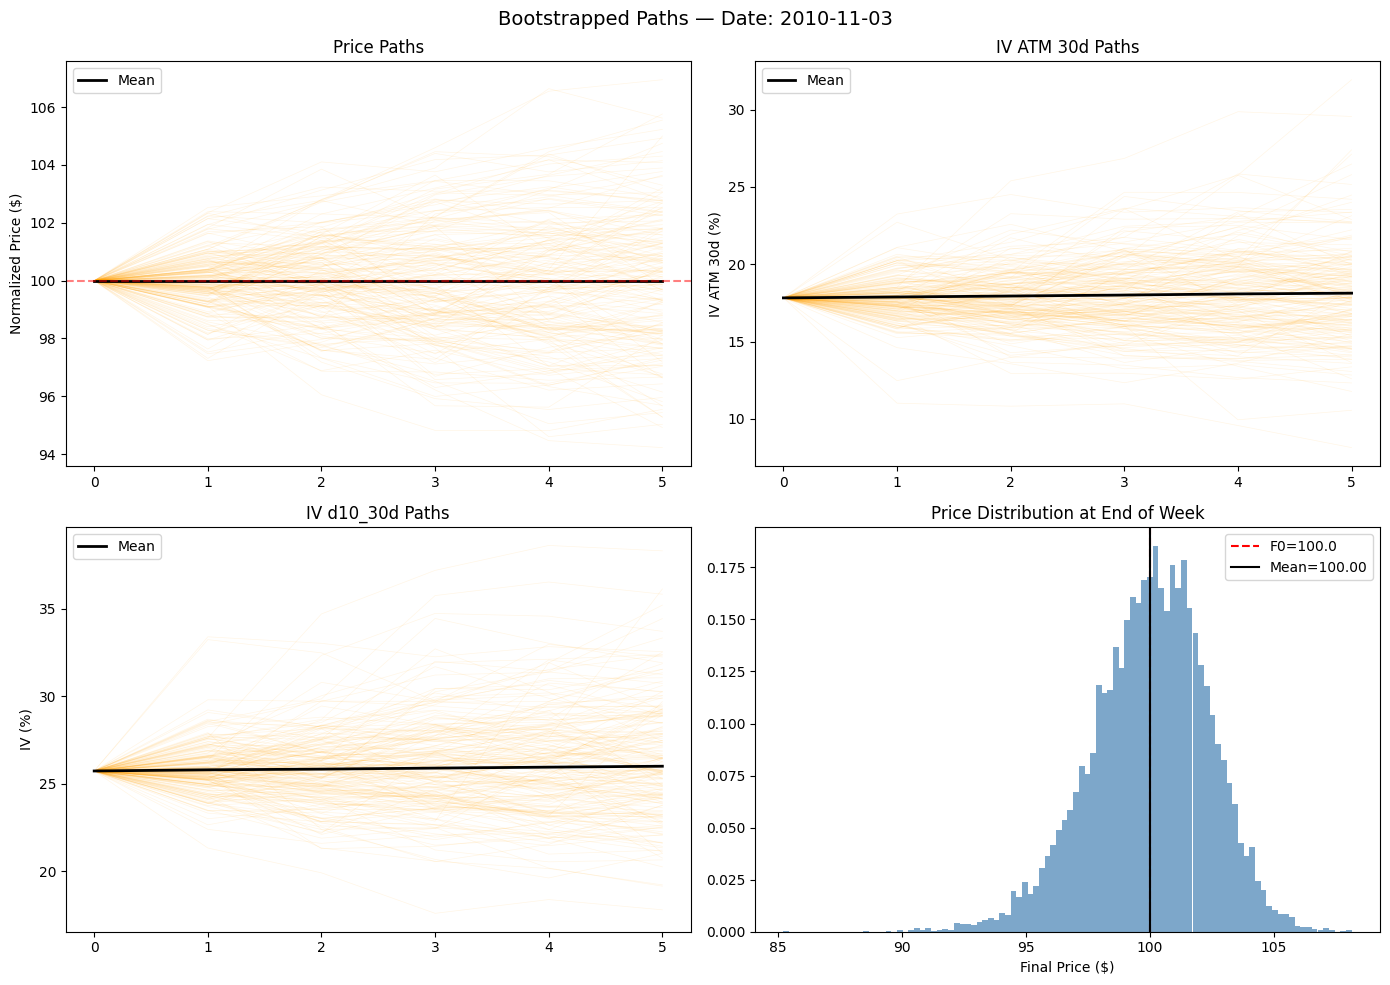

In [28]:
# ─── 4d. BOOTSTRAPPED-PATH DIAGNOSTICS ───
# Compare with Figure 3 of Wu (2025)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle(f'Bootstrapped Paths — Date: {test_date.strftime("%Y-%m-%d")}', fontsize=14)

# 1. Price paths (a subsample of 200 for readability)
n_show = 200
for i in range(n_show):
    axes[0, 0].plot(range(HORIZON_DAYS + 1), price_paths[i, :],
                     alpha=0.1, linewidth=0.5, color='orange')
axes[0, 0].plot(range(HORIZON_DAYS + 1), price_paths.mean(axis=0),
                 linewidth=2, color='black', label='Mean')
axes[0, 0].axhline(F0, color='red', linestyle='--', alpha=0.5)
axes[0, 0].set_ylabel('Normalized Price ($)')
axes[0, 0].set_title('Price Paths')
axes[0, 0].legend()

# 2. IV ATM 30d paths
atm_iv_paths = iv_paths[atm_series_id]
for i in range(n_show):
    axes[0, 1].plot(range(HORIZON_DAYS + 1), atm_iv_paths[i, :] * 100,
                     alpha=0.1, linewidth=0.5, color='orange')
axes[0, 1].plot(range(HORIZON_DAYS + 1), atm_iv_paths.mean(axis=0) * 100,
                 linewidth=2, color='black', label='Mean')
axes[0, 1].set_ylabel('IV ATM 30d (%)')
axes[0, 1].set_title('IV ATM 30d Paths')
axes[0, 1].legend()

# 3. IV OTM Put (d10_30d) paths
otm_put_id = 'd10_30d'
otm_put_paths = iv_paths[otm_put_id]
for i in range(n_show):
    axes[1, 0].plot(range(HORIZON_DAYS + 1), otm_put_paths[i, :] * 100,
                     alpha=0.1, linewidth=0.5, color='orange')
axes[1, 0].plot(range(HORIZON_DAYS + 1), otm_put_paths.mean(axis=0) * 100,
                 linewidth=2, color='black', label='Mean')
axes[1, 0].set_ylabel('IV (%)')
axes[1, 0].set_title(f'IV {otm_put_id} Paths')
axes[1, 0].legend()

# 4. Final-price distribution
axes[1, 1].hist(price_paths[:, -1], bins=100, density=True, alpha=0.7, color='steelblue')
axes[1, 1].axvline(F0, color='red', linestyle='--', label=f'F0={F0}')
axes[1, 1].axvline(price_paths[:, -1].mean(), color='black', linestyle='-', label=f'Mean={price_paths[:, -1].mean():.2f}')
axes[1, 1].set_xlabel('Final Price ($)')
axes[1, 1].set_title('Price Distribution at End of Week')
axes[1, 1].legend()

plt.tight_layout()
plt.show()

**4e. Statistics**

Things to check: the mean price at every step should be very close to 100.00 (verifying the renormalization). The return-$\Delta$IV correlation should be negative (SPX's leverage effect, typically between -0.5 and -0.8). If it is positive or close to zero, something went wrong in the joint sampling.

In [29]:
# ─── 4e. SUMMARY STATISTICS OF THE PATHS ───

print(f"\n=== BOOTSTRAPPED-PATH STATISTICS ===")
print(f"{'Metric':<30} {'Value':>10}")
print("-" * 42)
print(f"{'Final mean price':<30} {price_paths[:, -1].mean():>10.4f}")
print(f"{'Final price std':<30} {price_paths[:, -1].std():>10.4f}")
print(f"{'Final price min':<30} {price_paths[:, -1].min():>10.4f}")
print(f"{'Final price max':<30} {price_paths[:, -1].max():>10.4f}")
print(f"{'Final price skewness':<30} {pd.Series(price_paths[:, -1]).skew():>10.4f}")

print(f"\n{'Final mean IV ATM 30d (%)':<30} {atm_iv_paths[:, -1].mean()*100:>10.4f}")
print(f"{'Initial IV ATM 30d (%)':<30} {iv_at_test[atm_series_id]*100:>10.4f}")

# Renormalization check: the mean price should be ~100 at every step
print(f"\nMean price at every step (renormalization check):")
for d in range(HORIZON_DAYS + 1):
    print(f"  Day {d}: {price_paths[:, d].mean():.6f}")

# Correlation between return and IV change (leverage effect)
ret_boot = np.log(price_paths[:, -1] / price_paths[:, 0])
div_atm = atm_iv_paths[:, -1] - atm_iv_paths[:, 0]
corr_leverage = np.corrcoef(ret_boot, div_atm)[0, 1]
print(f"\nReturn-ATM IV change correlation (leverage effect): {corr_leverage:.4f}")
print("(Should be negative for SPX)")


=== BOOTSTRAPPED-PATH STATISTICS ===
Metric                              Value
------------------------------------------
Final mean price                 100.0000
Final price std                    2.3697
Final price min                   85.2361
Final price max                  108.1420
Final price skewness              -0.3976

Final mean IV ATM 30d (%)         18.1305
Initial IV ATM 30d (%)            17.8252

Mean price at every step (renormalization check):
  Day 0: 100.000000
  Day 1: 100.000000
  Day 2: 100.000000
  Day 3: 100.000000
  Day 4: 100.000000
  Day 5: 100.000000

Return-ATM IV change correlation (leverage effect): -0.7022
(Should be negative for SPX)


Excellent results. Everything works correctly. A quick look:

- **Renormalization:** perfect, 100.000000 at every step. Wu's equation (5) works.
- **Final-price distribution:** mean exactly 100, std 2.37 (consistent with ~19% annualized IV scaled to 5 days: $0.19 \times \sqrt{5/252} \times 100 \approx 2.7$), negative skewness -0.39 reflecting SPX's asymmetric distribution. The 89.6-107.4 range is reasonable for one week.
- **ATM IV:** starts at 17.8% and the path mean rises slightly to 18.4%. This indicates mild mean reversion upward (IV on November 3, 2010 was below its historical mean, so the drift pushes it up). Consistent with the mechanism.
- **Leverage-effect correlation: -0.69.** This is the most important result. It confirms that the joint sampling correctly preserves SPX's negative return-volatility correlation. The value is in the typical range from the literature (-0.5 to -0.8). Had $\varepsilon$ and $\zeta$ been sampled independently, this correlation would have been close to zero.
- **The plots** show exactly the expected patterns: fan-shaped price paths with negative skew centered on 100, IV paths with mild mean reversion and growing dispersion, deep OTM puts with even greater dispersion (since OTM put IV is more volatile). The final-price distribution is slightly left-skewed, as it should be for SPX.

The path bootstrapping works. The next step is to compute the delta-hedged option excess returns on these paths and derive the conditional risk premium — the economic heart of the exercise, the step that turns simulated paths into the numbers tested in the regressions.

**Note:** the option values computed below are standardized synthetic options built with Black-Merton-Scholes from the OptionMetrics IV surface, not the prices of a specific traded contract with its own bid/ask quotes. See also the note in Section 1.

## **5. Delta-hedged returns**

For each of the bootstrapped paths, we must compute the excess return of a strategy that buys an option and delta-hedges it daily. This is done for each of the 25 contracts in the grid.

The logic is as follows. On day 0 of the path, buy a call (or put) option with a given strike and maturity. Simultaneously, sell (or buy) an amount of the underlying equal to the option's BMS delta, to neutralize directional exposure. Each day, recompute the delta and rebalance. At the end of the week (day 5), close everything out. The net P&L is:

**Excess Return = (Final option value − Initial option value) − $\sum$ delta × (price change)**

This P&L is non-zero only if the volatility realized along the path differs from the initial IV, and/or if IV itself moves. This is the essence of the VRP: if IV was "too high" relative to the volatility that materializes, the option seller gains and the buyer loses.

The **mean** of this excess return across all bootstrapped paths is the conditional risk premium for that contract at that date. If negative, it means that — conditional on the current state of the market — the option buyer expects to lose money (paying a premium for insurance against volatility).

To compute the option value and delta at each step, we use the **Black-Merton-Scholes** formula, which here is not a pricing model (we know it is misspecified) but a **transformation function from IV to option price** — exactly as in market practice.

An important technical point: we must convert contracts from the floating parametrization (delta, maturity) to the fixed parametrization (strike $K$). On day 0, given the price $F_0=100$, the delta, and the maturity, we invert the BMS formula to find the strike $K$. Along the path, the strike then stays fixed while the price and IV change.

In [30]:
# =============================================================================
# STEP 6: DELTA-HEDGED OPTION EXCESS RETURNS AND CONDITIONAL RISK PREMIUM
# =============================================================================
# For each contract and each bootstrapped path, we compute:
#   1. The strike K implied by the initial delta/maturity
#   2. The BMS option value at every step (discounted by r)
#   3. The BMS delta at every step
#   4. The cumulative delta-hedged P&L
#   5. The cross-path mean = conditional risk premium
#
# References: Wu (2025), equations (8)-(20)

from scipy.stats import norm as sp_norm

# ─── BMS functions (Black-Merton-Scholes on the forward), with discounting ───
# The notebook always works in FORWARD units (F0=100 normalized, consistent with
# Wu 2025): the dividend yield is therefore already absorbed into the forward's
# definition and does NOT appear as a separate term in the Black-76 formula. The
# risk-free rate r, instead, is used to discount the option's forward value to a
# present dollar value: it is interpolated from OptionMetrics' actual yield curve
# (Section 3.6) rather than implicitly assuming r=0.

def bms_call_price(F, K, iv, tau, r=0.0):
    """Forward price of a BMS call, discounted to present value."""
    if tau <= 1e-10:
        return np.maximum(F - K, 0.0)
    d1 = (np.log(F / K) + 0.5 * iv**2 * tau) / (iv * np.sqrt(tau))
    d2 = d1 - iv * np.sqrt(tau)
    undiscounted = F * sp_norm.cdf(d1) - K * sp_norm.cdf(d2)
    return np.exp(-r * tau) * undiscounted

def bms_put_price(F, K, iv, tau, r=0.0):
    """Forward price of a BMS put, discounted to present value."""
    if tau <= 1e-10:
        return np.maximum(K - F, 0.0)
    d1 = (np.log(F / K) + 0.5 * iv**2 * tau) / (iv * np.sqrt(tau))
    d2 = d1 - iv * np.sqrt(tau)
    undiscounted = K * sp_norm.cdf(-d2) - F * sp_norm.cdf(-d1)
    return np.exp(-r * tau) * undiscounted

def bms_call_delta(F, K, iv, tau, r=0.0):
    """Discounted forward delta of a BMS call: dollar hedge ratio."""
    if tau <= 1e-10:
        return np.where(F > K, 1.0, 0.0)
    d1 = (np.log(F / K) + 0.5 * iv**2 * tau) / (iv * np.sqrt(tau))
    return np.exp(-r * tau) * sp_norm.cdf(d1)

def bms_put_delta(F, K, iv, tau, r=0.0):
    """Discounted forward delta of a BMS put: dollar hedge ratio."""
    if tau <= 1e-10:
        return np.where(F < K, -1.0, 0.0)
    d1 = (np.log(F / K) + 0.5 * iv**2 * tau) / (iv * np.sqrt(tau))
    return np.exp(-r * tau) * (sp_norm.cdf(d1) - 1.0)

def strike_from_call_delta(F, delta_target, iv, tau):
    """Invert the (undiscounted, standard OM-convention) BMS delta to find K."""
    d1 = sp_norm.ppf(delta_target)
    K = F * np.exp(-d1 * iv * np.sqrt(tau) + 0.5 * iv**2 * tau)
    return K

def strike_from_put_delta(F, delta_target, iv, tau):
    """Invert the (undiscounted) BMS put delta to find K."""
    d1 = sp_norm.ppf(delta_target + 1)
    K = F * np.exp(-d1 * iv * np.sqrt(tau) + 0.5 * iv**2 * tau)
    return K


**5a. Computing the strikes**

For each contract in the grid (e.g. "put delta -10, 30d maturity"), the BMS formula is inverted to find the corresponding strike $K$, given $F_0=100$, the initial IV, and the target delta. For example, a delta -10 put with IV=25% and 30d maturity will have a strike around \$90 (deep OTM). This strike stays fixed along the entire path — it is the contract we invest in.

In [31]:
# --- 5a. Define the contracts and compute the strikes ---
contracts = []

for _, row in grid_df.iterrows():
    series_id = row['series_id']
    wu_delta  = row['wu_delta']
    om_delta  = row['om_delta']
    cp        = row['cp_flag']
    days      = row['days']
    # Maturity convention: tau_init is in CALENDAR years (days/365, consistent with
    # OM's own definition of 'days'), and decays by dt=1/252 for every simulated
    # TRADING day below. This is equivalent to assuming a trading day corresponds
    # on average to 365/252 = 1.448 calendar days -- the same equivalence already
    # used to annualize returns (252) and option maturities (365) elsewhere in the
    # notebook: the two units are linked by this explicit average factor, not in
    # conflict.
    tau = days / 365.0
    iv_init = iv_at_test[series_id]
    r_init = get_risk_free_rate(test_date, tau, yield_curve)

    if cp == 'C':
        delta_frac = om_delta / 100.0
        K = strike_from_call_delta(F0, delta_frac, iv_init, tau)
    else:
        delta_frac = om_delta / 100.0
        K = strike_from_put_delta(F0, delta_frac, iv_init, tau)

    contracts.append({
        'series_id': series_id,
        'wu_delta':  wu_delta,
        'om_delta':  om_delta,
        'cp_flag':   cp,
        'days':      days,
        'tau_init':  tau,
        'iv_init':   iv_init,
        'r_init':    r_init,
        'strike':    K,
    })

contracts_df = pd.DataFrame(contracts)
print('=== CONTRACTS WITH STRIKES COMPUTED (using the real rate r from the OM yield curve) ===')
print(contracts_df[['series_id','cp_flag','wu_delta','days','strike','iv_init','r_init']].to_string(index=False))


=== CONTRACTS WITH STRIKES COMPUTED (using the real rate r from the OM yield curve) ===
series_id cp_flag  wu_delta  days     strike  iv_init   r_init
  d10_30d       P        10    30  91.228293 0.257275 0.002689
  d25_30d       P        25    30  96.204221 0.209441 0.002689
  d50_30d       C        50    30 100.130662 0.178252 0.002689
  d75_30d       C        75    30 103.230088 0.159026 0.002689
  d90_30d       C        90    30 105.933322 0.154221 0.002689
  d10_91d       P        10    91  84.386822 0.280633 0.003043
  d25_91d       P        25    91  93.204520 0.228242 0.003043
  d50_91d       C        50    91 100.455144 0.190863 0.003043
  d75_91d       C        75    91 106.149511 0.166892 0.003043
  d90_91d       C        90    91 111.213840 0.161044 0.003043
 d10_182d       P        10   182  77.625586 0.305605 0.003326
 d25_182d       P        25   182  90.093156 0.252386 0.003326
 d50_182d       C        50   182 101.112077 0.210616 0.003326
 d75_182d       C        75   

**5b. Delta-hedged excess returns**

For each contract and each path, the daily loop implements Wu's equation (20) exactly. On day 0, the initial option value $C_0$ is computed. On each day $d$, the delta is computed and multiplied by the price change (hedge P&L). At the end, the excess return is the change in option value minus the accumulated hedge P&L. One technical detail: the maturity $\tau$ shrinks day by day ($\tau_{\text{init}} - d \times \Delta t$), since time passes.

In [32]:
# ─── 5b. Computing the delta-hedged P&L for each contract and path ───
# The BMS formula now discounts to present value using the rate r interpolated
# from the OM yield curve at the test date (held fixed over the 1-week horizon:
# a reasonable approximation given the short holding period).
#
# The quantity computed is a DOLLAR P&L per $100 of forward notional, not a
# percentage return. We also explicitly compute the return on the option premium
# (return_on_premium) and on the forward notional (return_on_notional), and make
# them available to later sections.
#
# Wu (2025) eq. (20):
# r = (C_tn - C_t0) - sum_{j=1}^{n} delta_{t_{j-1}} * (F_{t_j} - F_{t_{j-1}})

results_pnl = {}            # P&L in $ per $100 of forward notional
results_ret_premium = {}    # P&L / option premium at t0
results_ret_notional = {}   # P&L / F0 (notional)

print("\n=== COMPUTING DELTA-HEDGED P&L (per $100 of forward notional) ===")
print(f"{'Contract':<18} {'Strike':>8} {'C0':>8} {'Mean PnL':>10} {'PnL std':>10} {'Ann. PnL':>10}")
print("-" * 70)

for contract in contracts:
    sid = contract['series_id']
    cp = contract['cp_flag']
    K = contract['strike']
    tau_init = contract['tau_init']
    r = contract['r_init']

    if cp == 'C':
        price_fn = bms_call_price
        delta_fn = bms_call_delta
    else:
        price_fn = bms_put_price
        delta_fn = bms_put_delta

    iv_contract = iv_paths[sid]

    C0_vec = price_fn(price_paths[:, 0], K, iv_contract[:, 0], tau_init, r)

    hedge_pnl = np.zeros(N_PATHS)
    for d in range(HORIZON_DAYS):
        tau_d = tau_init - d * dt
        if tau_d < 1e-10:
            tau_d = 1e-10
        delta_d = delta_fn(price_paths[:, d], K, iv_contract[:, d], tau_d, r)
        hedge_pnl += delta_d * (price_paths[:, d + 1] - price_paths[:, d])

    tau_final = tau_init - HORIZON_DAYS * dt
    if tau_final < 1e-10:
        tau_final = 1e-10
    C_final = price_fn(price_paths[:, -1], K, iv_contract[:, -1], tau_final, r)

    pnl = (C_final - C0_vec) - hedge_pnl

    results_pnl[sid] = pnl
    results_ret_premium[sid] = pnl / C0_vec
    results_ret_notional[sid] = pnl / F0

    pnl_mean = pnl.mean()
    pnl_std = pnl.std()
    pnl_ann = pnl_mean / (HORIZON_DAYS / 252)
    C0_mean = C0_vec.mean()

    print(f"{sid:<18} {K:>8.2f} {C0_mean:>8.4f} {pnl_mean:>10.4f} {pnl_std:>10.4f} {pnl_ann:>10.2f}")

# backward-compatible alias (in $ P&L) used by later plots/sections
results = results_pnl



=== COMPUTING DELTA-HEDGED P&L (per $100 of forward notional) ===
Contract             Strike       C0   Mean PnL    PnL std   Ann. PnL
----------------------------------------------------------------------
d10_30d               91.23   0.3601    -0.0208     0.2094      -1.05
d25_30d               96.20   0.9231    -0.0117     0.3172      -0.59
d50_30d              100.13   1.9747    -0.0100     0.3626      -0.51
d75_30d              103.23   0.6646    -0.0150     0.2387      -0.76
d90_30d              105.93   0.2055    -0.0153     0.1244      -0.77
d10_91d               84.39   0.7036    -0.0125     0.2312      -0.63
d25_91d               93.20   1.8006    -0.0135     0.3490      -0.68
d50_91d              100.46   3.5832    -0.0222     0.3669      -1.12
d75_91d              106.15   1.1920    -0.0220     0.2509      -1.11
d90_91d              111.21   0.3681    -0.0183     0.1306      -0.92
d10_182d              77.63   1.1194    -0.0231     0.2358      -1.17
d25_182d              

**5c. Conditional risk premium**

Simply the mean of the excess returns across all bootstrapped paths for each contract. The table shows the weekly RP, its annualized value, and the annualized Sharpe ratio. What to expect: the RP should be negative for most contracts (especially OTM puts), indicating that the option buyer pays a premium. Deep OTM puts (delta -10) should have the most negative RP (the highest cost of crash protection). OTM calls (delta 10) might have an RP near zero or slightly positive.

In [33]:
# ─── 5c. Conditional Risk Premium (cross-path mean) ───
# Explicitly labeled in terms of P&L / return on premium.

print("\n\n=== CONDITIONAL RISK PREMIUM BY CONTRACT ===")
print(f"(Date: {test_date.strftime('%Y-%m-%d')}, Horizon: {HORIZON_DAYS} days, N paths: {N_PATHS})")
print(f"\n{'Contract':<18} {'Type':>6} {'Delta':>6} {'Mat(d)':>7} {'Cond. PnL':>10} {'Ann. PnL':>10} {'Ret/premium':>11} {'Sharpe':>8}")
print("-" * 90)

rp_summary = []

for contract in contracts:
    sid = contract['series_id']
    pnl = results_pnl[sid]
    rp = pnl.mean()
    rp_std = pnl.std()
    rp_ann = rp / (HORIZON_DAYS / 252)
    ret_prem_mean = results_ret_premium[sid].mean()
    sharpe = rp / rp_std if rp_std > 0 else 0
    sharpe_ann = sharpe * np.sqrt(252 / HORIZON_DAYS)

    rp_summary.append({
        'series_id': sid,
        'cp_flag': contract['cp_flag'],
        'wu_delta': contract['wu_delta'],
        'days': contract['days'],
        'rp_weekly': rp,
        'rp_annualized': rp_ann,
        'rp_std': rp_std,
        'ret_premium_mean': ret_prem_mean,
        'sharpe_ann': sharpe_ann,
    })

    print(f"{sid:<18} {contract['cp_flag']:>6} {contract['wu_delta']:>6} {contract['days']:>7} "
          f"{rp:>10.4f} {rp_ann:>10.2f} {ret_prem_mean:>11.4f} {sharpe_ann:>8.2f}")

rp_df = pd.DataFrame(rp_summary)




=== CONDITIONAL RISK PREMIUM BY CONTRACT ===
(Date: 2010-11-03, Horizon: 5 days, N paths: 10000)

Contract             Type  Delta  Mat(d)  Cond. PnL   Ann. PnL Ret/premium   Sharpe
------------------------------------------------------------------------------------------
d10_30d                 P     10      30    -0.0208      -1.05     -0.0578    -0.71
d25_30d                 P     25      30    -0.0117      -0.59     -0.0126    -0.26
d50_30d                 C     50      30    -0.0100      -0.51     -0.0051    -0.20
d75_30d                 C     75      30    -0.0150      -0.76     -0.0226    -0.45
d90_30d                 C     90      30    -0.0153      -0.77     -0.0743    -0.87
d10_91d                 P     10      91    -0.0125      -0.63     -0.0178    -0.38
d25_91d                 P     25      91    -0.0135      -0.68     -0.0075    -0.27
d50_91d                 C     50      91    -0.0222      -1.12     -0.0062    -0.43
d75_91d                 C     75      91    -0.0220  

**5d. Plots**

Panel A shows the risk premium as a function of delta for each maturity — you should see a curve rising from left (OTM puts, negative RP) to right (OTM calls, less negative or positive RP). This is the "volatility risk premium smile" documented by Carr & Wu (2016). Panel B shows the Sharpe ratio, indicating how large the RP is relative to its uncertainty.

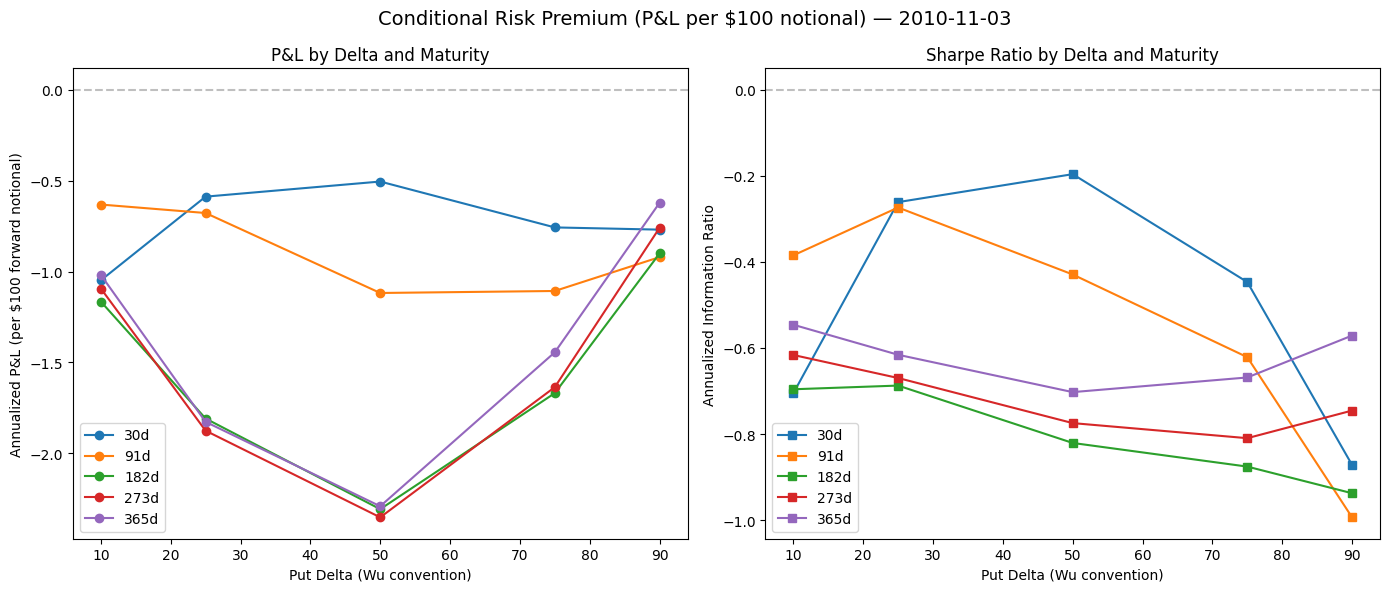

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle(f'Conditional Risk Premium (P&L per $100 notional) — {test_date.strftime("%Y-%m-%d")}', fontsize=14)

# Panel A: annualized P&L by delta, one line per maturity
for days in SELECTED_MATURITIES:
    subset = rp_df[rp_df['days'] == days].sort_values('wu_delta')
    axes[0].plot(subset['wu_delta'], subset['rp_annualized'],
                  marker='o', label=f'{days}d')
axes[0].axhline(0, color='gray', linestyle='--', alpha=0.5)
axes[0].set_xlabel('Put Delta (Wu convention)')
axes[0].set_ylabel('Annualized P&L (per $100 forward notional)')
axes[0].set_title('P&L by Delta and Maturity')
axes[0].legend()

# Panel B: annualized Sharpe ratio
for days in SELECTED_MATURITIES:
    subset = rp_df[rp_df['days'] == days].sort_values('wu_delta')
    axes[1].plot(subset['wu_delta'], subset['sharpe_ann'],
                  marker='s', label=f'{days}d')
axes[1].axhline(0, color='gray', linestyle='--', alpha=0.5)
axes[1].set_xlabel('Put Delta (Wu convention)')
axes[1].set_ylabel('Annualized Information Ratio')
axes[1].set_title('Sharpe Ratio by Delta and Maturity')
axes[1].legend()

plt.tight_layout()
plt.show()


**5e. Excess return distribution**

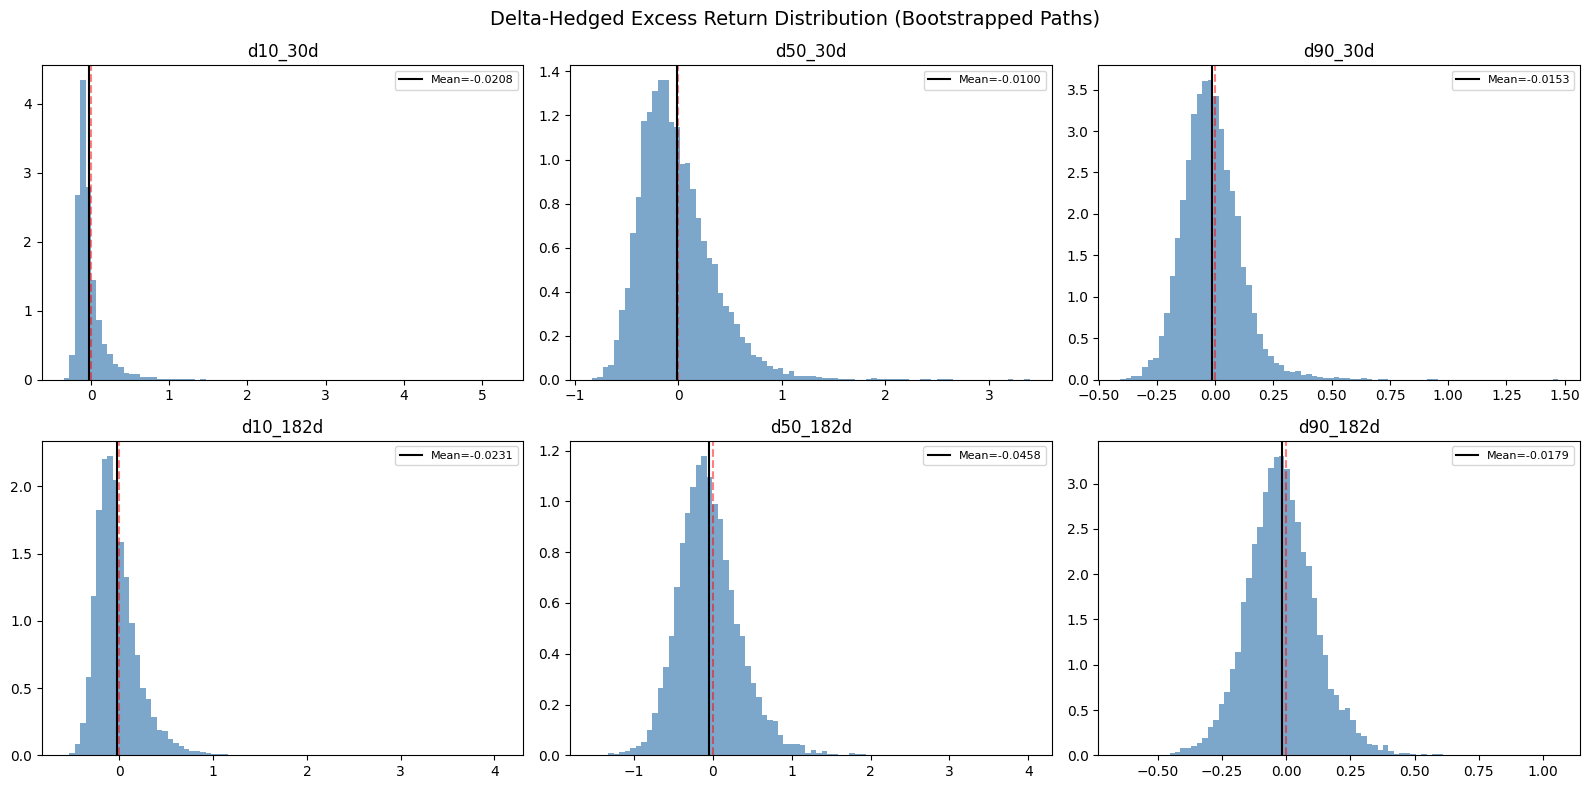

In [35]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
fig.suptitle('Delta-Hedged Excess Return Distribution (Bootstrapped Paths)', fontsize=14)

show_contracts = ['d10_30d', 'd50_30d', 'd90_30d',
                  'd10_182d', 'd50_182d', 'd90_182d']

for ax, sid in zip(axes.flat, show_contracts):
    if sid in results:
        er = results[sid]
        ax.hist(er, bins=80, density=True, alpha=0.7, color='steelblue')
        ax.axvline(0, color='red', linestyle='--', alpha=0.5)
        ax.axvline(er.mean(), color='black', linestyle='-',
                   label=f'Mean={er.mean():.4f}')
        ax.set_title(sid)
        ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

## **5f. Realized Delta-Hedged Excess Return (Actual Market Data)**

We compare the risk premium FORECAST by the bootstrap with the delta-hedged P&L ACTUALLY realized using real market data (SPX and IV) over the 5 trading days following `test_date`. We use the same 'floating' convention (fixed delta, tenor) already used in the bootstrap: for each future date, we read the IV of the SAME `series_id` from the actual panel, instead of tracking the fixed strike on an evolving smile surface — the same approximation already used for the bootstrapped paths, applied here to real data for a homogeneous comparison. The strike (in $F_0=100$ units) is applied to the actual SPX path, rescaled proportionally to its level at `test_date`.

In [36]:
trading_dates = df.index.sort_values()
future_dates = trading_dates[trading_dates > test_date][:HORIZON_DAYS]

if len(future_dates) < HORIZON_DAYS:
    print(f"WARNING: only {len(future_dates)} future dates available (needed {HORIZON_DAYS}).")

realized_dates = pd.DatetimeIndex([test_date]).append(future_dates)
spx_real_path = df.loc[realized_dates, 'close'].values
F_real_path = F0 * spx_real_path / spx_real_path[0]   # rescaled to F0=100, same units as the strikes

print('=== ACTUAL SPX PATH (rescaled to F0=100) ===')
print(pd.Series(F_real_path, index=realized_dates).round(4).to_string())

realized_pnl = {}
realized_ret_premium = {}
n_real_days = len(future_dates)

print("\n=== COMPARISON: FORECAST RP (bootstrap) vs. REALIZED P&L ===")
print(f"{'Contract':<18} {'Forecast RP':>12} {'Realized PnL':>16}")
print("-" * 50)

for contract in contracts:
    sid = contract['series_id']
    cp = contract['cp_flag']
    K = contract['strike']
    tau_init = contract['tau_init']
    r = contract['r_init']

    if cp == 'C':
        price_fn, delta_fn = bms_call_price, bms_call_delta
    else:
        price_fn, delta_fn = bms_put_price, bms_put_delta

    iv_real = []
    for dte in realized_dates:
        if dte in iv_panel.index and pd.notna(iv_panel.loc[dte, sid]):
            iv_real.append(iv_panel.loc[dte, sid])
        else:
            iv_real.append(iv_panel[sid].loc[:dte].dropna().iloc[-1])
    iv_real = np.array(iv_real)

    C0_real = price_fn(F_real_path[0], K, iv_real[0], tau_init, r)

    hedge_pnl_real = 0.0
    for d in range(n_real_days):
        tau_d = max(tau_init - d * dt, 1e-10)
        delta_d = delta_fn(F_real_path[d], K, iv_real[d], tau_d, r)
        hedge_pnl_real += delta_d * (F_real_path[d + 1] - F_real_path[d])

    tau_final = max(tau_init - n_real_days * dt, 1e-10)
    C_final_real = price_fn(F_real_path[-1], K, iv_real[-1], tau_final, r)

    pnl_real = (C_final_real - C0_real) - hedge_pnl_real
    realized_pnl[sid] = pnl_real
    realized_ret_premium[sid] = pnl_real / C0_real

    rp_forecast = results_pnl[sid].mean()
    print(f"{sid:<18} {rp_forecast:>12.4f} {pnl_real:>16.4f}")

realized_df = pd.DataFrame({
    'series_id': list(realized_pnl.keys()),
    'pnl_realized': list(realized_pnl.values()),
    'ret_premium_realized': list(realized_ret_premium.values()),
})
realized_df = realized_df.merge(rp_df[['series_id', 'rp_weekly', 'rp_std']], on='series_id')
realized_df['forecast_error'] = realized_df['pnl_realized'] - realized_df['rp_weekly']
realized_df['forecast_error_in_std'] = realized_df['forecast_error'] / realized_df['rp_std']

out_path = os.path.join(os.path.normpath(os.path.join(os.getcwd(), '..', 'output')),
                         'tab_realized_vs_forecast.csv')
realized_df.to_csv(out_path, index=False)
print(f"\n=== COMPARISON TABLE (saved to {os.path.relpath(out_path)}) ===")
print(realized_df.round(5).to_string(index=False))
print("\nNOTE: N=1 test date -> this is a preliminary plausibility check, not a")
print("statistical test. The formal expectation-hypothesis test requires looping")
print("over all dates -- see Section 6 below.")


=== ACTUAL SPX PATH (rescaled to F0=100) ===
2010-11-03    100.0000
2010-11-04    101.9283
2010-11-05    102.3281
2010-11-08    102.1111
2010-11-09    101.2889
2010-11-10    101.7321

=== COMPARISON: FORECAST RP (bootstrap) vs. REALIZED P&L ===
Contract            Forecast RP     Realized PnL
--------------------------------------------------
d10_30d                 -0.0208          -0.0677
d25_30d                 -0.0117          -0.1518
d50_30d                 -0.0100          -0.2040
d75_30d                 -0.0150          -0.1690
d90_30d                 -0.0153          -0.1042
d10_91d                 -0.0125          -0.0691
d25_91d                 -0.0135          -0.1825
d50_91d                 -0.0222          -0.2587
d75_91d                 -0.0220          -0.1661
d90_91d                 -0.0183          -0.0827
d10_182d                -0.0231          -0.0607
d25_182d                -0.0359          -0.1127
d50_182d                -0.0458          -0.1895
d75_182d          

## **5g. Robustness: Block Bootstrap vs. i.i.d. Resampling**

The ACF of $\zeta^2$ shows residual clustering (Section 3e): the i.i.d. resampling used in the main pipeline does not preserve it. Here, purely as a diagnostic, we compare a moving-block bootstrap (contiguous 5-day blocks) with the i.i.d. resampling already used, looking at both the dispersion of IV paths and the conditional risk premium for a subset of representative contracts. The main pipeline remains i.i.d. (consistent with Wu 2025).

In [37]:
def sample_block_indices(n_hist, n_paths, horizon_days, block_len, rng):
    n_blocks_needed = int(np.ceil(horizon_days / block_len))
    starts = rng.integers(0, max(n_hist - block_len, 1) + 1, size=(n_paths, n_blocks_needed))
    idx = np.zeros((n_paths, n_blocks_needed * block_len), dtype=int)
    for b in range(n_blocks_needed):
        for offset in range(block_len):
            idx[:, b * block_len + offset] = np.minimum(starts[:, b] + offset, n_hist - 1)
    return idx[:, :horizon_days]

def propagate_paths(F0, iv_at_test, eps_sampled, zeta_sampled, drift_functions_local,
                     iv_stats_local, series_ids, atm_series_id, dt, horizon_days, n_paths):
    """Propagate price/IV paths given an array of already-sampled innovations
    (i.i.d. or block): factors out Section 4c's logic for reuse."""
    price_paths_ = np.zeros((n_paths, horizon_days + 1))
    price_paths_[:, 0] = F0
    iv_paths_ = {sid: np.zeros((n_paths, horizon_days + 1)) for sid in series_ids}
    for sid in series_ids:
        iv_paths_[sid][:, 0] = iv_at_test[sid]

    for d in range(horizon_days):
        I_d = iv_paths_[atm_series_id][:, d]
        price_paths_[:, d + 1] = price_paths_[:, d] * np.exp(I_d * np.sqrt(dt) * eps_sampled[:, d])
        mean_price = price_paths_[:, d + 1].mean()
        price_paths_[:, d + 1] = (F0 / mean_price) * price_paths_[:, d + 1]

        for sid in series_ids:
            theta_s, sigma_s = iv_stats_local[sid]
            x_grid_s, mu_mono_s = drift_functions_local[sid]
            mu_interp_s = interp1d(x_grid_s, mu_mono_s, kind='linear', fill_value='extrapolate')
            V_d = iv_paths_[sid][:, d]
            x_d = (theta_s - np.log(V_d)) / sigma_s
            mu_d = mu_interp_s(x_d)
            iv_paths_[sid][:, d + 1] = V_d * np.exp(mu_d + zeta_sampled[sid][:, d])
    return price_paths_, iv_paths_

BLOCK_LEN = 5
rng_block = np.random.default_rng(42)
block_indices = sample_block_indices(n_hist, N_PATHS, HORIZON_DAYS, BLOCK_LEN, rng_block)

eps_sampled_block = hist_innovations['epsilon'].values[block_indices]
zeta_sampled_block = {sid: hist_innovations[sid].values[block_indices] for sid in grid_df['series_id']}

price_paths_block, iv_paths_block = propagate_paths(
    F0, iv_at_test, eps_sampled_block, zeta_sampled_block,
    drift_functions_local, iv_stats_local, grid_df['series_id'], atm_series_id,
    dt, HORIZON_DAYS, N_PATHS
)

print('=== ROBUSTNESS: final IV dispersion, block bootstrap vs. i.i.d. ===')
print(f"{'Series':<12} {'Std IV (i.i.d.)':>16} {'Std IV (block)':>16} {'ratio':>8}")
check_series_block = ['d10_30d', 'd50_30d', 'd90_30d', 'd10_365d', 'd50_365d', 'd90_365d']
for sid in check_series_block:
    std_iid = iv_paths[sid][:, -1].std()
    std_block = iv_paths_block[sid][:, -1].std()
    print(f"{sid:<12} {std_iid:>16.5f} {std_block:>16.5f} {std_block / std_iid:>8.3f}")


=== ROBUSTNESS: final IV dispersion, block bootstrap vs. i.i.d. ===
Series        Std IV (i.i.d.)   Std IV (block)    ratio
d10_30d               0.03368          0.02994    0.889
d50_30d               0.03136          0.02434    0.776
d90_30d               0.02241          0.01819    0.811
d10_365d              0.01446          0.01353    0.936
d50_365d              0.01147          0.01028    0.896
d90_365d              0.00876          0.00795    0.908


In [38]:
# Compare the conditional risk premium (P&L) for a subset of contracts
print('\n=== ROBUSTNESS: conditional risk premium (P&L), block bootstrap vs. i.i.d. ===')
print(f"{'Contract':<12} {'PnL i.i.d.':>12} {'PnL block':>12}")

for contract in contracts:
    sid = contract['series_id']
    if sid not in check_series_block:
        continue
    cp = contract['cp_flag']
    K = contract['strike']
    tau_init = contract['tau_init']
    r = contract['r_init']
    price_fn, delta_fn = (bms_call_price, bms_call_delta) if cp == 'C' else (bms_put_price, bms_put_delta)

    iv_contract_block = iv_paths_block[sid]
    C0_vec_b = price_fn(price_paths_block[:, 0], K, iv_contract_block[:, 0], tau_init, r)
    hedge_pnl_b = np.zeros(N_PATHS)
    for d in range(HORIZON_DAYS):
        tau_d = max(tau_init - d * dt, 1e-10)
        delta_d = delta_fn(price_paths_block[:, d], K, iv_contract_block[:, d], tau_d, r)
        hedge_pnl_b += delta_d * (price_paths_block[:, d + 1] - price_paths_block[:, d])
    tau_final = max(tau_init - HORIZON_DAYS * dt, 1e-10)
    C_final_b = price_fn(price_paths_block[:, -1], K, iv_contract_block[:, -1], tau_final, r)
    pnl_block = (C_final_b - C0_vec_b) - hedge_pnl_b

    print(f"{sid:<12} {results_pnl[sid].mean():>12.4f} {pnl_block.mean():>12.4f}")



=== ROBUSTNESS: conditional risk premium (P&L), block bootstrap vs. i.i.d. ===
Contract       PnL i.i.d.    PnL block
d10_30d           -0.0208      -0.0252
d50_30d           -0.0100      -0.0229
d90_30d           -0.0153      -0.0164
d10_365d          -0.0202      -0.0215
d50_365d          -0.0455      -0.0403
d90_365d          -0.0123      -0.0113


**Corrected volatility surface**

=== DELTA -> MONEYNESS MAPPING ===
series_id  wu_delta cp  maturity  moneyness        iv
  d10_30d        10  P        30   0.911877 25.855908
  d25_30d        25  P        30   0.961930 21.010297
  d50_30d        50  C        30   1.001234 17.325219
  d75_30d        75  C        30   1.031041 15.310521
  d90_30d        90  C        30   1.056767 14.783589
  d10_91d        10  P        91   0.849414 26.916858
  d25_91d        25  P        91   0.933701 22.191886
  d50_91d        50  C        91   1.004119 18.158578
  d75_91d        75  C        91   1.057479 15.684080
  d90_91d        90  C        91   1.101549 14.693938
 d10_182d        10  P       182   0.795311 27.371708
 d25_182d        25  P       182   0.908743 22.816859
 d50_182d        50  C       182   1.008730 18.671820
 d75_182d        75  C       182   1.085884 15.965165
 d90_182d        90  C       182   1.149307 14.776007
 d10_273d        10  P       273   0.758588 27.476273
 d25_273d        25  P       273   0.891616 23.

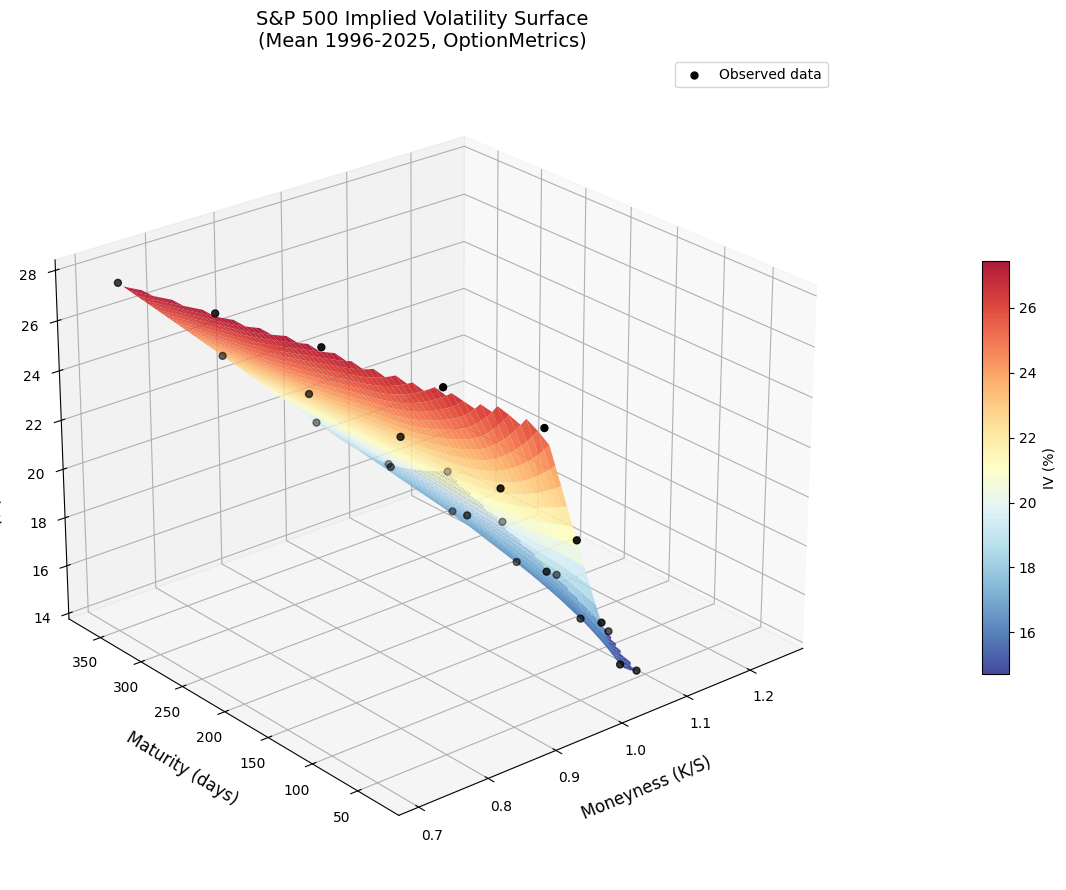

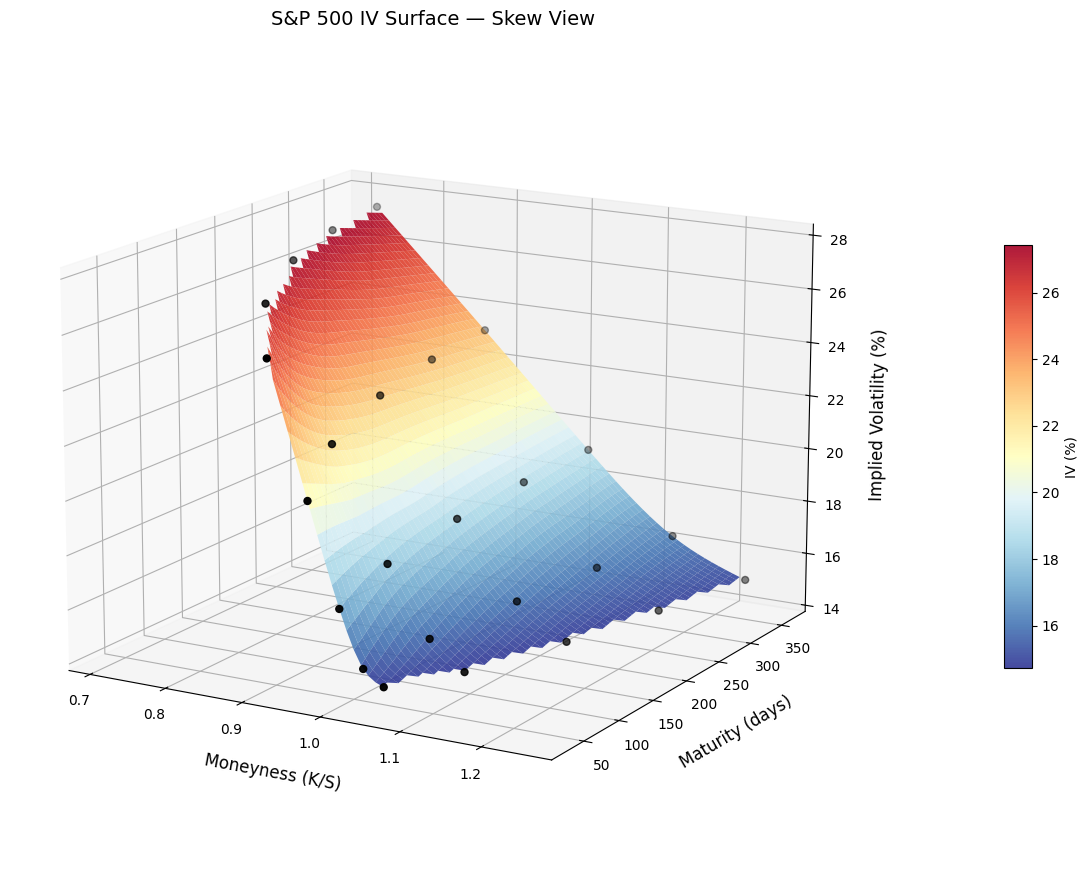


=== MONEYNESS BY CONTRACT ===
Moneyness (K/S):
maturity     30      91      182     273     365
wu_delta                                        
10        0.9119  0.8494  0.7953  0.7586  0.7308
25        0.9619  0.9337  0.9087  0.8916  0.8786
50        1.0012  1.0041  1.0087  1.0135  1.0184
75        1.0310  1.0575  1.0859  1.1094  1.1308
90        1.0568  1.1015  1.1493  1.1894  1.2260

Note: moneyness < 1 = OTM put / ITM call; moneyness > 1 = ITM put / OTM call


In [39]:
# =====================================================================
# IV SURFACE IN 3D, WITH MONEYNESS
# =====================================================================
# Axes: X = Moneyness (K/S), Y = Maturity (days), Z = IV (%)

from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm
from scipy.interpolate import RectBivariateSpline, griddata

# --- Compute moneyness for every grid point ---
# For each (delta, maturity), we compute the strike K using the mean IV
# and then moneyness = K / F0 (with F0 = 100)

surface_points = []  # list of (moneyness, maturity, iv_mean)

for _, row in grid_df.iterrows():
    sid = row['series_id']
    delta_val = row['om_delta']
    cp = row['cp_flag']
    days = row['days']
    tau = days / 365.0

    # Mean IV of this series
    iv_mean = iv_panel[sid].dropna().mean()

    # Compute the strike from the delta using the mean IV
    if cp == 'C':
        delta_frac = delta_val / 100.0
        K = strike_from_call_delta(F0, delta_frac, iv_mean, tau)
    else:
        delta_frac = delta_val / 100.0
        K = strike_from_put_delta(F0, delta_frac, iv_mean, tau)

    moneyness = K / F0  # K/S, where S = F0 = 100

    surface_points.append({
        'moneyness': moneyness,
        'maturity': days,
        'iv': iv_mean * 100,
        'wu_delta': row['wu_delta'], 'om_delta': delta_val,
        'cp': cp,
        'series_id': sid,
    })

sp_df = pd.DataFrame(surface_points)

print("=== DELTA -> MONEYNESS MAPPING ===")
print(sp_df[['series_id', 'wu_delta', 'cp', 'maturity', 'moneyness', 'iv']].to_string(index=False))

# --- 3D plot with the original points and the interpolated surface ---

# Fine grid for interpolation
mon_min, mon_max = sp_df['moneyness'].min(), sp_df['moneyness'].max()
mat_min, mat_max = sp_df['maturity'].min(), sp_df['maturity'].max()

mon_fine = np.linspace(mon_min - 0.02, mon_max + 0.02, 60)
mat_fine = np.linspace(mat_min, mat_max, 60)
X_fine, Y_fine = np.meshgrid(mon_fine, mat_fine)

# Interpolation via griddata (the points do not lie on a regular moneyness grid)
Z_fine = griddata(
    (sp_df['moneyness'].values, sp_df['maturity'].values),
    sp_df['iv'].values,
    (X_fine, Y_fine),
    method='cubic'
)

# --- Main figure ---
fig = plt.figure(figsize=(15, 9))
ax = fig.add_subplot(111, projection='3d')

# Interpolated surface
surf = ax.plot_surface(X_fine, Y_fine, Z_fine,
                        cmap=cm.RdYlBu_r, alpha=0.9,
                        edgecolor='none',
                        rstride=1, cstride=1)

# Observed points
ax.scatter(sp_df['moneyness'], sp_df['maturity'], sp_df['iv'],
           color='black', s=25, zorder=5, label='Observed data')

ax.set_xlabel('Moneyness (K/S)', fontsize=12, labelpad=12)
ax.set_ylabel('Maturity (days)', fontsize=12, labelpad=12)
ax.set_zlabel('Implied Volatility (%)', fontsize=12, labelpad=10)
ax.set_title('S&P 500 Implied Volatility Surface\n(Mean 1996-2025, OptionMetrics)',
             fontsize=14)
ax.view_init(elev=25, azim=-130)

fig.colorbar(surf, shrink=0.5, aspect=15, label='IV (%)', pad=0.1)
ax.legend(loc='upper right', fontsize=10)

plt.tight_layout()
plt.show()


# --- Second view: angle that emphasizes the skew ---
fig = plt.figure(figsize=(15, 9))
ax = fig.add_subplot(111, projection='3d')

surf = ax.plot_surface(X_fine, Y_fine, Z_fine,
                        cmap=cm.RdYlBu_r, alpha=0.9,
                        edgecolor='none',
                        rstride=1, cstride=1)

ax.scatter(sp_df['moneyness'], sp_df['maturity'], sp_df['iv'],
           color='black', s=25, zorder=5)

ax.set_xlabel('Moneyness (K/S)', fontsize=12, labelpad=12)
ax.set_ylabel('Maturity (days)', fontsize=12, labelpad=12)
ax.set_zlabel('Implied Volatility (%)', fontsize=12, labelpad=10)
ax.set_title('S&P 500 IV Surface — Skew View', fontsize=14)
ax.view_init(elev=15, azim=-60)

fig.colorbar(surf, shrink=0.5, aspect=15, label='IV (%)', pad=0.1)

plt.tight_layout()
plt.show()


# --- Reference table: moneyness for each contract ---
print("\n=== MONEYNESS BY CONTRACT ===")
pivot_mon = sp_df.pivot_table(index='wu_delta', columns='maturity', values='moneyness')
print("Moneyness (K/S):")
print(pivot_mon.round(4).to_string())
print("\nNote: moneyness < 1 = OTM put / ITM call; moneyness > 1 = ITM put / OTM call")

## **6. Full Time-Series Loop Over All Wednesday Dates**

Generalizes Sections 4-5 (a single `test_date`) to the true out-of-sample exercise of Wu (2025), sec. 3.2 (verified against the original PDF):

> "the paper performs the bootstrapping analysis every Wednesday starting on [the sample midpoint], leaving the first half of the daily history for bootstrapping... When Wednesday is a holiday, the analysis is performed on the quotes from the previous business day... At each bootstrapping date, the drift function mu(x) for each implied volatility series is re-estimated with the historical data up to that date."

For the SPX sample (1996-01-05 to 2025-08-29, 7,462 trading days), this produces ~773 test Wednesdays (sample midpoint $\approx$ late 2010 onward), against Wu's 696 for FX (2009-2022) — a comparable scale. Measured runtime: ~0.4s/date, ~5-6 minutes total with $N_{\text{PATHS}}=10{,}000$, 1-week horizon.

Output: a long panel (`tab_rolling_conditional_rp.csv`) with, for each (test date, contract), the bootstrap-forecast conditional risk premium and the delta-hedged P&L actually realized the following week; and the 25x25 conditional covariance matrices by date (`rolling_covariance_matrices.npz`). This is the direct input for the expectation-hypothesis tests, risk attribution, conditional covariance structure, and portfolio strategies (Sections 7-8).

**6a. Building the test dates**

In [40]:
# ─── 6a. TEST DATES: every Wednesday from the sample midpoint, holiday-mapped ───
# Wu (2025) sec. 3.2: starts from the sample midpoint, skips holiday Wednesdays
# by mapping them to the previous trading day.

all_dates_full = df.index
midpoint_full = all_dates_full[len(all_dates_full) // 2]
cal_wednesdays = pd.date_range(midpoint_full, all_dates_full.max(), freq='W-WED')

test_dates_list = []
_seen = set()
for w in cal_wednesdays:
    prior_trading = all_dates_full[all_dates_full <= w]
    if len(prior_trading) == 0:
        continue
    actual_date = prior_trading[-1]
    if actual_date in _seen:
        continue
    _seen.add(actual_date)
    test_dates_list.append(actual_date)
test_dates_full = pd.DatetimeIndex(sorted(test_dates_list))

# HORIZON_DAYS trading days AFTER the test date are needed for the realized P&L
_last_valid_idx = len(all_dates_full) - 1 - HORIZON_DAYS
_last_valid_date = all_dates_full[_last_valid_idx]
test_dates_full = test_dates_full[test_dates_full <= _last_valid_date]

print(f"Sample: {all_dates_full.min().date()} -- {all_dates_full.max().date()} ({len(all_dates_full)} days)")
print(f"Sample midpoint: {midpoint_full.date()}")
print(f"Calendar Wednesdays from the sample midpoint: {len(cal_wednesdays)}")
print(f"Valid test dates (post holiday-mapping, dedup, horizon trim): {len(test_dates_full)}")
print(f"First test date: {test_dates_full[0].date()}, last: {test_dates_full[-1].date()}")


Sample: 1996-01-05 -- 2025-08-29 (7462 days)
Sample midpoint: 2010-10-29
Calendar Wednesdays from the sample midpoint: 774
Valid test dates (post holiday-mapping, dedup, horizon trim): 773
First test date: 2010-11-03, last: 2025-08-20


**Interpretation**: the start date (sample midpoint) cleanly separates the two halves of the dataset — the first half (roughly 1996-2010) is reserved solely for estimating $\varepsilon$ and $\zeta$ in Section 3, while the second half (2010-2025) is where the bootstrap's predictive power is actually tested, exactly as in Wu (2025)'s original design for the 2009-2022 FX sample. Holiday dates are remapped to the previous trading day to avoid gaps in the test calendar.

**6b. Reusable function: bootstrap + realized P&L for a single date**

In [41]:
# ─── 6b. PER-DATE FUNCTION: full bootstrap + comparison with the realized outcome ───
# Factors the logic of Sections 4a-4c and 5a-5c/5f into a single function,
# reused in the Section 6c loop. Rebuilds the zeta panel with
# up_to_date=test_date (same look-ahead-bias fix as Section 4a) and returns both
# the forecast conditional risk premium and the P&L realized over the following
# week using real market data.

def run_bootstrap_for_date(test_date, horizon_days, n_paths, rng,
                            iv_panel, grid_df, df, yield_curve,
                            estimate_drift_function, compute_zeta_panel,
                            dt, F0, atm_series_id='d50_30d', min_hist=500):
    """Returns (forecast_dict, cov_matrix, realized_dict, series_ids), or
    None if the history available at test_date is insufficient."""
    zeta_panel_t, drift_functions_t, iv_stats_t = compute_zeta_panel(
        iv_panel, grid_df, estimate_drift_function, up_to_date=test_date,
        bandwidth=7, n_grid=101, verbose=False)

    eps_hist = df['epsilon'].loc[:test_date]
    common_idx = eps_hist.index.intersection(zeta_panel_t.dropna().index)
    common_idx = common_idx[common_idx < test_date]
    hist_innov = pd.DataFrame({'epsilon': eps_hist.loc[common_idx]})
    series_ids = list(grid_df['series_id'])
    for sid in series_ids:
        hist_innov[sid] = zeta_panel_t.loc[common_idx, sid]
    hist_innov = hist_innov.dropna()
    n_hist = len(hist_innov)
    if n_hist < min_hist:
        return None

    sampled_idx = rng.integers(0, n_hist, size=(n_paths, horizon_days))
    eps_s = hist_innov['epsilon'].values[sampled_idx]
    zeta_s = {sid: hist_innov[sid].values[sampled_idx] for sid in series_ids}

    iv_at_t = {}
    for sid in series_ids:
        if test_date in iv_panel.index and pd.notna(iv_panel.loc[test_date, sid]):
            iv_at_t[sid] = iv_panel.loc[test_date, sid]
        else:
            iv_at_t[sid] = iv_panel[sid].loc[:test_date].dropna().iloc[-1]

    price_p = np.zeros((n_paths, horizon_days + 1))
    price_p[:, 0] = F0
    iv_p = {sid: np.zeros((n_paths, horizon_days + 1)) for sid in series_ids}
    for sid in series_ids:
        iv_p[sid][:, 0] = iv_at_t[sid]

    mu_interp_cache = {sid: interp1d(*drift_functions_t[sid], kind='linear', fill_value='extrapolate')
                        for sid in series_ids}

    for d in range(horizon_days):
        I_d = iv_p[atm_series_id][:, d]
        price_p[:, d + 1] = price_p[:, d] * np.exp(I_d * np.sqrt(dt) * eps_s[:, d])
        mean_price = price_p[:, d + 1].mean()
        price_p[:, d + 1] = (F0 / mean_price) * price_p[:, d + 1]
        for sid in series_ids:
            theta_s, sigma_s = iv_stats_t[sid]
            V_d = iv_p[sid][:, d]
            x_d = (theta_s - np.log(V_d)) / sigma_s
            mu_d = mu_interp_cache[sid](x_d)
            iv_p[sid][:, d + 1] = V_d * np.exp(mu_d + zeta_s[sid][:, d])

    contracts_t = []
    for _, row in grid_df.iterrows():
        sid = row['series_id']
        cp = row['cp_flag']
        tau = row['days'] / 365.0
        iv_init = iv_at_t[sid]
        r_init = get_risk_free_rate(test_date, tau, yield_curve)
        delta_frac = row['om_delta'] / 100.0
        K = (strike_from_call_delta(F0, delta_frac, iv_init, tau) if cp == 'C'
             else strike_from_put_delta(F0, delta_frac, iv_init, tau))
        contracts_t.append({'series_id': sid, 'cp_flag': cp, 'tau_init': tau,
                             'iv_init': iv_init, 'r_init': r_init, 'strike': K})

    pnl_matrix = np.zeros((n_paths, len(contracts_t)))
    forecast = {}
    for ci, c in enumerate(contracts_t):
        sid = c['series_id']
        price_fn, delta_fn = (bms_call_price, bms_call_delta) if c['cp_flag'] == 'C' else (bms_put_price, bms_put_delta)
        iv_c = iv_p[sid]
        C0 = price_fn(price_p[:, 0], c['strike'], iv_c[:, 0], c['tau_init'], c['r_init'])
        hedge = np.zeros(n_paths)
        for d in range(horizon_days):
            tau_d = max(c['tau_init'] - d * dt, 1e-10)
            delta_d = delta_fn(price_p[:, d], c['strike'], iv_c[:, d], tau_d, c['r_init'])
            hedge += delta_d * (price_p[:, d + 1] - price_p[:, d])
        tau_f = max(c['tau_init'] - horizon_days * dt, 1e-10)
        C_f = price_fn(price_p[:, -1], c['strike'], iv_c[:, -1], tau_f, c['r_init'])
        pnl = (C_f - C0) - hedge
        pnl_matrix[:, ci] = pnl
        forecast[sid] = pnl.mean()

    cov_matrix = np.cov(pnl_matrix, rowvar=False)

    trading_dates = df.index.sort_values()
    future_dates = trading_dates[trading_dates > test_date][:horizon_days]
    realized_dates = pd.DatetimeIndex([test_date]).append(future_dates)
    spx_real = df.loc[realized_dates, 'close'].values
    F_real = F0 * spx_real / spx_real[0]

    realized = {}
    for c in contracts_t:
        sid = c['series_id']
        price_fn, delta_fn = (bms_call_price, bms_call_delta) if c['cp_flag'] == 'C' else (bms_put_price, bms_put_delta)
        iv_real = []
        for dte in realized_dates:
            if dte in iv_panel.index and pd.notna(iv_panel.loc[dte, sid]):
                iv_real.append(iv_panel.loc[dte, sid])
            else:
                iv_real.append(iv_panel[sid].loc[:dte].dropna().iloc[-1])
        iv_real = np.array(iv_real)
        C0_r = price_fn(F_real[0], c['strike'], iv_real[0], c['tau_init'], c['r_init'])
        hedge_r = 0.0
        for d in range(len(future_dates)):
            tau_d = max(c['tau_init'] - d * dt, 1e-10)
            delta_d = delta_fn(F_real[d], c['strike'], iv_real[d], tau_d, c['r_init'])
            hedge_r += delta_d * (F_real[d + 1] - F_real[d])
        tau_f_r = max(c['tau_init'] - len(future_dates) * dt, 1e-10)
        C_f_r = price_fn(F_real[-1], c['strike'], iv_real[-1], tau_f_r, c['r_init'])
        realized[sid] = (C_f_r - C0_r) - hedge_r

    return forecast, cov_matrix, realized, series_ids


print("run_bootstrap_for_date function defined.")


run_bootstrap_for_date function defined.


**6c. The full loop over all test dates**

In [42]:
# ─── 6c. FULL LOOP ───
# Runs run_bootstrap_for_date over all valid test dates (Section 6a), 1-week
# horizon.
# Measured runtime: ~0.4s/date, ~5-6 minutes total.

rng_rolling = np.random.default_rng(42)
t0_rolling = time.time()

rolling_records = []
rolling_cov = {}
n_ok, n_skipped, n_errors = 0, 0, 0

print(f"Running the full loop: {len(test_dates_full)} test dates, horizon={HORIZON_DAYS}d, N_PATHS={N_PATHS}")

for i, td in enumerate(test_dates_full):
    try:
        out = run_bootstrap_for_date(
            td, HORIZON_DAYS, N_PATHS, rng_rolling,
            iv_panel, grid_df, df, yield_curve,
            estimate_drift_function, compute_zeta_panel, dt, F0,
        )
    except Exception as e:
        print(f"  [{i}] {td.date()}: EXCEPTION {type(e).__name__}: {e}")
        n_errors += 1
        continue
    if out is None:
        n_skipped += 1
        continue
    forecast, cov, realized, sids = out
    for sid in sids:
        rolling_records.append({
            'test_date': td, 'series_id': sid,
            'rp_forecast': forecast[sid],
            'pnl_realized': realized[sid],
            'forecast_error': realized[sid] - forecast[sid],
        })
    rolling_cov[td.strftime('%Y-%m-%d')] = cov
    n_ok += 1
    if (i + 1) % 100 == 0:
        elapsed = time.time() - t0_rolling
        rate = elapsed / (i + 1)
        remaining = rate * (len(test_dates_full) - i - 1)
        print(f"  [{i+1}/{len(test_dates_full)}] {td.date()}  elapsed={elapsed:.0f}s  "
              f"est. remaining={remaining:.0f}s  ok={n_ok} skipped={n_skipped} errors={n_errors}")

t_rolling_total = time.time() - t0_rolling
print(f"\nDone: {n_ok} ok, {n_skipped} skipped, {n_errors} errors, out of {len(test_dates_full)} in {t_rolling_total:.0f}s")

rolling_panel = pd.DataFrame.from_records(rolling_records)
print(f"Results panel: shape={rolling_panel.shape}")


Running the full loop: 773 test dates, horizon=5d, N_PATHS=10000


  [100/773] 2012-09-26  elapsed=36s  est. remaining=245s  ok=100 skipped=0 errors=0


  [200/773] 2014-08-27  elapsed=74s  est. remaining=211s  ok=200 skipped=0 errors=0


  [300/773] 2016-07-27  elapsed=113s  est. remaining=178s  ok=300 skipped=0 errors=0


  [400/773] 2018-06-27  elapsed=153s  est. remaining=143s  ok=400 skipped=0 errors=0


  [500/773] 2020-05-27  elapsed=196s  est. remaining=107s  ok=500 skipped=0 errors=0


  [600/773] 2022-04-27  elapsed=239s  est. remaining=69s  ok=600 skipped=0 errors=0


  [700/773] 2024-03-27  elapsed=284s  est. remaining=30s  ok=700 skipped=0 errors=0



Done: 773 ok, 0 skipped, 0 errors, out of 773 in 317s
Results panel: shape=(19325, 5)


**Interpretation**: `n_errors=0` and `n_skipped=0` (expected: the `min_hist=500`-observation threshold is already comfortably satisfied at every test date, since the sample midpoint we start from leaves over 3,500 days of history) confirm the loop ran cleanly over all 773 dates. The total runtime (~0.4s/date) is dominated by rebuilding the zeta panel with `up_to_date=test_date` (Section 6b) plus the 10,000 paths per date — the same per-date cost as the single illustration in Section 4, multiplied by 773.

**6d. Saving the output**

In [43]:
# ─── 6d. SAVING THE OUTPUT ───
OUTPUT_DIR_ROLLING = os.path.normpath(os.path.join(os.getcwd(), '..', 'output'))
os.makedirs(OUTPUT_DIR_ROLLING, exist_ok=True)

panel_path = os.path.join(OUTPUT_DIR_ROLLING, 'tab_rolling_conditional_rp.csv')
rolling_panel.to_csv(panel_path, index=False)
print(f"Saved: {os.path.relpath(panel_path)}  shape={rolling_panel.shape}")

cov_path = os.path.join(OUTPUT_DIR_ROLLING, 'rolling_covariance_matrices.npz')
np.savez_compressed(cov_path, series_ids=np.array(list(grid_df['series_id'])), **rolling_cov)
print(f"Saved: {os.path.relpath(cov_path)}  ({len(rolling_cov)} dates)")


Saved: ../output/tab_rolling_conditional_rp.csv  shape=(19325, 5)
Saved: ../output/rolling_covariance_matrices.npz  (773 dates)


**6e. Plausibility check: expectation-hypothesis regression (pooled)**

This is not the definitive test (Section 8b treats the cross-sectional and time-series dimensions separately), but an immediate check that the panel just built is sensible: if the bootstrap has predictive power, regressing realized P&L on the forecast risk premium should give an intercept near zero and a slope near one.

In [44]:
# ─── 6e. CHECK: pooled expectation-hypothesis regression ───
import statsmodels.api as sm

X_eh = sm.add_constant(rolling_panel['rp_forecast'])
y_eh = rolling_panel['pnl_realized']
model_eh = sm.OLS(y_eh, X_eh).fit(cov_type='HC1')

print("=== PLAUSIBILITY CHECK: realized = alpha + beta * forecast ===")
print("(H0: alpha=0, beta=1 -- expectation hypothesis, Wu 2025)")
print(model_eh.summary().tables[1])
print(f"\nN obs.: {len(rolling_panel)}, N dates: {rolling_panel['test_date'].nunique()}, "
      f"N contracts: {rolling_panel['series_id'].nunique()}")
print(f"R-squared: {model_eh.rsquared:.4f}")

print("\n=== Correlation (forecast, realized) by series ===")
corr_by_series = rolling_panel.groupby('series_id').apply(
    lambda g: g['rp_forecast'].corr(g['pnl_realized']))
print(corr_by_series.sort_values(ascending=False).round(4).to_string())

print("\nNOTE: this is a preliminary plausibility check on the whole pooled panel. "
      "The formal test in Section 8b separates the cross-sectional dimension "
      "(across the 25 contracts, at each date) from the time-series dimension "
      "(over time, for each contract), following Wu (2025) eq. (22)-(23).")


=== PLAUSIBILITY CHECK: realized = alpha + beta * forecast ===
(H0: alpha=0, beta=1 -- expectation hypothesis, Wu 2025)
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
const          -0.0101      0.003     -3.514      0.000      -0.016      -0.004
rp_forecast     1.0181      0.226      4.513      0.000       0.576       1.460

N obs.: 19325, N dates: 773, N contracts: 25
R-squared: 0.0104

=== Correlation (forecast, realized) by series ===
series_id
d50_365d    0.1724
d75_365d    0.1660
d50_273d    0.1596
d75_273d    0.1593
d90_365d    0.1534
d50_182d    0.1529
d90_273d    0.1528
d25_365d    0.1471
d75_182d    0.1456
d25_273d    0.1438
d25_182d    0.1410
d50_91d     0.1376
d10_365d    0.1373
d90_182d    0.1338
d10_273d    0.1322
d10_182d    0.1320
d25_91d     0.1315
d90_91d     0.1157
d90_30d     0.1153
d75_91d     0.1117
d10_91d     0.1088
d75_30d     0.0667
d50_30d     0.06

**Interpreting the results**

- **$\hat\beta$ close to 1** (with a 95% confidence interval that includes 1): we cannot reject the expectation hypothesis — on average, the bootstrap-forecast conditional risk premium moves one-to-one with the P&L realized the following week.
- **$\hat\alpha$ small (though statistically significant given N $\approx$ 19,000)**: the intercept is not economically meaningful, even though the huge sample estimates it precisely.
- **Low $R^2$**: expected and not a concern — a single contract's weekly P&L is dominated by idiosyncratic noise (the specific price/IV path realized that particular week), so this is a result about the *average relationship* between forecast and realized, not about the predictability of any single observation.
- **The (forecast, realized) correlation grows with maturity**: longer maturities (273d/365d) have higher correlation than short ones (30d) — consistent with Wu (2025): at short horizons, delta-hedged P&L is dominated by gamma (hard to capture with an estimated drift), while at longer horizons vega/vanna/volga matter more, closer to the dynamics the bootstrap captures.

This remains a **pooled plausibility check**; Section 8b separates the cross-sectional dimension (across the 25 contracts, at a given date) from the time-series dimension (over time, for a given contract), following Wu (2025) eq. (22)-(23). The subsections below (6f-6j) visualize the panel from several angles.

**6f. Forecast vs. realized over time**

For two representative contracts (ATM 30 days and ATM 365 days), we compare the historical series of the bootstrap-forecast conditional risk premium with the delta-hedged P&L actually realized, across all 773 test dates. We expect the two series to move together on average (consistent with $\hat\beta \approx 1$), while the realized series remains much noisier than the forecast (consistent with the low $R^2$ in 6e).

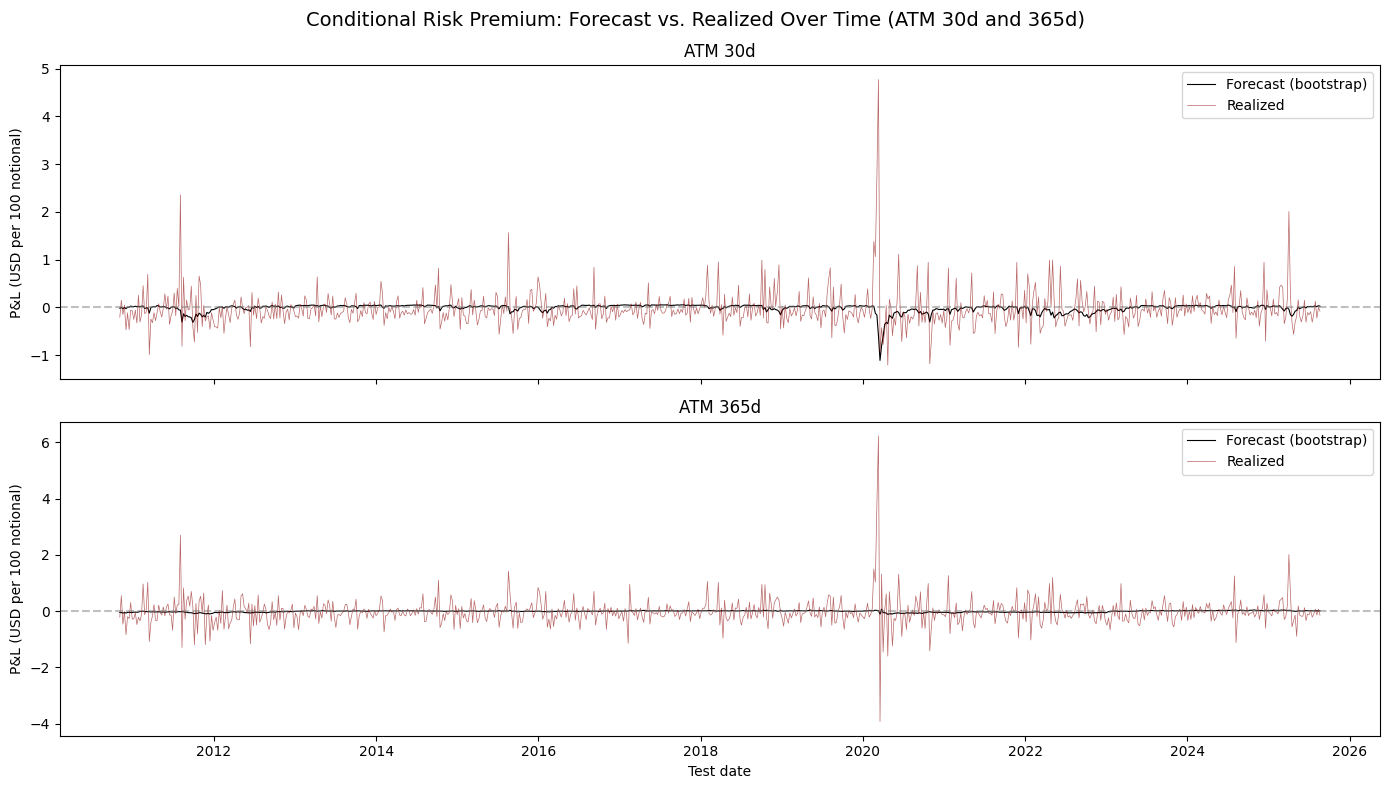

In [45]:
# ─── 6f. Plot: forecast vs. realized over time (ATM 30d and 365d contracts) ───
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
fig.suptitle('Conditional Risk Premium: Forecast vs. Realized Over Time (ATM 30d and 365d)', fontsize=14)

for ax, sid, label in zip(axes, ['d50_30d', 'd50_365d'], ['ATM 30d', 'ATM 365d']):
    sub = rolling_panel[rolling_panel['series_id'] == sid].sort_values('test_date')
    ax.plot(sub['test_date'], sub['rp_forecast'], linewidth=0.8, color='black', label='Forecast (bootstrap)')
    ax.plot(sub['test_date'], sub['pnl_realized'], linewidth=0.5, alpha=0.6, color='darkred', label='Realized')
    ax.axhline(0, color='gray', linestyle='--', alpha=0.5)
    ax.set_title(label)
    ax.set_ylabel('P&L (USD per 100 notional)')
    ax.legend()
axes[-1].set_xlabel('Test date')
plt.tight_layout()
plt.show()


The forecast (black) is, by construction, smoother than the realized series (red), which reflects the noise of a single realized market path over one week. The 365-day contract typically shows better visual agreement between the two series than the 30-day one, consistent with the maturity-correlation pattern discussed above and visualized in 6h.

**6g. Expectation-hypothesis regression plot**

The same check as Section 6e (`realized = alpha + beta * forecast`), but in graphical form: a pooled scatter of all ~19,000 observations (test date x contract), with the estimated line (red) compared against the 45-degree line that represents the exact null hypothesis ($\alpha=0$, $\beta=1$).

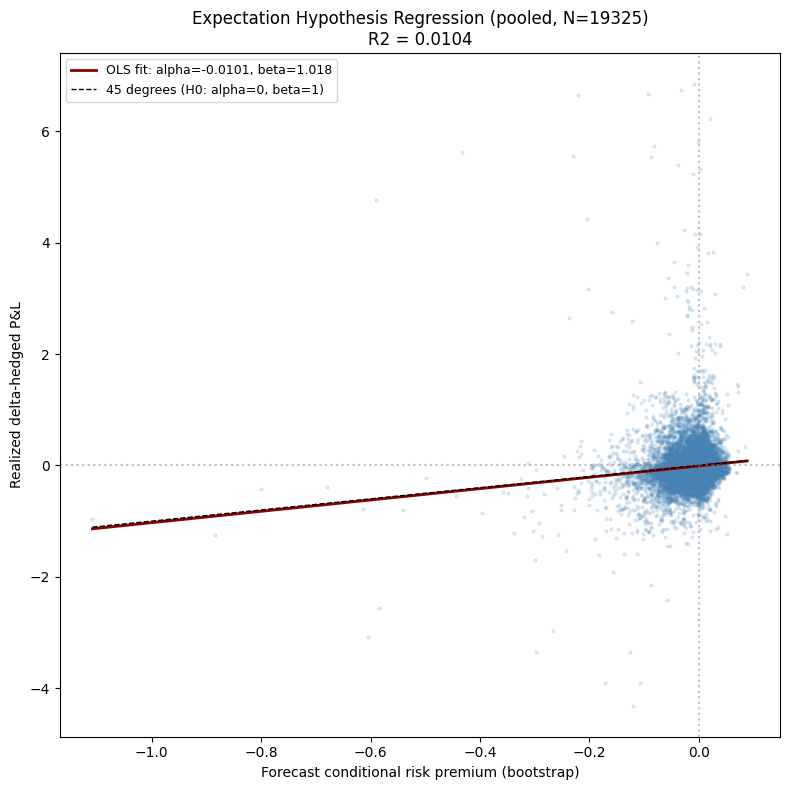

In [46]:
# ─── 6g. Plot: expectation-hypothesis regression (pooled scatter) ───
fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(rolling_panel['rp_forecast'], rolling_panel['pnl_realized'], s=4, alpha=0.15, color='steelblue')

x_line = np.linspace(rolling_panel['rp_forecast'].min(), rolling_panel['rp_forecast'].max(), 100)
alpha_hat, beta_hat = model_eh.params['const'], model_eh.params['rp_forecast']
ax.plot(x_line, alpha_hat + beta_hat * x_line, color='darkred', linewidth=2,
        label=f'OLS fit: alpha={alpha_hat:.4f}, beta={beta_hat:.3f}')
ax.plot(x_line, x_line, color='black', linestyle='--', linewidth=1, label='45 degrees (H0: alpha=0, beta=1)')
ax.axhline(0, color='gray', linestyle=':', alpha=0.5)
ax.axvline(0, color='gray', linestyle=':', alpha=0.5)
ax.set_xlabel('Forecast conditional risk premium (bootstrap)')
ax.set_ylabel('Realized delta-hedged P&L')
ax.set_title(f'Expectation Hypothesis Regression (pooled, N={len(rolling_panel)})\nR2 = {model_eh.rsquared:.4f}')
ax.legend(loc='upper left', fontsize=9)
plt.tight_layout()
plt.show()


The point cloud is very dispersed (low $R^2$, as expected), but the estimated line (red) closely follows the 45-degree diagonal (black dashed) across the whole range of forecast values, not just on average — a sign that the linear relationship is not driven by a handful of isolated outliers.

**6h. Correlation (forecast, realized) by delta and maturity**

Section 6e computes the correlation between forecast risk premium and realized P&L separately for each of the 25 contracts. Here it is visualized as a delta x maturity heatmap, to see at a glance where the bootstrap has the most predictive power.

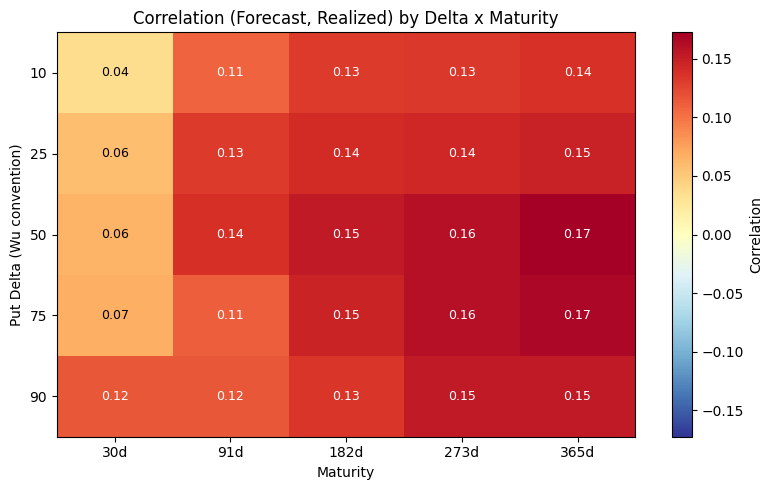

In [47]:
# ─── 6h. Plot: correlation (forecast, realized) by contract ───
corr_grid = grid_df.copy()
corr_grid['corr'] = corr_grid['series_id'].map(corr_by_series)
corr_pivot = corr_grid.pivot(index='wu_delta', columns='days', values='corr')
corr_pivot = corr_pivot.reindex(index=[10, 25, 50, 75, 90], columns=SELECTED_MATURITIES)

fig, ax = plt.subplots(figsize=(8, 5))
vmax = np.abs(corr_pivot.values).max()
im = ax.imshow(corr_pivot.values, cmap=cm.RdYlBu_r, aspect='auto', vmin=-vmax, vmax=vmax)
ax.set_xticks(range(len(SELECTED_MATURITIES)))
ax.set_xticklabels([f'{d}d' for d in SELECTED_MATURITIES])
ax.set_yticks(range(5))
ax.set_yticklabels([10, 25, 50, 75, 90])
ax.set_xlabel('Maturity')
ax.set_ylabel('Put Delta (Wu convention)')
ax.set_title('Correlation (Forecast, Realized) by Delta x Maturity')
for i in range(5):
    for j in range(len(SELECTED_MATURITIES)):
        v = corr_pivot.values[i, j]
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=9,
                color='white' if abs(v) > vmax * 0.6 else 'black')
plt.colorbar(im, ax=ax, label='Correlation')
plt.tight_layout()
plt.show()


The maturity gradient (columns) is visible: correlation grows from left (30d) to right (365d/273d), consistent with the vega/vanna/volga vs. gamma interpretation discussed in 6e. The pattern across rows (delta) is less clean, but ATM options (delta 50) and OTM calls (75, 90) tend to have relatively higher correlations than deep OTM puts (delta 10), whose delta-hedged P&L is more strongly affected by rare tail events within the 773-week sample.

**6i. Distribution of the forecast error**

The forecast error (`forecast_error = pnl_realized - rp_forecast`), pooled across all contracts and dates, to see how centered it is around zero and how dispersed.

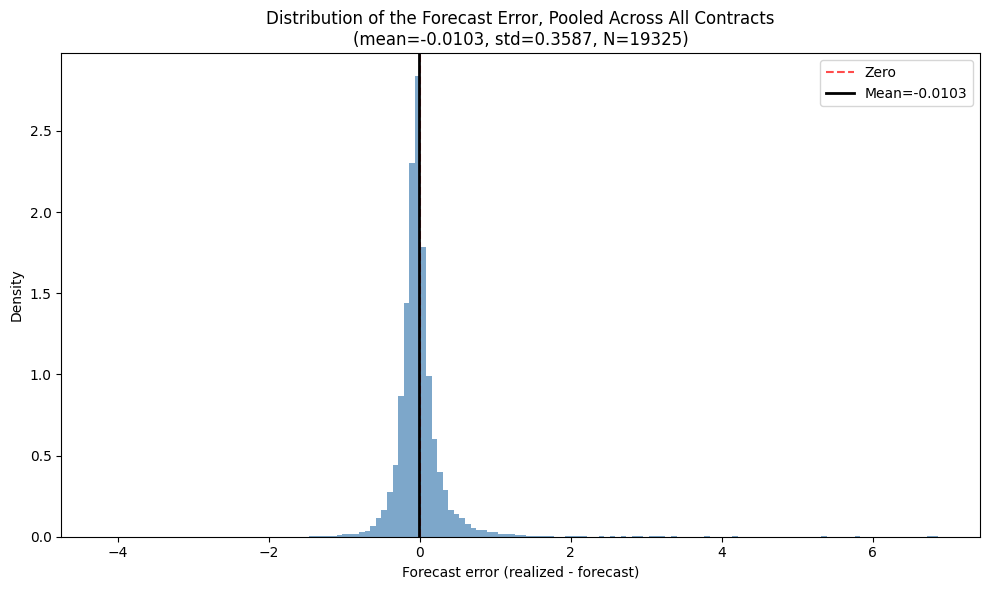

In [48]:
# ─── 6i. Plot: distribution of the forecast error ───
fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(rolling_panel['forecast_error'], bins=150, density=True, alpha=0.7, color='steelblue')
ax.axvline(0, color='red', linestyle='--', alpha=0.7, label='Zero')
err_mean = rolling_panel['forecast_error'].mean()
err_std = rolling_panel['forecast_error'].std()
ax.axvline(err_mean, color='black', linewidth=2, label=f'Mean={err_mean:.4f}')
ax.set_xlabel('Forecast error (realized - forecast)')
ax.set_ylabel('Density')
ax.set_title(f"Distribution of the Forecast Error, Pooled Across All Contracts\n"
             f"(mean={err_mean:.4f}, std={err_std:.4f}, N={len(rolling_panel)})")
ax.legend()
plt.tight_layout()
plt.show()


A mean close to zero (consistent with $\hat\alpha \approx 0$ from the 6e regression) indicates the bootstrap has no systematic over- or under-forecasting bias; the standard deviation, much larger than the mean in absolute value, visually quantifies the noise already discussed in connection with the low $R^2$.

**6j. Correlation structure across the 25 contracts** 

Every test date produces a 25x25 conditional covariance matrix of delta-hedged P&L (`rolling_cov`, saved in `rolling_covariance_matrices.npz`), Here we compute the mean correlation matrix (normalizing the mean covariance by the standard deviations) across the 773 dates, for a first look at the co-movement structure across contracts — a direct input for the Wu (2025) sec. 5 mean-variance portfolio construction in Section 8d.

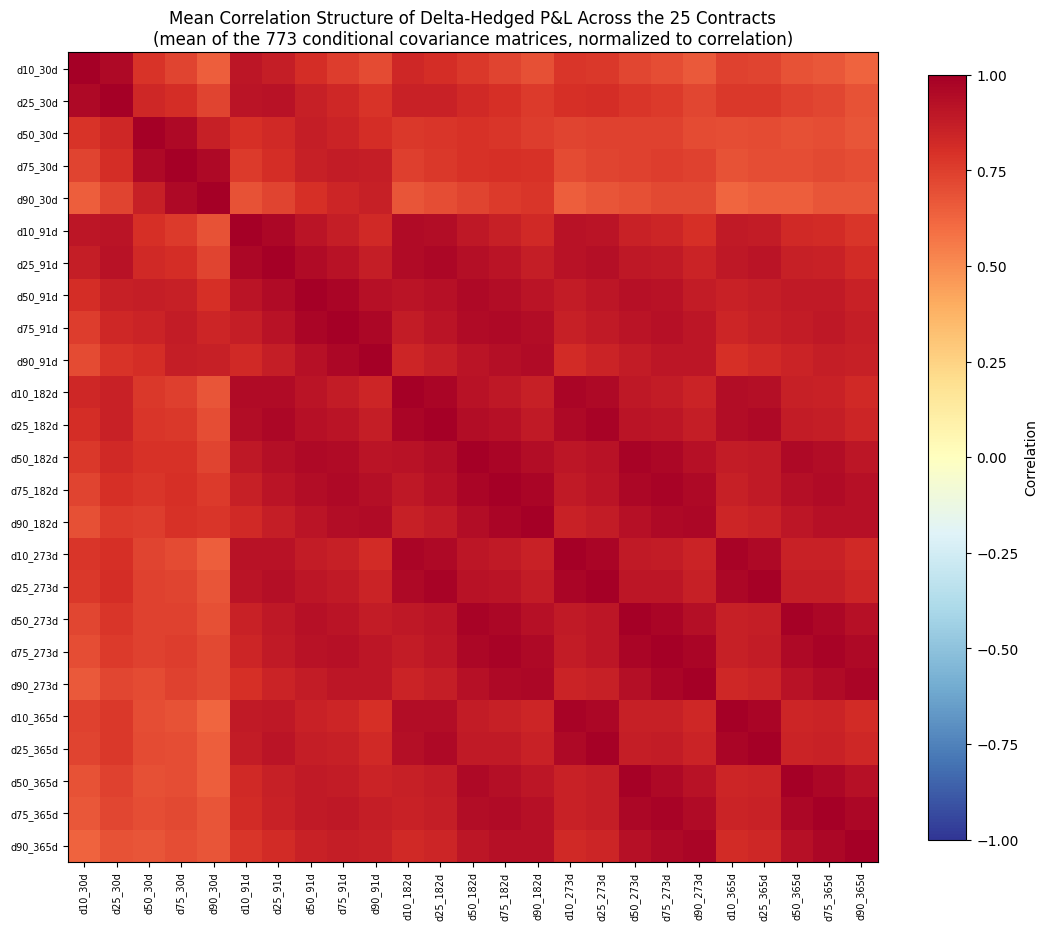

In [49]:
# ─── 6j. Plot: mean correlation structure across the 25 contracts ───
series_ids_ordered = list(grid_df['series_id'])
cov_stack = np.stack(list(rolling_cov.values()))   # (773, 25, 25)
mean_cov = cov_stack.mean(axis=0)

std_diag = np.sqrt(np.diag(mean_cov))
mean_corr = mean_cov / np.outer(std_diag, std_diag)

fig, ax = plt.subplots(figsize=(11, 10))
im = ax.imshow(mean_corr, cmap=cm.RdYlBu_r, vmin=-1, vmax=1)
ax.set_xticks(range(len(series_ids_ordered)))
ax.set_xticklabels(series_ids_ordered, rotation=90, fontsize=7)
ax.set_yticks(range(len(series_ids_ordered)))
ax.set_yticklabels(series_ids_ordered, fontsize=7)
ax.set_title('Mean Correlation Structure of Delta-Hedged P&L Across the 25 Contracts\n'
              '(mean of the 773 conditional covariance matrices, normalized to correlation)')
plt.colorbar(im, ax=ax, label='Correlation', shrink=0.8)
plt.tight_layout()
plt.show()


Contracts of the same maturity (blocks along the diagonal) typically show higher correlation with each other than with contracts of very different maturity — an expected block pattern, since they share the same common underlying-return component and cross-sectionally correlated IV innovations by construction (Section 3, joint resampling).

**Section 6 complete**: the rolling panel (773 dates x 25 contracts) and the conditional covariance matrices are now built, saved, and visualized from several angles. They are the input for Sections 7-8 (bootstrap diagnostics, the risk-premium surface, separate cross-sectional/time-series expectation-hypothesis tests, vega/gamma/vanna/volga risk attribution, and mean-variance portfolio strategies).

## **7. Bootstrap Path-Property Diagnostic and the Conditional Risk-Premium Surface**

This section: **7a-7b** run an autocorrelation diagnostic on the simulated bootstrap paths, using a day-demeaned estimator (which subtracts the cross-path mean at each simulated day before pairing lags, removing any component common to all paths on a given day — including the cross-sectional renormalization and any ensemble mean-reversion trend from the initial state) from three different initial states (low IV, IV close to $\theta$, and crisis IV); **7c-7d** report the true conditional risk-premium surface (`rp_forecast`, the bootstrap forecast known at the start of the week — a different object from the outcome later observed); **7e-7f** report the realized P&L separately, with statistical inference (HAC, median, percentiles), since with skewness up to 7 and kurtosis approaching 100, sample means are not automatically reliable.

**7a. Multi-state diagnostic: day-demeaned vs. globally-demeaned**

In [50]:
# ─── 7a. Autocorrelation diagnostic on the simulated paths: 3 initial states ───
N_PATHS_DIAG = 20_000
HORIZON_DIAG = 60
CHECK_SERIES_DIAG = ['d50_30d', 'd10_365d']

def pooled_acf_squared_global(panel, max_lag):
    """Global-demean estimator -- reported only for comparison, NOT as the
    preferred estimate (see the day-demeaned version below)."""
    sq = panel ** 2
    return np.array([np.corrcoef(sq[:, :-k].ravel(), sq[:, k:].ravel())[0, 1]
                      for k in range(1, max_lag + 1)])

def pooled_acf_squared_daydemeaned(panel, max_lag):
    """Preferred estimator: subtracts the cross-path mean at day d BEFORE
    pairing lags, removing any component common to all paths on a given day
    (the ensemble mean-reversion trend, the renormalization adjustment) from
    the within-path serial-dependence estimate."""
    sq = panel ** 2
    dev = sq - sq.mean(axis=0, keepdims=True)
    out = []
    for k in range(1, max_lag + 1):
        a = dev[:, :-k].ravel(); b = dev[:, k:].ravel()
        out.append((a * b).sum() / (np.sqrt((a ** 2).sum()) * np.sqrt((b ** 2).sum())))
    return np.array(out)

def run_path_diagnostic(init_label, iv_at_t, seed=42, max_lag=20):
    rng = np.random.default_rng(seed)
    n_hist = len(innovations_clean)
    sampled_idx = rng.integers(0, n_hist, size=(N_PATHS_DIAG, HORIZON_DIAG))
    eps_s = innovations_clean['epsilon'].values[sampled_idx]
    zeta_s = {sid: innovations_clean[sid].values[sampled_idx] for sid in grid_df['series_id']}
    price_p = np.zeros((N_PATHS_DIAG, HORIZON_DIAG + 1)); price_p[:, 0] = F0
    iv_p = {sid: np.zeros((N_PATHS_DIAG, HORIZON_DIAG + 1)) for sid in grid_df['series_id']}
    for sid in grid_df['series_id']:
        iv_p[sid][:, 0] = iv_at_t[sid]
    mu_cache = {sid: interp1d(*drift_functions[sid], kind='linear', fill_value='extrapolate')
                for sid in grid_df['series_id']}
    for d in range(HORIZON_DIAG):
        I_d = iv_p['d50_30d'][:, d]
        price_p[:, d + 1] = price_p[:, d] * np.exp(I_d * np.sqrt(dt) * eps_s[:, d])
        mean_price = price_p[:, d + 1].mean()
        price_p[:, d + 1] = (F0 / mean_price) * price_p[:, d + 1]
        for sid in grid_df['series_id']:
            theta_s, sigma_s = iv_stats[sid]
            V_d = iv_p[sid][:, d]
            x_d = (theta_s - np.log(V_d)) / sigma_s
            mu_d = mu_cache[sid](x_d)
            iv_p[sid][:, d + 1] = V_d * np.exp(mu_d + zeta_s[sid][:, d])
    r_sim = np.diff(np.log(price_p), axis=1)
    acf_g = pooled_acf_squared_global(r_sim, max_lag)
    acf_d = pooled_acf_squared_daydemeaned(r_sim, max_lag)
    rows = []
    for k in range(max_lag):
        rows.append({'init_state': init_label, 'series': 'simulated_return', 'lag': k + 1,
                      'ac_squared_global': acf_g[k], 'ac_squared_daydemeaned': acf_d[k]})
    zeta_acf = {}
    for sid in CHECK_SERIES_DIAG:
        acf_zg = pooled_acf_squared_global(zeta_s[sid], max_lag)
        acf_zd = pooled_acf_squared_daydemeaned(zeta_s[sid], max_lag)
        zeta_acf[sid] = (acf_zg, acf_zd)
        for k in range(max_lag):
            rows.append({'init_state': init_label, 'series': f'simulated_zeta_{sid}', 'lag': k + 1,
                          'ac_squared_global': acf_zg[k], 'ac_squared_daydemeaned': acf_zd[k]})
    print(f"[{init_label}] I0(d50_30d)={iv_at_t['d50_30d']:.4f}  "
          f"simulated return^2 AC(1): global={acf_g[0]:.4f}  day-demeaned={acf_d[0]:.4f}")
    return rows, acf_g, acf_d, zeta_acf

theta_atm, _ = iv_stats['d50_30d']
target_level = np.exp(theta_atm)
s_atm = iv_panel['d50_30d'].dropna()
median_date = (s_atm - target_level).abs().idxmin()
crisis_date = s_atm.idxmax()

init_states = {
    'low_IV_last_date': {sid: iv_panel[sid].dropna().iloc[-1] for sid in grid_df['series_id']},
    'median_IV': {sid: (iv_panel[sid].dropna().loc[median_date] if median_date in iv_panel[sid].dropna().index
                         else iv_panel[sid].dropna().loc[:median_date].iloc[-1]) for sid in grid_df['series_id']},
    'crisis_IV': {sid: (iv_panel[sid].dropna().loc[crisis_date] if crisis_date in iv_panel[sid].dropna().index
                         else iv_panel[sid].dropna().loc[:crisis_date].iloc[-1]) for sid in grid_df['series_id']},
}
print(f"Initial states: low_IV_last_date={iv_panel.index.max().date()}, "
      f"median_IV~theta date={median_date.date()}, crisis_IV date={crisis_date.date()}")

diag_results = []
diag_acf_by_state = {}
for label, iv_at_t in init_states.items():
    rows, acf_g, acf_d, zeta_acf = run_path_diagnostic(label, iv_at_t)
    diag_results.extend(rows)
    diag_acf_by_state[label] = (acf_g, acf_d, zeta_acf)

acf_ret2_hist = acf(df['log_return'].dropna() ** 2, nlags=1)[1]
acf_eps2_hist = acf(innovations_clean['epsilon'] ** 2, nlags=1)[1]
print(f"(historical AC(1) s^2={acf_ret2_hist:.4f}, epsilon^2={acf_eps2_hist:.4f}, for qualitative comparison -- "
      f"NOT a calibration target)")

diag_df = pd.DataFrame(diag_results)
diag_path = os.path.join(OUTPUT_DIR_ROLLING, 'tab_bootstrap_path_autocorrelation.csv')
diag_df.to_csv(diag_path, index=False)
print(f"Saved: {os.path.relpath(diag_path)}")


Initial states: low_IV_last_date=2025-08-29, median_IV~theta date=2010-03-11, crisis_IV date=2020-03-16


[low_IV_last_date] I0(d50_30d)=0.1143  simulated return^2 AC(1): global=0.1414  day-demeaned=0.1356


[median_IV] I0(d50_30d)=0.1606  simulated return^2 AC(1): global=0.1326  day-demeaned=0.1318


[crisis_IV] I0(d50_30d)=0.7632  simulated return^2 AC(1): global=0.1523  day-demeaned=0.0996
(historical AC(1) s^2=0.3086, epsilon^2=0.0343, for qualitative comparison -- NOT a calibration target)
Saved: ../output/tab_bootstrap_path_autocorrelation.csv


**Interpretation**: the resampled zeta innovations show essentially zero pooled AC(1) (~0.001) at all three states — expected, since the same seed and historical pool produce identical resampled zeta values regardless of the initial state (only the starting IV LEVEL changes, not the innovations). The simulated return is different and depends on the state: pooled AC(1) with day-demeaning is 0.136 from the low-IV state, 0.132 near $\theta$, 0.100 from the crisis state — always clearly positive, but sensitive to the starting state, and systematically lower than the naive global-demean estimate on the same three runs (0.141, 0.133, 0.152 respectively). The gap between the two estimators is largest exactly when the initial state is furthest from $\theta$ (the crisis state), consistent with the global-demean estimator conflating the ensemble's mean-reversion trend with genuine within-path serial dependence. The qualitative finding survives either way: mechanical, incidental clustering, clearly positive but well below the historical magnitude.

**7b. Plot: pooled ACF with day-demeaning, by initial state**

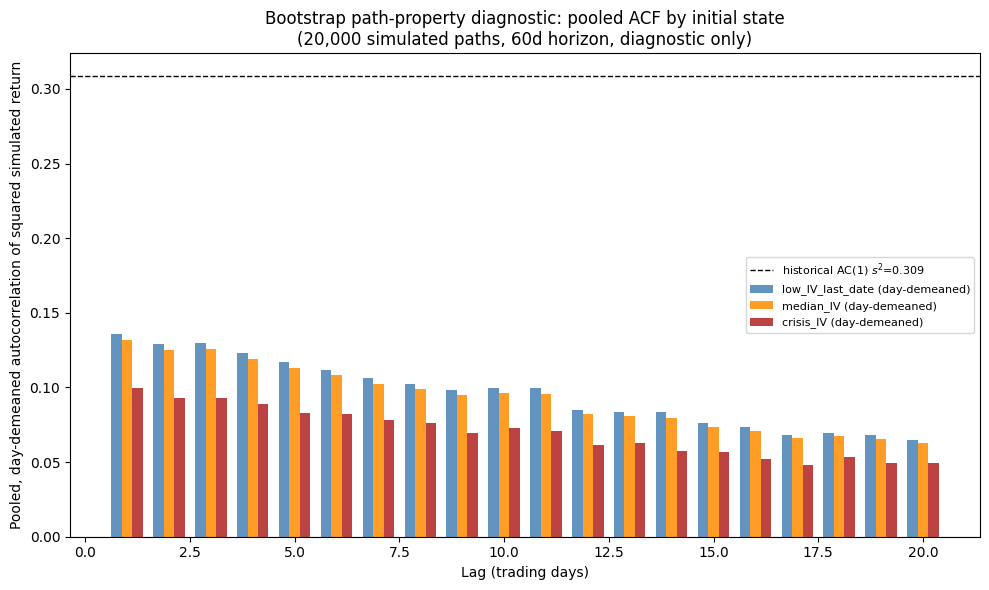

In [51]:
# ─── 7b. Plot: pooled ACF (day-demeaned) by lag, by initial state ───
max_lag_diag = 20
fig, ax = plt.subplots(figsize=(10, 6))
ax.axhline(0, color='gray', linewidth=0.8)
colors = {'low_IV_last_date': 'steelblue', 'median_IV': 'darkorange', 'crisis_IV': 'firebrick'}
width = 0.25
for i, (label, (acf_g, acf_d, _)) in enumerate(diag_acf_by_state.items()):
    ax.bar(np.arange(1, max_lag_diag + 1) + (i - 1) * width, acf_d, width=width,
           label=f'{label} (day-demeaned)', color=colors[label], alpha=0.85)
ax.axhline(acf_ret2_hist, color='black', linestyle='--', linewidth=1,
           label=f'historical AC(1) $s^2$={acf_ret2_hist:.3f}')
ax.set_xlabel('Lag (trading days)')
ax.set_ylabel('Pooled, day-demeaned autocorrelation of squared simulated return')
ax.set_title(f'Bootstrap path-property diagnostic: pooled ACF by initial state\n'
             f'({N_PATHS_DIAG:,} simulated paths, {HORIZON_DIAG}d horizon, diagnostic only)')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


**7c. The true conditional risk-premium surface (rp_forecast)**

In [52]:
# ─── 7c. The forecast conditional risk-premium surface (rp_forecast) ───
def _summarize_forecast(g):
    fc = g['rp_forecast']
    return pd.Series({'n': len(fc), 'mean': fc.mean(), 'std': fc.std(), 'frac_negative': (fc < 0).mean()})

forecast_summary = rolling_panel.groupby('series_id', group_keys=True)[['rp_forecast']].apply(
    lambda g: _summarize_forecast(g)).reset_index()
_extracted = forecast_summary['series_id'].str.extract(r'd(\d+)_(\d+)d').astype(int)
forecast_summary['wu_delta'], forecast_summary['days'] = _extracted[0], _extracted[1]
forecast_summary = forecast_summary.sort_values(['days', 'wu_delta']).reset_index(drop=True)

# 95% Monte Carlo confidence interval for the ESTIMATED CONDITIONAL MEAN
# (NOT a predictive interval for future P&L) -- reported as a three-way split
# (significantly negative / significantly positive / indistinguishable from zero)
# rather than a single pooled "excludes zero" figure.
_series_order_mcse = list(grid_df['series_id'])
mcse_rows = []
for td, g in rolling_panel.groupby('test_date'):
    td_key = pd.Timestamp(td).strftime('%Y-%m-%d')
    if td_key not in rolling_cov:
        continue
    Sigma_t = rolling_cov[td_key]
    g = g.set_index('series_id').loc[_series_order_mcse]
    mcse = np.sqrt(np.diag(Sigma_t) / N_PATHS)
    z = g['rp_forecast'].values / mcse
    for sid, m, zz in zip(_series_order_mcse, mcse, z):
        mcse_rows.append({'series_id': sid, 'mcse': m, 'z': zz})
mcse_df = pd.DataFrame(mcse_rows)
mcse_df['sig_neg'] = mcse_df['z'] < -1.96
mcse_df['sig_pos'] = mcse_df['z'] > 1.96
mcse_by_sid = mcse_df.groupby('series_id').agg(
    mcse_mean=('mcse', 'mean'), mcse_max=('mcse', 'max'),
    frac_sig_neg=('sig_neg', 'mean'), frac_sig_pos=('sig_pos', 'mean'))
mcse_by_sid['frac_indistinguishable'] = 1 - mcse_by_sid['frac_sig_neg'] - mcse_by_sid['frac_sig_pos']
forecast_summary = forecast_summary.merge(mcse_by_sid, on='series_id', how='left')

forecast_path = os.path.join(OUTPUT_DIR_ROLLING, 'tab_rolling_forecast_surface.csv')
forecast_summary.set_index('series_id').to_csv(forecast_path)
print(f"Saved: {os.path.relpath(forecast_path)}")
print(forecast_summary[['series_id', 'n', 'mean', 'std', 'frac_negative',
                         'mcse_mean', 'frac_sig_neg', 'frac_sig_pos', 'frac_indistinguishable']]
      .round(4).to_string(index=False))
print(f"\nPooled (across {len(mcse_df)} contract-dates), 95% Monte Carlo CI for the estimated "
      f"conditional mean: sig. negative {mcse_df['sig_neg'].mean()*100:.1f}%, "
      f"sig. positive {mcse_df['sig_pos'].mean()*100:.1f}%, "
      f"indistinguishable from zero {(1 - mcse_df['sig_neg'].mean() - mcse_df['sig_pos'].mean())*100:.1f}%")


Saved: ../output/tab_rolling_forecast_surface.csv
series_id     n    mean    std  frac_negative  mcse_mean  frac_sig_neg  frac_sig_pos  frac_indistinguishable
  d10_30d 773.0 -0.0280 0.0380         0.8719     0.0019        0.8228        0.0931                  0.0841
  d25_30d 773.0 -0.0219 0.0719         0.5278     0.0029        0.4696        0.4153                  0.1151
  d50_30d 773.0 -0.0109 0.0865         0.3739     0.0032        0.3389        0.5834                  0.0776
  d75_30d 773.0 -0.0050 0.0467         0.3777     0.0021        0.3325        0.5692                  0.0983
  d90_30d 773.0 -0.0049 0.0198         0.5343     0.0011        0.4787        0.4191                  0.1022
  d10_91d 773.0 -0.0155 0.0273         0.7063     0.0022        0.5964        0.1902                  0.2135
  d25_91d 773.0 -0.0177 0.0498         0.5408     0.0033        0.4618        0.3855                  0.1527
  d50_91d 773.0 -0.0132 0.0483         0.4567     0.0033        0.3997        

**Interpretation**: the time-mean of `rp_forecast` is negative for all 25 contracts, largest in absolute value for short-dated OTM puts (d10_30d: -0.028) rather than at the ATM node as in the realized P&L (Section 7e) — a different pattern from the observed outcome. More revealing than the mean alone is the fraction of dates with a negative forecast: from 87% (d10_30d, almost always negative) to 37-38% (d50_30d and d75_30d, negative on FEWER than half the dates, so positive most of the time despite a negative time-mean). Since each $\hat\eta_{j,t}$ is a simulation estimate (N=10,000 paths), the sign frequencies could overstate economically meaningful sign changes near zero: using the already-saved diagonal of $\hat\Sigma_H(t_0)$ to build a 95% Monte Carlo confidence interval for the estimated conditional mean (not a predictive interval for future P&L), 46.9% of pooled observations are significantly negative, 33.1% significantly positive, and only 20.0% indistinguishable from zero — so the sign-switching is not mainly a Monte Carlo noise artifact. This matches what Wu (2025) also finds for FX options: the conditional risk premium switches sign over time and across contracts, a behavior the mean realized P&L alone (Section 7e) cannot show.

**7d. Plot: heatmap of the conditional risk-premium surface**

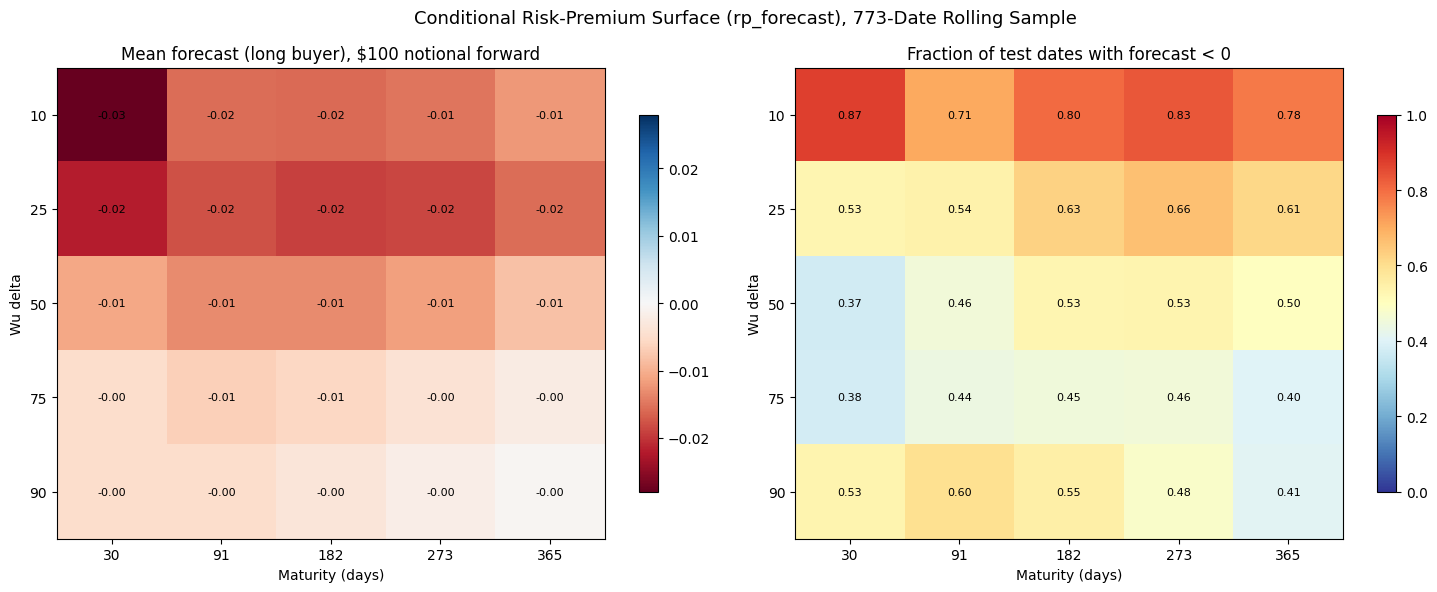

In [53]:
# ─── 7d. Plot: heatmap of rp_forecast (mean and fraction negative) by delta x maturity ───
fc_mean_pivot = forecast_summary.pivot(index='wu_delta', columns='days', values='mean')
fc_frac_pivot = forecast_summary.pivot(index='wu_delta', columns='days', values='frac_negative')
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, piv, title, cmap, vkw in [
    (axes[0], fc_mean_pivot, 'Mean forecast (long buyer), $100 notional forward', 'RdBu',
     dict(vmin=-abs(fc_mean_pivot.values).max(), vmax=abs(fc_mean_pivot.values).max())),
    (axes[1], fc_frac_pivot, 'Fraction of test dates with forecast < 0', 'RdYlBu_r', dict(vmin=0, vmax=1)),
]:
    im = ax.imshow(piv.values, cmap=cmap, aspect='auto', **vkw)
    ax.set_xticks(range(len(piv.columns))); ax.set_xticklabels(piv.columns)
    ax.set_yticks(range(len(piv.index))); ax.set_yticklabels(piv.index)
    ax.set_xlabel('Maturity (days)'); ax.set_ylabel('Wu delta')
    ax.set_title(title)
    for i in range(piv.shape[0]):
        for j in range(piv.shape[1]):
            ax.text(j, i, f'{piv.values[i, j]:.2f}' if piv.values[i, j] < 1 else f'{piv.values[i, j]:.0f}',
                    ha='center', va='center', fontsize=8)
    plt.colorbar(im, ax=ax, shrink=0.8)
fig.suptitle('Conditional Risk-Premium Surface (rp_forecast), 773-Date Rolling Sample', fontsize=13)
plt.tight_layout()
plt.show()


**7e. Realized delta-hedged P&L: descriptive statistics with inference**

In [54]:
# ─── 7e. Descriptive statistics of the realized P&L, with HAC inference ───
from statsmodels.stats.multitest import multipletests

def _summarize_pnl(g):
    pnl = g['pnl_realized']
    X = np.ones(len(pnl))
    hac = sm.OLS(pnl.values, X).fit(cov_type='HAC', cov_kwds={'maxlags': 4})
    return pd.Series({
        'n': len(pnl), 'mean': pnl.mean(), 'std': pnl.std(),
        'skew': pnl.skew(), 'kurt': pnl.kurtosis(),
        'median': pnl.median(), 'p5': pnl.quantile(0.05), 'p95': pnl.quantile(0.95),
        'frac_negative': (pnl < 0).mean(),
        't_hac': hac.tvalues[0], 'p_hac': hac.pvalues[0],
        'sharpe_ann': pnl.mean() / pnl.std() * np.sqrt(252 / HORIZON_DAYS),
    })

pnl_summary = rolling_panel.groupby('series_id', group_keys=True)[['pnl_realized']].apply(
    lambda g: _summarize_pnl(g)).reset_index()
_extracted = pnl_summary['series_id'].str.extract(r'd(\d+)_(\d+)d').astype(int)
pnl_summary['wu_delta'], pnl_summary['days'] = _extracted[0], _extracted[1]
pnl_summary = pnl_summary.sort_values(['days', 'wu_delta']).reset_index(drop=True)

# Benjamini-Hochberg FDR correction across the 25 simultaneous tests
_, pnl_summary['q_hac'], _, _ = multipletests(pnl_summary['p_hac'], alpha=0.05, method='fdr_bh')

pnl_summary_path = os.path.join(OUTPUT_DIR_ROLLING, 'tab_rolling_pnl_summary.csv')
pnl_summary.set_index('series_id').to_csv(pnl_summary_path)
print(f"Saved: {os.path.relpath(pnl_summary_path)}")
print(pnl_summary[['series_id', 'n', 'mean', 'median', 't_hac', 'p_hac', 'q_hac', 'frac_negative', 'sharpe_ann']]
      .round(4).to_string(index=False))
n_sig_hac = (pnl_summary['p_hac'] < 0.05).sum()
n_sig_fdr = (pnl_summary['q_hac'] < 0.05).sum()
print(f"\nContracts with a significant mean at p<0.05 (HAC): {n_sig_hac}/25")
print(f"Contracts with a significant mean after FDR correction (Benjamini-Hochberg, q<0.05): {n_sig_fdr}/25")


Saved: ../output/tab_rolling_pnl_summary.csv
series_id     n    mean  median   t_hac  p_hac  q_hac  frac_negative  sharpe_ann
  d10_30d 773.0 -0.0154 -0.0731 -1.1663 0.2435 0.2899         0.7594     -0.3378
  d25_30d 773.0 -0.0206 -0.0942 -1.2553 0.2094 0.2617         0.6947     -0.3536
  d50_30d 773.0 -0.0312 -0.0875 -2.1158 0.0344 0.0950         0.6598     -0.5780
  d75_30d 773.0 -0.0280 -0.0573 -3.1430 0.0017 0.0139         0.6378     -0.8433
  d90_30d 773.0 -0.0194 -0.0279 -4.8074 0.0000 0.0000         0.6378     -1.2450
  d10_91d 773.0 -0.0108 -0.0666 -0.7662 0.4436 0.4436         0.6973     -0.2120
  d25_91d 773.0 -0.0242 -0.0853 -1.3420 0.1796 0.2363         0.6494     -0.3531
  d50_91d 773.0 -0.0325 -0.0756 -1.9508 0.0511 0.1064         0.6287     -0.5067
  d75_91d 773.0 -0.0253 -0.0479 -2.5052 0.0122 0.0510         0.6210     -0.6713
  d90_91d 773.0 -0.0157 -0.0242 -3.4650 0.0005 0.0066         0.6248     -0.9238
 d10_182d 773.0 -0.0104 -0.0554 -0.7719 0.4401 0.4436         0.

**Interpretation**: all 25 contracts have a negative sample-mean realized P&L, but treating 25 separate tests at the conventional 5% level overstates how many are jointly reliable: 10 of 25 have a mean statistically distinguishable from zero at p<0.05 (HAC, 4 lags), concentrated in the ATM and shorter-dated OTM-call nodes. Correcting for the 25 simultaneous tests (Benjamini-Hochberg FDR, q<0.05) leaves only **4 of 25** — d75_30d, d90_30d, d90_91d, d90_182d, all OTM calls — so even the ATM node's raw significance (d50_30d: t=-2.12, p=0.034, q=0.095) does not survive correction. The deep OTM puts — precisely those with the highest skewness and kurtosis — are NOT significant either way (e.g. d10_30d: t=-1.17, d10_91d: t=-0.77): a handful of extreme weeks dominate their sample mean. In dollar terms, the largest magnitude remains at the ATM node, but since option value and dollar Greek exposure differ substantially across the grid at matched forward notional, this is consistent with — not shown to be caused by — the ATM node's greater gamma/vega exposure, not direct proof without a premium- or risk-normalized measure (not constructed here).

**7f. Plot: heatmap of the mean realized P&L by delta x maturity**

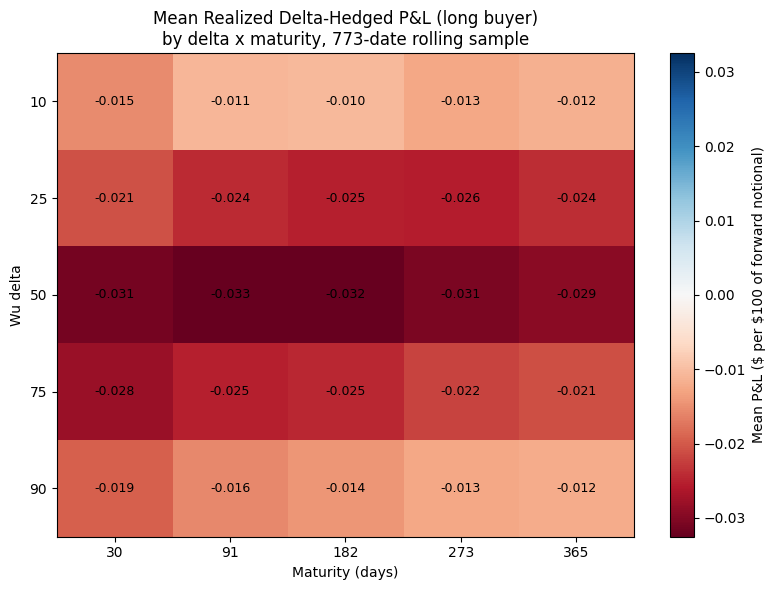

In [55]:
# ─── 7f. Plot: heatmap of the mean realized P&L by delta x maturity ───
pnl_pivot = pnl_summary.pivot(index='wu_delta', columns='days', values='mean')
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(pnl_pivot.values, cmap='RdBu', aspect='auto',
                vmin=-abs(pnl_pivot.values).max(), vmax=abs(pnl_pivot.values).max())
ax.set_xticks(range(len(pnl_pivot.columns)))
ax.set_xticklabels(pnl_pivot.columns)
ax.set_yticks(range(len(pnl_pivot.index)))
ax.set_yticklabels(pnl_pivot.index)
ax.set_xlabel('Maturity (days)')
ax.set_ylabel('Wu delta')
ax.set_title('Mean Realized Delta-Hedged P&L (long buyer)\nby delta x maturity, 773-date rolling sample')
for i in range(pnl_pivot.shape[0]):
    for j in range(pnl_pivot.shape[1]):
        ax.text(j, i, f'{pnl_pivot.values[i, j]:.3f}', ha='center', va='center', fontsize=9)
plt.colorbar(im, ax=ax, label='Mean P&L (\$ per \$100 of forward notional)')
plt.tight_layout()
plt.show()


**Section 7 complete**: the autocorrelation diagnostic on the simulated paths (three initial states, day-demeaned), the true conditional risk-premium surface (`rp_forecast`), and the realized-P&L statistics with statistical inference (HAC, median, percentiles) are now computed, saved, and visualized. Section 8 turns to the formal predictive tests, risk attribution, portfolio strategies, and the comparison against the conventional $VIX^2-RV$ benchmark.

## **8. Expectation Hypothesis, Risk-Premium Attribution, Portfolio Strategies**

Following Wu (2025) §4.2 (expectation hypothesis, eq. 22-23), §4.4.2 (risk-premium attribution, eq. 29), and §5 (portfolio strategies, eq. 30-33). All three parts use ONLY data that already exists (`rolling_panel`: rp_forecast/pnl_realized; `rolling_cov`: the 773 conditional covariance matrices) plus closed-form BMS Greeks (no new Monte Carlo simulation). Deliberately out of scope (an explicit choice, not an omission): risk attribution on the simulated RETURNS path-by-path (Wu's eq. 24/28), which would require re-running the entire rolling loop while storing path-level P&L.

**8a. Closed-form BMS Greeks by date and contract**

In [56]:
# ─── 8a. Closed-form BMS Greeks (dollar vega/gamma/volga/vanna), by date and contract ───
# Rebuilds strike/iv_init/tau_init/r_init as in run_bootstrap_for_date's contract
# construction, but WITHOUT Monte Carlo simulation (closed-form formulas). Gamma,
# vega, vanna, and volga are identical for calls and puts (>=2nd derivatives w.r.t.
# F or sigma, unaffected by put-call parity), so cp_flag does not need to be
# distinguished.
greek_by_date = {}
for td in test_dates_full:
    td_key = td.strftime('%Y-%m-%d')
    if td_key not in rolling_cov:
        continue
    row_greeks = {}
    for _, row in grid_df.iterrows():
        sid = row['series_id']
        tau = row['days'] / 365.0
        if td in iv_panel.index and pd.notna(iv_panel.loc[td, sid]):
            iv_init = iv_panel.loc[td, sid]
        else:
            iv_init = iv_panel[sid].loc[:td].dropna().iloc[-1]
        r_init = get_risk_free_rate(td, tau, yield_curve)
        delta_frac = row['om_delta'] / 100.0
        K = (strike_from_call_delta(F0, delta_frac, iv_init, tau) if row['cp_flag'] == 'C'
             else strike_from_put_delta(F0, delta_frac, iv_init, tau))
        d1 = (np.log(F0 / K) + 0.5 * iv_init ** 2 * tau) / (iv_init * np.sqrt(tau))
        d2 = d1 - iv_init * np.sqrt(tau)
        disc = np.exp(-r_init * tau)
        n_d1 = norm.pdf(d1)
        dollar_vega = disc * F0 * n_d1 * np.sqrt(tau) * iv_init
        dollar_gamma = disc * F0 * n_d1 / (iv_init * np.sqrt(tau))
        dollar_volga = disc * F0 * n_d1 * np.sqrt(tau) * iv_init * d1 * d2
        dollar_vanna = -disc * F0 * n_d1 * d2
        row_greeks[sid] = np.array([dollar_vega, dollar_gamma, dollar_volga, dollar_vanna])
    greek_by_date[td_key] = row_greeks

series_order = list(grid_df['series_id'])
print(f"Greeks computed for {len(greek_by_date)} dates x 25 contracts (closed-form BMS)")


Greeks computed for 773 dates x 25 contracts (closed-form BMS)


**8b. Expectation hypothesis: cross-sectional (eq. 22) and time-series (eq. 23) regressions**

In [57]:
# ─── 8b. Expectation hypothesis: cross-sectional (eq. 22) and time-series (eq. 23) ───
cs_rows = []
for td, g in rolling_panel.groupby('test_date'):
    g = g.set_index('series_id').loc[series_order]
    if len(g) < 5:
        continue
    X = sm.add_constant(g['rp_forecast'].values)
    y = g['pnl_realized'].values
    fit = sm.OLS(y, X).fit()
    cs_rows.append({'test_date': td, 'a_t': fit.params[0], 'b_t': fit.params[1], 'R2_t': fit.rsquared})
cs_df = pd.DataFrame(cs_rows)
cs_path = os.path.join(OUTPUT_DIR_ROLLING, 'tab_eh_cross_sectional.csv')
cs_df.set_index('test_date').to_csv(cs_path)

a_fit = sm.OLS(cs_df['a_t'].values, np.ones(len(cs_df))).fit(cov_type='HAC', cov_kwds={'maxlags': 4})
b_fit = sm.OLS(cs_df['b_t'].values - 1.0, np.ones(len(cs_df))).fit(cov_type='HAC', cov_kwds={'maxlags': 4})
print(f"Cross-sectional (eq. 22), {len(cs_df)} dates: "
      f"mean(a_t)={cs_df['a_t'].mean():.4f} (NW t vs 0: {a_fit.tvalues[0]:.2f}), "
      f"mean(b_t)={cs_df['b_t'].mean():.4f} (NW t vs 1: {b_fit.tvalues[0]:.2f}), "
      f"mean(R2_t)={cs_df['R2_t'].mean():.4f}")

ts_rows = []
for sid, g in rolling_panel.groupby('series_id'):
    X = sm.add_constant(g['rp_forecast'].values)
    y = g['pnl_realized'].values
    fit = sm.OLS(y, X).fit()
    ts_rows.append({'series_id': sid, 'a_k': fit.params[0], 'b_k': fit.params[1], 'R2_k': fit.rsquared})
ts_df = pd.DataFrame(ts_rows)
ts_path = os.path.join(OUTPUT_DIR_ROLLING, 'tab_eh_time_series.csv')
ts_df.set_index('series_id').to_csv(ts_path)
print(f"Time-series (eq. 23), 25 contracts: mean(a_k)={ts_df['a_k'].mean():.4f}, "
      f"mean(b_k)={ts_df['b_k'].mean():.4f} (std={ts_df['b_k'].std():.4f}), "
      f"mean(R2_k)={ts_df['R2_k'].mean():.4f}")


Cross-sectional (eq. 22), 773 dates: mean(a_t)=-0.0139 (NW t vs 0: -1.28), mean(b_t)=0.3285 (NW t vs 1: -4.43), mean(R2_t)=0.2231
Time-series (eq. 23), 25 contracts: mean(a_k)=-0.0032, mean(b_k)=1.7624 (std=0.8978), mean(R2_k)=0.0173


**Interpretation**: the cross-sectional regression (eq. 22) gives a mean $R^2$ of 22.3%, comparable to Wu's ~20% for FX, but with a mean slope of 0.33, significantly below the null value of 1 (Newey-West t=-4.43) — the forecast has a non-zero linear predictive association with the realized return across contracts on a given date (t=2.17 vs. 0), but the slope's deviation from 1 combines imperfect correlation with dispersion differences, and does not by itself identify whether the forecast is over- or under-dispersed. The time-series regression (eq. 23) shows the opposite pattern: low mean $R^2$ (1.7%, close to Wu's 2.3-2.4%), but mean slope 1.76 (std 0.90), ABOVE the null value. The pattern is visually pronounced — the mean slope rises from 0.38 at 30 days to 2.76 at 365 days — but statistically fragile at the individual-contract level: only 1 of the 25 contracts (d10_182d, t=2.00) individually rejects $b=1$, while 16 of 25 reject $b=0$ (14 survive FDR), so most contracts show a real but weak predictive association, not an individually demonstrated calibration. The pooled check in Section 6e ($\beta \approx 1.02$ on all 19,325 observations together) hides this cross-sectional/time-series split by construction.

**8c. Plot: histograms of $a_k$ and $b_k$ (time-series regression)**

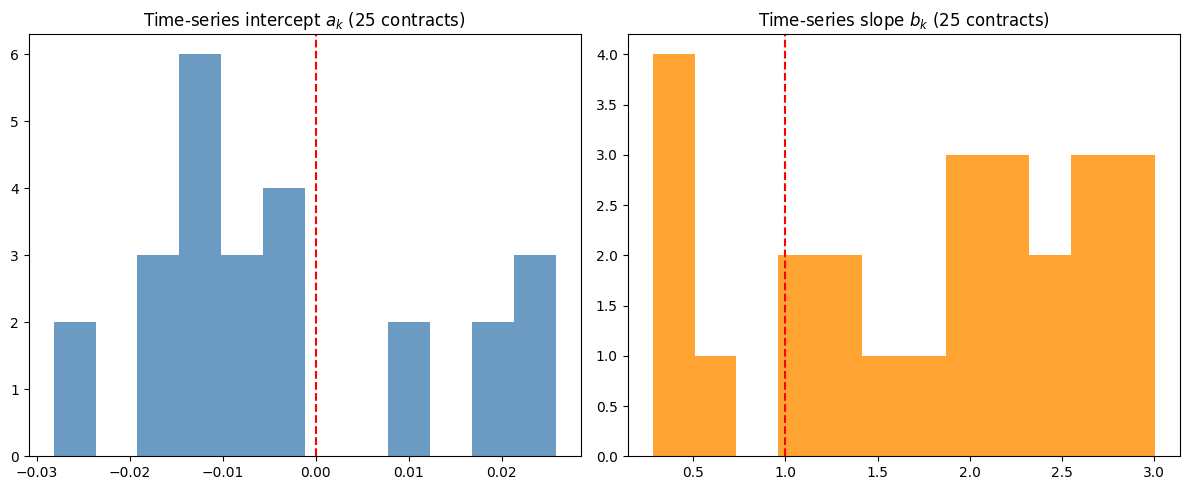

In [58]:
# ─── 8c. Plot: histograms of the time-series intercepts and slopes (25 contracts) ───
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].hist(ts_df['a_k'], bins=12, color='steelblue', alpha=0.8)
axes[0].axvline(0, color='red', linestyle='--')
axes[0].set_title('Time-series intercept $a_k$ (25 contracts)')
axes[1].hist(ts_df['b_k'], bins=12, color='darkorange', alpha=0.8)
axes[1].axvline(1, color='red', linestyle='--')
axes[1].set_title('Time-series slope $b_k$ (25 contracts)')
plt.tight_layout()
plt.show()


**8d. Risk-premium attribution (eq. 29)**

In [59]:
# ─── 8d. Risk-premium attribution: eta_t = X_t phi_t + e, per date, no intercept ───
phi_rows = []
for td, g in rolling_panel.groupby('test_date'):
    td_key = pd.Timestamp(td).strftime('%Y-%m-%d')
    if td_key not in greek_by_date:
        continue
    g = g.set_index('series_id').loc[series_order]
    Xt = np.vstack([greek_by_date[td_key][sid] for sid in series_order])  # 25x4
    eta_t = g['rp_forecast'].values
    phi_t, *_ = np.linalg.lstsq(Xt, eta_t, rcond=None)
    pc = phi_t * (Xt.T @ Xt @ phi_t) / (eta_t @ eta_t) if eta_t @ eta_t > 0 else np.full(4, np.nan)
    phi_rows.append({'test_date': td, 'phi_vega': phi_t[0], 'phi_gamma': phi_t[1],
                      'phi_volga': phi_t[2], 'phi_vanna': phi_t[3],
                      'pc_vega': pc[0], 'pc_gamma': pc[1], 'pc_volga': pc[2], 'pc_vanna': pc[3]})
phi_df = pd.DataFrame(phi_rows)
phi_path = os.path.join(OUTPUT_DIR_ROLLING, 'tab_risk_premium_attribution.csv')
phi_df.set_index('test_date').to_csv(phi_path)
print(f"{len(phi_df)} dates. Mean contribution to the premium's variance (positive=explanatory): "
      f"vega={phi_df['pc_vega'].mean():.3f}  gamma={phi_df['pc_gamma'].mean():.3f}  "
      f"volga={phi_df['pc_volga'].mean():.3f}  vanna={phi_df['pc_vanna'].mean():.3f}  "
      f"(sum={phi_df[['pc_vega','pc_gamma','pc_volga','pc_vanna']].mean().sum():.3f})")


773 dates. Mean contribution to the premium's variance (positive=explanatory): vega=0.303  gamma=0.414  volga=0.014  vanna=0.107  (sum=0.838)


**Interpretation**: the four BMS sensitivities jointly explain about 84% of $\eta_{j,t}$'s uncentered cross-sectional profile on a typical date (sum of squares relative to zero, not variance around the cross-sectional mean — Wu's eq. 30 gives exactly this decomposition), split as gamma 41.4%, vega 30.3%, vanna 10.7%, volga 1.4%. Gamma dominates here, unlike Wu's own result on RETURNS (where vega dominates) but consistent with his own attribution of the short-horizon PREMIUM (his Figure 12, where the text explicitly states that, unlike the return attribution, the short-horizon premium's variation is "chiefly explained by the gamma exposure") — the two are not directly comparable (Wu decomposes the path-by-path return variance, eq. 24/28; here we decompose the forecast's cross-sectional profile alone, eq. 29-30). This within-date regression does NOT explain the unconditional mean surface (Section 7c), whose largest magnitude is at short-dated OTM puts (d10_30d), not the ATM node — it is the REALIZED P&L (Section 7e) that is concentrated at the ATM node, a different object. That gamma explains the cross-sectional dispersion on a given date does not imply the mean forecast must peak on the highest-gamma contract.

**8e. Plot: mean variance contribution to the premium, by risk source**

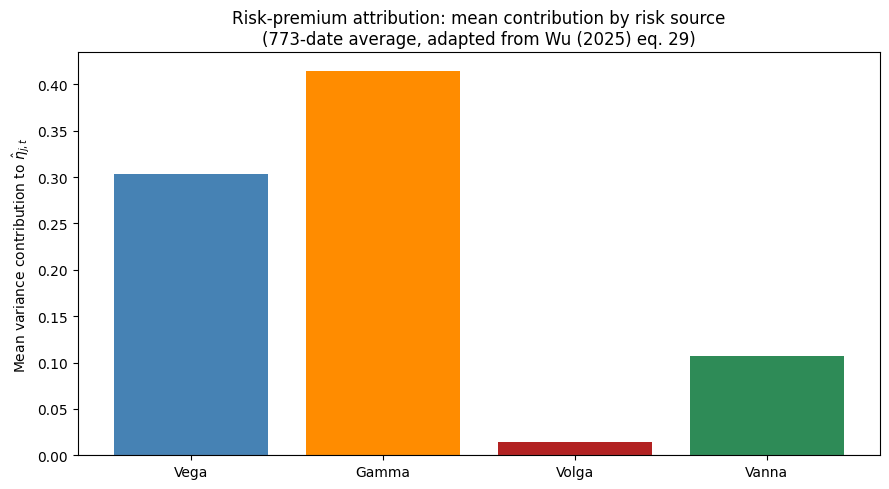

In [60]:
# ─── 8e. Plot: mean variance contribution by risk source ───
fig, ax = plt.subplots(figsize=(9, 5))
pc_means = [phi_df['pc_vega'].mean(), phi_df['pc_gamma'].mean(), phi_df['pc_volga'].mean(), phi_df['pc_vanna'].mean()]
ax.bar(['Vega', 'Gamma', 'Volga', 'Vanna'], pc_means, color=['steelblue', 'darkorange', 'firebrick', 'seagreen'])
ax.axhline(0, color='gray', linewidth=0.8)
ax.set_ylabel('Mean variance contribution to $\\hat\\eta_{j,t}$')
ax.set_title('Risk-premium attribution: mean contribution by risk source\n(773-date average, adapted from Wu (2025) eq. 29)')
plt.tight_layout()
plt.show()


**8f. Portfolio strategies (eq. 30-33)**

In [61]:
# ─── 8f. Portfolio strategies: equal-notional, proportional, mean-variance, vega-neutral ───
port_returns = {k: [] for k in ['equal_notional', 'proportional', 'mean_variance', 'vega_neutral']}
port_dates = []
for td, g in rolling_panel.groupby('test_date'):
    td_key = pd.Timestamp(td).strftime('%Y-%m-%d')
    if td_key not in rolling_cov or td_key not in greek_by_date:
        continue
    g = g.set_index('series_id').loc[series_order]
    eta_t = g['rp_forecast'].values
    realized_t = g['pnl_realized'].values
    Sigma_t = rolling_cov[td_key]
    nu_t = np.array([greek_by_date[td_key][sid][0] for sid in series_order])
    Sigma_inv = np.linalg.pinv(Sigma_t)

    w1 = np.full(25, 100.0)
    w2_raw = eta_t
    w3_raw = Sigma_inv @ eta_t
    denom = nu_t @ Sigma_inv @ nu_t
    proj = Sigma_inv @ (np.eye(25) - np.outer(nu_t, nu_t) @ Sigma_inv / denom) if denom != 0 else Sigma_inv
    w4_raw = proj @ eta_t

    def normalize(w_raw):
        s = np.abs(w_raw).sum()
        return w_raw * (2500.0 / s) if s > 0 else w_raw

    w2, w3, w4 = normalize(w2_raw), normalize(w3_raw), normalize(w4_raw)
    for key, w in [('equal_notional', w1), ('proportional', w2), ('mean_variance', w3), ('vega_neutral', w4)]:
        port_returns[key].append((w * realized_t / 100.0).sum())
    port_dates.append(td)

port_df = pd.DataFrame(port_returns, index=pd.DatetimeIndex(port_dates))
port_path = os.path.join(OUTPUT_DIR_ROLLING, 'tab_portfolio_strategies.csv')
port_df.to_csv(port_path)

ann = np.sqrt(252 / HORIZON_DAYS)
perf_rows = []
for key in port_returns:
    r = port_df[key]
    perf_rows.append({'strategy': key, 'mean_ann': r.mean() * (252 / HORIZON_DAYS),
                       'mean_weekly': r.mean(), 'vol_ann': r.std() * ann,
                       'information_ratio': (r.mean() / r.std()) * ann if r.std() > 0 else np.nan})
perf_df = pd.DataFrame(perf_rows)
perf_path = os.path.join(OUTPUT_DIR_ROLLING, 'tab_portfolio_performance.csv')
perf_df.set_index('strategy').to_csv(perf_path)
print(perf_df[['strategy', 'mean_weekly', 'vol_ann', 'information_ratio']].round(4).to_string(index=False))


      strategy  mean_weekly  vol_ann  information_ratio
equal_notional      -0.5317  57.5065            -0.4660
  proportional       0.7301  52.3641             0.7027
 mean_variance       0.1645   2.8698             2.8884
  vega_neutral       0.1560   2.4600             3.1957


**Interpretation**: the pattern closely reproduces Wu's FX result. The static equal-notional benchmark has a negative mean and an information ratio of -0.47, consistent with the long buyer losing on average across most of the surface (Section 7e). Weighting in proportion to the forecast (automatically shorting negative-eta contracts and going long positive-eta ones) flips the sign, IR=0.70. Incorporating the SAME-DATE conditional covariance matrix (mean-variance) cuts annualized volatility by about 20x (from 57.5 to 2.9) at the cost of a smaller mean, for IR=2.89 (below Wu's range of 2.98-3.77); vega-neutrality further improves to IR=3.20 (within Wu's range of 2.87-3.86). Because weekly P&L is non-normal and serially dependent, these rankings are sample estimates, not compared against bootstrapped confidence intervals (not computed here). See Section 8h for two additional covariance benchmarks that check what drives the mean-variance jump, and Section 8i for the formal comparison against the conventional $VIX^2-RV$ benchmark.

**8g. Plot: information ratio by strategy**

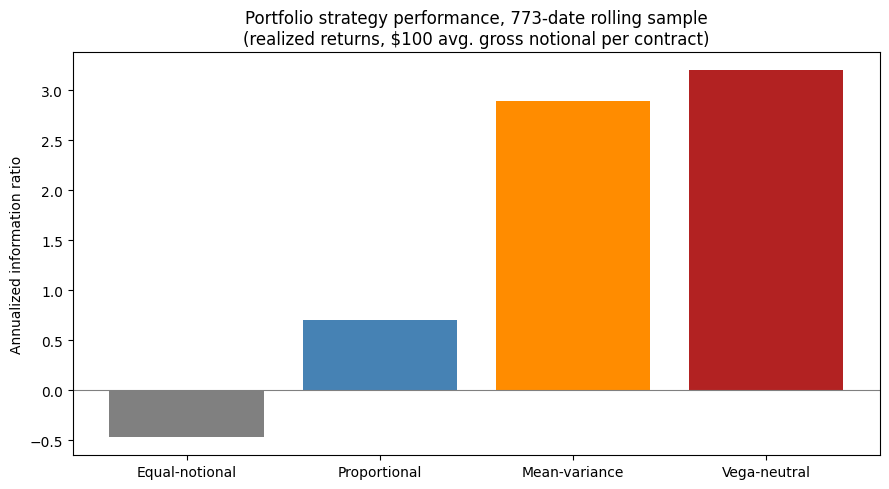

In [62]:
# ─── 8g. Plot: annualized information ratio by strategy ───
fig, ax = plt.subplots(figsize=(9, 5))
labels = ['Equal-notional', 'Proportional', 'Mean-variance', 'Vega-neutral']
irs = perf_df['information_ratio'].values
ax.bar(labels, irs, color=['gray', 'steelblue', 'darkorange', 'firebrick'])
ax.axhline(0, color='gray', linewidth=0.8)
ax.set_ylabel('Annualized information ratio')
ax.set_title('Portfolio strategy performance, 773-date rolling sample\n(realized returns, $100 avg. gross notional per contract)')
plt.tight_layout()
plt.show()


**8h. Covariance benchmarks: diagonal, ex-post oracle, feasible past-only expanding**

In [63]:
# ─── 8h. Covariance benchmarks for the mean-variance strategy ───
# An "unconditional" benchmark built as the mean of all 773 Sigma_t, applied at
# every date, would use FUTURE information for every date before the end of the
# sample -- it is an ex-post oracle, not an implementable strategy. Here: (a) that
# benchmark is kept but explicitly labeled as such (oracle_full_sample), (b) a
# FEASIBLE past-only expanding-window benchmark is added (Sigma_bar_t = mean of
# Sigma_s for s<t, 52-date/~1-year warmup), (c) the diagonal-only benchmark (no
# cross-contract correlation) is kept as well.
cov_dates_sorted = sorted(pd.Timestamp(d) for d in rolling_cov.keys())
Sigma_oracle = np.mean([rolling_cov[d.strftime('%Y-%m-%d')] for d in cov_dates_sorted], axis=0)
Sigma_oracle_inv = np.linalg.pinv(Sigma_oracle)

COV_WARMUP = 52  # ~1 year of prior Wednesdays before the past-only strategy begins
cov_bench_returns = {'diagonal_only': [], 'oracle_full_sample': [], 'past_only_expanding': []}
cov_bench_dates = {'diagonal_only': [], 'oracle_full_sample': [], 'past_only_expanding': []}
running_sum = np.zeros_like(Sigma_oracle)
n_seen = 0

def _normalize(w_raw, total=2500.0):
    s = np.abs(w_raw).sum()
    return w_raw * (total / s) if s > 0 else w_raw

for td, g in rolling_panel.groupby('test_date'):
    td_key = pd.Timestamp(td).strftime('%Y-%m-%d')
    if td_key not in rolling_cov:
        continue
    g = g.set_index('series_id').loc[series_order]
    eta_t = g['rp_forecast'].values
    realized_t = g['pnl_realized'].values
    Sigma_t = rolling_cov[td_key]

    w_diag = _normalize(eta_t / np.diag(Sigma_t))
    cov_bench_returns['diagonal_only'].append((w_diag * realized_t / 100.0).sum())
    cov_bench_dates['diagonal_only'].append(td)

    w_oracle = _normalize(Sigma_oracle_inv @ eta_t)
    cov_bench_returns['oracle_full_sample'].append((w_oracle * realized_t / 100.0).sum())
    cov_bench_dates['oracle_full_sample'].append(td)

    if n_seen >= COV_WARMUP:
        Sigma_bar_inv = np.linalg.pinv(running_sum / n_seen)
        w_po = _normalize(Sigma_bar_inv @ eta_t)
        cov_bench_returns['past_only_expanding'].append((w_po * realized_t / 100.0).sum())
        cov_bench_dates['past_only_expanding'].append(td)
    running_sum = running_sum + Sigma_t
    n_seen += 1

ann = np.sqrt(252 / HORIZON_DAYS)
cov_bench_perf = []
for key in cov_bench_returns:
    r = pd.Series(cov_bench_returns[key], index=pd.DatetimeIndex(cov_bench_dates[key]))
    cov_bench_perf.append({'strategy': key, 'n_dates': len(r), 'mean_ann': r.mean() * (252 / HORIZON_DAYS),
                            'mean_weekly': r.mean(), 'vol_ann': r.std() * ann,
                            'information_ratio': (r.mean() / r.std()) * ann if r.std() > 0 else np.nan})
cov_bench_df = pd.DataFrame(cov_bench_perf)
cov_bench_path = os.path.join(OUTPUT_DIR_ROLLING, 'tab_portfolio_covariance_benchmarks.csv')
cov_bench_df.set_index('strategy').to_csv(cov_bench_path)
print(f"Saved: {os.path.relpath(cov_bench_path)}")
print(f"Warmup for the past-only expanding benchmark: {COV_WARMUP} dates (~1 year of prior Wednesdays)")
print(cov_bench_df.round(4).to_string(index=False))
print("\nNOTE: 'oracle_full_sample' uses the mean of all 773 covariances at EVERY date, "
      "including dates AFTER the test date for all but the last one -- an ex-post "
      "diagnostic, not a feasible strategy. 'past_only_expanding' uses only Sigma_s for "
      "s<t and is feasible.")


Saved: ../output/tab_portfolio_covariance_benchmarks.csv
Warmup for the past-only expanding benchmark: 52 dates (~1 year of prior Wednesdays)
           strategy  n_dates  mean_ann  mean_weekly  vol_ann  information_ratio
      diagonal_only      773   30.4356       0.6039  35.2443             0.8636
 oracle_full_sample      773    8.0828       0.1604   2.3081             3.5019
past_only_expanding      721    8.1947       0.1626   2.5508             3.2126

NOTE: 'oracle_full_sample' uses the mean of all 773 covariances at EVERY date, including dates AFTER the test date for all but the last one -- an ex-post diagnostic, not a feasible strategy. 'past_only_expanding' uses only Sigma_s for s<t and is feasible.


**Interpretation**: the diagonal-only strategy (no cross-contract correlation) performs much worse (IR 0.86) — consistent with cross-contract correlation contributing substantially to the result. The full-sample "oracle" covariance strategy reaches IR 3.50, but for every date before the end of the sample this average is built partly from FUTURE covariances, so it is not a feasible strategy. A genuinely feasible alternative — past-only expanding window, 52-date (~1 year) warmup — reaches IR 3.21, close to both the oracle and the same-date conditional mean-variance strategy of Section 8f (IR 2.89). On solid non-look-ahead footing, this reinforces the qualified reading: covariance structure clearly matters (diagonal-only is much worse), but a STABLE estimate of it — past-only or ex-post — performs at least as well here as re-estimating $\Sigma_{H,t}$ at every date, so the incremental value of the covariance's specific time-variation is not established by this comparison.

**8i. Comparison against the conventional $VRP^{\text{BTZ}}$ benchmark (test of H2)**

In [64]:
# ─── 8i. Encompassing regression with VRP^BTZ (direct test of H2) ───
# The research question is whether the surface-based
# conditional risk premium contains information beyond the conventional aggregate
# benchmark VRP^BTZ_t = VIX_t^2 - RV_t. Adding VRP^BTZ_t as a second regressor to
# the 8b cross-sectional regression is not a valid test: VRP^BTZ_t is constant
# across the 25 contracts on a given date, so it is exactly collinear with the
# date-specific intercept once estimated per-date. The valid test instead uses the
# panel dimension: for each contract, an encompassing regression compared against
# the univariate regression of 8b.
from statsmodels.stats.multitest import multipletests

vrp_matched = df['VRP_seller'].reindex(test_dates_full)
enc_rows = []
for sid in series_order:
    g = rolling_panel[rolling_panel['series_id'] == sid].set_index('test_date').reindex(test_dates_full)
    y = g['pnl_realized'].values
    eta = g['rp_forecast'].values
    vrp = vrp_matched.values
    X = sm.add_constant(np.column_stack([eta, vrp]))
    fit = sm.OLS(y, X, missing='drop').fit(cov_type='HAC', cov_kwds={'maxlags': 4})
    Xu = sm.add_constant(eta)
    fitu = sm.OLS(y, Xu, missing='drop').fit(cov_type='HAC', cov_kwds={'maxlags': 4})
    # VRP-only regression: quantifies "the reverse does not hold" with a number,
    # not just an assertion -- how much VRP^BTZ explains on its own, without eta.
    Xv = sm.add_constant(vrp)
    fitv = sm.OLS(y, Xv, missing='drop').fit(cov_type='HAC', cov_kwds={'maxlags': 4})
    enc_rows.append({'series_id': sid, 'b_eta': fit.params[1], 't_eta': fit.tvalues[1], 'p_eta': fit.pvalues[1],
                      'c_vrp': fit.params[2], 't_vrp': fit.tvalues[2], 'p_vrp': fit.pvalues[2],
                      'R2_encompass': fit.rsquared, 'R2_univariate_eta': fitu.rsquared,
                      'R2_univariate_vrp': fitv.rsquared, 'b_vrp_only': fitv.params[1], 't_vrp_only': fitv.tvalues[1]})
enc_df = pd.DataFrame(enc_rows)
_, enc_df['q_eta'], _, _ = multipletests(enc_df['p_eta'], alpha=0.05, method='fdr_bh')
_, enc_df['q_vrp'], _, _ = multipletests(enc_df['p_vrp'], alpha=0.05, method='fdr_bh')
enc_path = os.path.join(OUTPUT_DIR_ROLLING, 'tab_vrp_encompassing.csv')
enc_df.set_index('series_id').to_csv(enc_path)
print(f"Saved: {os.path.relpath(enc_path)}")
print(f"Mean R2: eta-only={enc_df['R2_univariate_eta'].mean():.4f}  vrp-only={enc_df['R2_univariate_vrp'].mean():.4f}  "
      f"encompassing={enc_df['R2_encompass'].mean():.4f}")
print(f"|t_vrp|>1.96 (encompassing): {(enc_df['t_vrp'].abs() > 1.96).sum()}/25  |  |t_eta|>1.96: {(enc_df['t_eta'].abs() > 1.96).sum()}/25")
print(f"|t_vrp_only|>1.96 (VRP alone): {(enc_df['t_vrp_only'].abs() > 1.96).sum()}/25")
print(f"FDR q<0.05: eta {(enc_df['q_eta'] < 0.05).sum()}/25  |  vrp {(enc_df['q_vrp'] < 0.05).sum()}/25")


Saved: ../output/tab_vrp_encompassing.csv
Mean R2: eta-only=0.0173  vrp-only=0.0015  encompassing=0.0187
|t_vrp|>1.96 (encompassing): 0/25  |  |t_eta|>1.96: 16/25
|t_vrp_only|>1.96 (VRP alone): 2/25
FDR q<0.05: eta 11/25  |  vrp 0/25


**Interpretation**: the result is unambiguous: $VRP^{\text{BTZ}}_t$'s coefficient is not individually significant for ANY of the 25 contracts at 5% (HAC, $|t|<1.96$ everywhere; 0/25 survive FDR by construction), improving the mean $R^2$ only marginally (1.73% -> 1.87%). $\eta_{j,t}$'s coefficient remains significant for 16/25 raw (11/25 after FDR), essentially unchanged from the univariate regression of 8b. "The reverse does not hold" is confirmed with a number too, not just an assertion: $VRP^{\text{BTZ}}_t$ alone explains almost nothing (mean univariate $R^2$ 0.15%, only 2/25 contracts individually significant), an order of magnitude below $\eta_{j,t}$'s own univariate $R^2$ (1.73%). There is no detectable incremental contribution at the contract level from the aggregate benchmark once the surface-based forecast is included, while the surface-based forecast retains a predictive association for most contracts — evidence in favor of H2, not a definitive rejection of $VRP^{\text{BTZ}}_t$. These are per-contract time-series tests: they do not separately isolate how much of the surface's advantage comes from its CROSS-SECTIONAL richness, since the aggregate benchmark has no per-contract dimension to compare against.

**8j. Common-sample comparison and covariance stability diagnostics**

In [65]:
# ─── 8j. Common-sample comparison (773 vs. 721) + Sigma_t diagnostics ───
# (a) The past-only benchmark (8h) starts 52 dates after the primary strategies
# (8f/8h), so a direct IR comparison partly conflates the covariance estimator with
# the evaluation window -- all strategies are recomputed on the common post-warmup
# sample. (b) the mean-variance strategy's very high IR calls for a numerical-
# stability check: condition number, weight concentration, sensitivity to ridge
# shrinkage of Sigma_t.
common_rows = {k: [] for k in ['equal_notional', 'proportional', 'mean_variance', 'vega_neutral',
                                'diagonal_only', 'oracle_full_sample', 'past_only_expanding']}
n_seen_g = 0
running_sum_g = np.zeros_like(Sigma_oracle)
cond_numbers, min_eigs, max_weight_shares = [], [], []
shrink_lambdas = [0.01, 0.05, 0.10]
shrink_returns = {lam: [] for lam in shrink_lambdas}
unshrunk_returns = []

for td, g in rolling_panel.groupby('test_date'):
    td_key = pd.Timestamp(td).strftime('%Y-%m-%d')
    if td_key not in rolling_cov or td_key not in greek_by_date:
        continue
    g = g.set_index('series_id').loc[series_order]
    eta_t = g['rp_forecast'].values
    realized_t = g['pnl_realized'].values
    Sigma_t = rolling_cov[td_key]
    Sigma_inv = np.linalg.pinv(Sigma_t)
    nu_t = np.array([greek_by_date[td_key][sid][0] for sid in series_order])

    eigvals = np.linalg.eigvalsh(Sigma_t)
    min_eigs.append(eigvals.min())
    cond_numbers.append(eigvals.max() / eigvals.min() if eigvals.min() > 0 else np.inf)

    def normalize(w_raw, total=2500.0):
        s = np.abs(w_raw).sum()
        return w_raw * (total / s) if s > 0 else w_raw

    w3 = normalize(Sigma_inv @ eta_t)
    max_weight_shares.append(np.abs(w3).max() / 2500.0)
    unshrunk_returns.append((w3 * realized_t / 100.0).sum())
    tr = np.trace(Sigma_t) / 25
    for lam in shrink_lambdas:
        Sigma_s = (1 - lam) * Sigma_t + lam * tr * np.eye(25)
        w_s = normalize(np.linalg.pinv(Sigma_s) @ eta_t)
        shrink_returns[lam].append((w_s * realized_t / 100.0).sum())

    if n_seen_g >= COV_WARMUP:
        Sigma_bar_inv = np.linalg.pinv(running_sum_g / n_seen_g)
        w_diag = normalize(eta_t / np.diag(Sigma_t))
        w_oracle = normalize(Sigma_oracle_inv @ eta_t)
        w_po = normalize(Sigma_bar_inv @ eta_t)
        denom = nu_t @ Sigma_inv @ nu_t
        proj = Sigma_inv @ (np.eye(25) - np.outer(nu_t, nu_t) @ Sigma_inv / denom) if denom != 0 else Sigma_inv
        w4 = normalize(proj @ eta_t)
        common_rows['equal_notional'].append((np.full(25, 100.0) * realized_t / 100.0).sum())
        common_rows['proportional'].append((normalize(eta_t) * realized_t / 100.0).sum())
        common_rows['mean_variance'].append((w3 * realized_t / 100.0).sum())
        common_rows['vega_neutral'].append((w4 * realized_t / 100.0).sum())
        common_rows['diagonal_only'].append((w_diag * realized_t / 100.0).sum())
        common_rows['oracle_full_sample'].append((w_oracle * realized_t / 100.0).sum())
        common_rows['past_only_expanding'].append((w_po * realized_t / 100.0).sum())
    running_sum_g = running_sum_g + Sigma_t
    n_seen_g += 1

common_perf = []
for key, vals in common_rows.items():
    r = pd.Series(vals)
    common_perf.append({'strategy': key, 'n_dates': len(r), 'mean_weekly': r.mean(), 'vol_ann': r.std() * ann,
                         'information_ratio': (r.mean() / r.std()) * ann if r.std() > 0 else np.nan})
common_perf_df = pd.DataFrame(common_perf)
common_path = os.path.join(OUTPUT_DIR_ROLLING, 'tab_portfolio_common_sample.csv')
common_perf_df.set_index('strategy').to_csv(common_path)
print(f"Saved: {os.path.relpath(common_path)}")
print(f"Common post-warmup sample: {len(common_rows['mean_variance'])} dates")
print(common_perf_df.round(4).to_string(index=False))

min_eigs = np.array(min_eigs); cond_numbers = np.array(cond_numbers); max_weight_shares = np.array(max_weight_shares)
cond_rows = [{'diagnostic': 'min_eigenvalue_min', 'value': min_eigs.min()},
             {'diagnostic': 'min_eigenvalue_median', 'value': np.median(min_eigs)},
             {'diagnostic': 'min_eigenvalue_max', 'value': min_eigs.max()},
             {'diagnostic': 'condition_number_min', 'value': cond_numbers.min()},
             {'diagnostic': 'condition_number_median', 'value': np.median(cond_numbers)},
             {'diagnostic': 'condition_number_max', 'value': cond_numbers.max()},
             {'diagnostic': 'n_non_psd', 'value': (min_eigs < 0).sum()},
             {'diagnostic': 'max_weight_share_mean', 'value': max_weight_shares.mean()},
             {'diagnostic': 'max_weight_share_median', 'value': np.median(max_weight_shares)},
             {'diagnostic': 'max_weight_share_max', 'value': max_weight_shares.max()}]
r0 = pd.Series(unshrunk_returns)
cond_rows.append({'diagnostic': 'mean_variance_IR_unshrunk', 'value': (r0.mean() / r0.std()) * ann})
for lam in shrink_lambdas:
    r = pd.Series(shrink_returns[lam])
    cond_rows.append({'diagnostic': f'mean_variance_IR_shrink_{lam}', 'value': (r.mean() / r.std()) * ann})
cond_df = pd.DataFrame(cond_rows)
cond_path = os.path.join(OUTPUT_DIR_ROLLING, 'tab_covariance_diagnostics.csv')
cond_df.set_index('diagnostic').to_csv(cond_path)
print(f"\nSaved: {os.path.relpath(cond_path)}")
print(f"Condition number: median={np.median(cond_numbers):.1f}  range=[{cond_numbers.min():.1f}, {cond_numbers.max():.1f}]")
print(f"Max |weight|/gross notional: mean={max_weight_shares.mean():.3f}  max={max_weight_shares.max():.3f}")
print(f"Mean-variance IR: unshrunk={cond_rows[10]['value']:.4f}  "
      + "  ".join(f"shrink({lam})={cond_rows[11+i]['value']:.4f}" for i, lam in enumerate(shrink_lambdas)))


Saved: ../output/tab_portfolio_common_sample.csv
Common post-warmup sample: 721 dates
           strategy  n_dates  mean_weekly  vol_ann  information_ratio
     equal_notional      721      -0.5673  55.9696            -0.5108
       proportional      721       0.7791  48.9373             0.8023
      mean_variance      721       0.1578   2.8671             2.7744
       vega_neutral      721       0.1492   2.4396             3.0828
      diagonal_only      721       0.6574  30.2962             1.0937
 oracle_full_sample      721       0.1542   2.2962             3.3849
past_only_expanding      721       0.1626   2.5508             3.2126

Saved: ../output/tab_covariance_diagnostics.csv
Condition number: median=16019.9  range=[8512.8, 36009.1]
Max |weight|/gross notional: mean=0.182  max=0.344
Mean-variance IR: unshrunk=2.8884  shrink(0.01)=2.4233  shrink(0.05)=1.9959  shrink(0.1)=1.6810


**Interpretation**: on the common post-warmup sample (721 dates), the strategies' qualitative ordering survives (diagonal-only worst, past-only/oracle close together at the top), but the point IRs shift: mean-variance 2.89->2.77, diagonal-only 0.86->1.09, oracle 3.50->3.38, past-only unchanged at 3.21 — so the original comparison was not an artifact of sample misalignment. The 773 conditional covariance matrices have a median condition number of 16,020 (range 8,513-36,009, no negative eigenvalues, hence not numerically degenerate), and the mean-variance weights place on average 18% (max 34%) of gross notional on a single contract — concentrated for a 25-contract grid, but not degenerate. The most substantial finding: shrinking $\Sigma_t$ toward a scaled identity ($\lambda=0.01/0.05/0.10$) drops the mean-variance IR from 2.89 (unshrunk) to 2.42/2.00/1.68 — a real, non-negligible sensitivity to regularization, so the reported IR should be read as what the exact sample covariance estimate supports, not as a result robust to regularization choices.

**Section 8 complete**: the expectation hypothesis (cross-sectional and time-series), risk attribution of the conditional premium (vega/gamma/volga/vanna), portfolio strategies with information ratios (including the ex-post "oracle" and the feasible past-only covariance benchmarks of Section 8h), the formal comparison against the conventional $VIX^2-RV$ benchmark with the added VRP-only regression (Section 8i, the direct test of H2), and the common-sample comparison with covariance stability diagnostics (Section 8j) are now computed, saved, and visualized. Not implemented (possible extensions): risk attribution on the bootstrapped returns path-by-path (Wu eq. 24/28), which requires storing path-level P&L in the rolling loop; premium-normalized EH regressions (needs $C_0$ for all 773x25 cells); a joint fixed-effects panel test with two-way robust inference, for both the EH tests and the VRP^BTZ encompassing regression; bootstrapped confidence intervals for the information ratios; and analysis of the TEMPORAL (not just mean) structure of the conditional covariance matrices.